# The NEXUS Ring Atlas

**An executable observatory of the native binary rings, from one bit to the retained continuation domain**

Dean A. Kulik · QuHarmonics Research Group · ORCID 0009-0003-3128-8828 · November 2026

Run **Restart Kernel and Run All** once. With the long runs on, the notebook takes about two minutes; every figure, table and status below is computed in the cells, and nothing is typed in by hand. Cells marked ◆ are live explorers.

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────────────
RUN_LONG = True       # run the two-lap closure in full (about 50 seconds of pure Python); False skips those checks

import importlib, subprocess, sys, types
_missing = [pkg for mod, pkg in (("numpy", "numpy"), ("plotly", "plotly"), ("ipywidgets", "ipywidgets"), ("PIL", "pillow"))
            if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import plotly.io as pio
try:
    import google.colab  # noqa: F401
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "plotly_mimetype+notebook_connected"   # JupyterLab / VS Code, plus an HTML fallback

def _load_engine(name, src):
    m = types.ModuleType(name)
    m.__file__ = name + ".py (embedded in this notebook)"
    sys.modules[name] = m
    exec(compile(src, name + ".py", "exec"), m.__dict__)
    return m

print("setup ready · RUN_LONG =", RUN_LONG)

setup ready · RUN_LONG = True


In [2]:
# ENGINE A · ring_core: the mathematics (no graphics)
_rc = r'''"""NEXUS Ring Atlas - mathematical core.

Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828.
Pure Python + numpy. No graphics: every function here runs with the plotting layer switched off.

Conventions
  A word x of width n is an integer; bit i is the coefficient of 2**i; words are written MSB first.
  J = reversal, C = complement, u = 2**n - 1, N = 2**n, M = N // 2.
  P(x) = J(x) if J(x) != x else C(x)                      (the native partner)
  R_n: representatives (x < P(x)) ascend in slots 0..M-1, P(R_n[i]) sits in slot N-1-i,
       slots M-1 and M are exchanged (n >= 2).  The slot of x is its address.
"""
from __future__ import annotations

import hashlib
import json
import math
import random
from collections import Counter
from fractions import Fraction
from functools import lru_cache

import numpy as np

__version__ = "1.0.0"

# Ledger words.  ELSEWHERE replaces the older DEAD END: the computation ran and landed,
# and the landing belongs to a named owner.  Rename here and every panel follows.
STANDS, RUNS, OPEN, PULL, ELSEWHERE = "STANDS", "RUNS", "OPEN", "PULL", "ELSEWHERE"
LEDGER = (STANDS, RUNS, OPEN, PULL, ELSEWHERE)
LEDGER_MEANING = {
    STANDS: "proved, or supplied by a cited theorem",
    RUNS: "an executed readout landed where the derivation placed it; scope stated",
    OPEN: "the shape of the missing link is fixed; the link is not yet written",
    PULL: "a reading of the domain at a physical or human location, held as a comparator",
    ELSEWHERE: "the computation ran and landed; the landing belongs to the named owner (arrow)",
}

# ----------------------------------------------------------------------------------------
# 1. Words
# ----------------------------------------------------------------------------------------

def umask(n: int) -> int:
    return (1 << n) - 1


def rev(x: int, n: int) -> int:
    """J: reverse the n bits of x (exact at any width)."""
    if n <= 0:
        return 0
    return int(format(x, "0%db" % n)[::-1], 2)


def comp(x: int, n: int) -> int:
    """C: complement."""
    return x ^ umask(n)


def is_pal(x: int, n: int) -> bool:
    return rev(x, n) == x


def partner(x: int, n: int) -> int:
    """P: reversal off the palindromes, complement on them."""
    j = rev(x, n)
    return (x ^ umask(n)) if j == x else j


def wt(x: int) -> int:
    return bin(x).count("1")


def bits(x: int, n: int) -> str:
    """MSB-first bit string."""
    return format(x, "0%db" % n) if n > 0 else ""


def parse_word(s, n=None):
    """Accept an int or a string: '0b1011', '0x2f', '0d47', plain binary ('1011'), or decimal ('47').
    A string of 0s and 1s is read as binary; its width is its length unless n is given.
    Returns (x, n)."""
    if isinstance(s, (int, np.integer)):
        x = int(s)
        if n is None:
            n = max(1, x.bit_length())
        if x >= (1 << n) or x < 0:
            raise ValueError("value %d does not fit in %d bits" % (x, n))
        return x, n
    t = str(s).strip().replace("_", "").replace(" ", "").lower()
    if t.startswith("0b"):
        body = t[2:]
        x = int(body, 2)
        w = len(body)
    elif t.startswith("0x"):
        body = t[2:]
        x = int(body, 16)
        w = 4 * len(body)
    elif t.startswith("0d"):
        x = int(t[2:])
        w = max(1, x.bit_length())
    elif t and set(t) <= {"0", "1"}:
        x = int(t, 2)
        w = len(t)
    else:
        x = int(t)
        w = max(1, x.bit_length())
    if n is None:
        n = w
    if x >= (1 << n):
        raise ValueError("value does not fit in %d bits" % n)
    return x, n


def rev_vec(a, n: int):
    a = np.asarray(a, dtype=np.int64)
    r = np.zeros_like(a)
    for i in range(n):
        r |= ((a >> i) & 1) << (n - 1 - i)
    return r


def popcount_vec(a):
    a = np.asarray(a, dtype=np.int64)
    c = np.zeros_like(a)
    while np.any(a):
        c += a & 1
        a = a >> 1
    return c


@lru_cache(maxsize=64)
def partner_table(n: int) -> np.ndarray:
    N = 1 << n
    w = np.arange(N, dtype=np.int64)
    j = rev_vec(w, n)
    t = np.where(j == w, w ^ (N - 1), j)
    t.setflags(write=False)
    return t


@lru_cache(maxsize=64)
def pal_table(n: int) -> np.ndarray:
    w = np.arange(1 << n, dtype=np.int64)
    t = rev_vec(w, n) == w
    t.setflags(write=False)
    return t


# ----------------------------------------------------------------------------------------
# 2. The ring
# ----------------------------------------------------------------------------------------

@lru_cache(maxsize=64)
def ring(n: int) -> np.ndarray:
    """R_n as an int64 array (n <= 26)."""
    if n < 1:
        raise ValueError("width must be >= 1")
    N = 1 << n
    M = N // 2
    w = np.arange(N, dtype=np.int64)
    p = partner_table(n)
    reps = w[w < p]
    R = np.empty(N, dtype=np.int64)
    R[:M] = reps
    R[N - 1 - np.arange(M)] = p[reps]
    if n >= 2:
        a, b = int(R[M - 1]), int(R[M])
        R[M - 1], R[M] = b, a
    R.setflags(write=False)
    return R


@lru_cache(maxsize=64)
def address_table(n: int) -> np.ndarray:
    R = ring(n)
    A = np.empty_like(R)
    A[R] = np.arange(len(R), dtype=np.int64)
    A.setflags(write=False)
    return A


@lru_cache(maxsize=64)
def tape_bits(n: int) -> np.ndarray:
    """T_n as a uint8 array of n * 2**n slices: ring words in slot order, each MSB first."""
    R = ring(n)
    sh = np.arange(n - 1, -1, -1, dtype=np.int64)
    t = ((R[:, None] >> sh[None, :]) & 1).astype(np.uint8).reshape(-1)
    t.setflags(write=False)
    return t


def seam_word(n: int) -> int:
    """R_n[M] = 1^(floor(n/2)-1) 0 1^(ceil(n/2)) for n >= 2 (Mapping the Nested Partner Ring, §5)."""
    a, b = n // 2 - 1, (n + 1) // 2
    return int("1" * a + "0" + "1" * b, 2)


# ---- exact address at any width (digit DP over mirror pairs, outside in) ----------------

def _sgn(a: int, b: int) -> int:
    return (a > b) - (a < b)


def _dp_counts(p: int, n: int, pal_only: bool) -> int:
    """pal_only=False: #{x : x < p <= J(x)} (= Delta(p));  pal_only=True: #{palindromes x < p}."""
    h = n // 2
    pb = [(p >> i) & 1 for i in range(n)]
    states = {(0, 0, 0, 0): 1}
    for k in range(h):
        P_hi = pb[n - 1 - k]
        P_lo = pb[k]
        new = {}
        pairs = ((0, 0), (1, 1)) if pal_only else ((0, 0), (0, 1), (1, 0), (1, 1))
        for (hx, hj, lx, lj), cnt in states.items():
            for a, b in pairs:          # a = x_{n-1-k}, b = x_k
                nhx = hx if hx else _sgn(a, P_hi)
                if nhx > 0:
                    continue
                nlx = lx if b == P_lo else _sgn(b, P_lo)
                if nhx < 0:
                    nlx = 0
                if pal_only:
                    key = (nhx, 0, nlx, 0)
                else:
                    nhj = hj if hj else _sgn(b, P_hi)
                    if nhj < 0:
                        continue
                    nlj = lj if a == P_lo else _sgn(a, P_lo)
                    if nhj > 0:
                        nlj = 0
                    key = (nhx, nhj, nlx, nlj)
                new[key] = new.get(key, 0) + cnt
        states = new
    total = 0
    mids = (0, 1) if n % 2 else (None,)
    for (hx, hj, lx, lj), cnt in states.items():
        for c in mids:
            cm = 0 if c is None else _sgn(c, pb[h])
            cx = hx or cm or lx
            if pal_only:
                if cx < 0:
                    total += cnt
            else:
                cj = hj or cm or lj
                if cx < 0 and cj >= 0:
                    total += cnt
    return total


def pal_below(p: int, n: int) -> int:
    """pi(p): palindromes below p."""
    return _dp_counts(p, n, True)


def delta(p: int, n: int) -> int:
    """Delta(p) = sum_{x<p} sgn(J(x) - x) = #{x : x < p <= J(x)}   (Against Its Own Reverse)."""
    return _dp_counts(p, n, False)


def reps_below(p: int, n: int) -> int:
    """rank(p) = (p - pi(p) + Delta(p))/2 + min(pi(p), 2^(ceil(n/2)-1))   (1.7)."""
    pi = pal_below(p, n)
    d = delta(p, n)
    return (p - pi + d) // 2 + min(pi, 1 << ((n + 1) // 2 - 1))


def address(x: int, n: int) -> int:
    """Exact slot of x on R_n at any width (Python integers)."""
    N = 1 << n
    M = N >> 1
    px = partner(x, n)
    a = reps_below(x, n) if x < px else N - 1 - reps_below(px, n)
    if n >= 2 and a in (M - 1, M):
        a = 2 * M - 1 - a
    return a


def word_at(a: int, n: int) -> int:
    """Inverse of address: R_n[a] at any width."""
    N = 1 << n
    M = N >> 1
    if not 0 <= a < N:
        raise ValueError("address out of range")
    if n >= 2 and a in (M - 1, M):
        a = 2 * M - 1 - a
    if a >= M:
        return partner(word_at_pre(N - 1 - a, n), n)
    return word_at_pre(a, n)


def word_at_pre(a: int, n: int) -> int:
    """a-th representative in ascending order (before the seam exchange)."""
    lo, hi = 0, (1 << n) - 1
    while lo < hi:                       # largest p with reps_below(p) <= a
        mid = (lo + hi + 1) >> 1
        if reps_below(mid, n) <= a:
            lo = mid
        else:
            hi = mid - 1
    return lo


def ring_word(a: int, n: int) -> int:
    """R_n[a]: table lookup when small, exact unrank when large."""
    if n <= 16:
        return int(ring(n)[a])
    return word_at(a, n)


def face(a: int, n: int) -> int:
    return int(a >= (1 << (n - 1)))


def comparator(x: int, n: int) -> int:
    """c(x) = sgn(J(x) - x)."""
    return _sgn(rev(x, n), x)


def borrow_chain(a: int, b: int, n: int):
    """Subtract b from a bit by bit, LSB first, with the borrow cell beta' = Maj(not a_i, b_i, beta).
    Returns rows (i, a_i, b_i, beta_in, beta_out); the final beta_out is [a < b]."""
    rows = []
    beta = 0
    for i in range(n):
        ai, bi = (a >> i) & 1, (b >> i) & 1
        na = 1 - ai
        out = (na & bi) | (na & beta) | (bi & beta)
        rows.append((i, ai, bi, beta, out))
        beta = out
    return rows


def comparator_ring_law(n: int) -> np.ndarray:
    """c_R(i) = chi_top(i) * (1 - pal(i) - 2[i in {M-1, M}])   (1.9)."""
    N = 1 << n
    M = N // 2
    R = ring(n)
    pal = pal_table(n)[R].astype(np.int64)
    chi = np.where(np.arange(N) < M, 1, -1)
    seam = np.zeros(N, dtype=np.int64)
    if n >= 2:
        seam[[M - 1, M]] = 1
    return chi * (1 - pal - 2 * seam)


# ----------------------------------------------------------------------------------------
# 3. Geometry readings of the ring: sphere, folded square, parabola, depth, merge
# ----------------------------------------------------------------------------------------

def sphere_coords(n: int):
    """Azimuth of the address, polar angle from weight: cos(theta) = 1 - 2 wt/n  (1.10, 7.2)."""
    R = ring(n)
    N = len(R)
    a = np.arange(N)
    phi = 2 * np.pi * (a + 0.5) / N
    w = popcount_vec(R)
    cos_t = 1 - 2 * w / n
    sin_t = np.sqrt(np.clip(1 - cos_t ** 2, 0, None))
    return dict(x=sin_t * np.cos(phi), y=sin_t * np.sin(phi), z=cos_t, phi=phi, wt=w, words=R, addr=a)


def folded_square(n: int):
    """Even n = 2h: x = f || g  ->  (f / 2^h, J(g) / 2^h).  Partner = mirror across the diagonal."""
    if n % 2:
        raise ValueError("folded square: use an even width (odd widths carry two sheets)")
    h = n // 2
    w = np.arange(1 << n, dtype=np.int64)
    f = w >> h
    g = w & ((1 << h) - 1)
    jg = rev_vec(g, h)
    return dict(phi=f / (1 << h), gamma=jg / (1 << h), words=w)


def parabola_residual(n: int):
    """Representatives at (t = value/N, u = address/N); returns t, u, residual u - (t - t^2/2)."""
    N = 1 << n
    A = address_table(n)
    p = partner_table(n)
    w = np.arange(N, dtype=np.int64)
    reps = w[w < p]
    t = reps / N
    u = A[reps] / N
    return t, u, u - (t - t * t / 2)


def tent_Q(f: int, h: int) -> Fraction:
    """Q(f) = f 2^h - f^2/2 + (1/2) min(f, 2^h - f)  (Where Yes and No Become Maybe, Route 7)."""
    H = 1 << h
    return Fraction(f * H) - Fraction(f * f, 2) + Fraction(min(f, H - f), 2)


def depth(x: int, n: int):
    """Continuation depth of a representative: strip F-frames from the outside.
    F(a) = min(1a1, P(1a1)): reversal branch 1a1 (a non-palindromic rep),
    complement branch 0C(a)0 (a palindromic rep).  Returns (depth, root, root_width)."""
    d, L = 0, n
    while L >= 3:
        b = (x >> (L - 1)) & 1
        c = x & 1
        m = (x >> 1) & umask(L - 2)
        if b == 1 and c == 1:
            jm = rev(m, L - 2)
            if jm != m and m < jm:
                x, L, d = m, L - 2, d + 1
                continue
        elif b == 0 and c == 0:
            if rev(m, L - 2) == m and (m >> (L - 3)) & 1:
                x, L, d = m ^ umask(L - 2), L - 2, d + 1
                continue
        break
    return d, x, L


def F_power(root: int, w: int, k: int):
    """Closed-form continuation codec: F^k(rho).  Non-palindromic root -> 1^k rho 1^k;
    palindromic root -> a_k X a_k^R with a_k = first k bits of 0101..., X = rho (k even) or C(rho) (k odd)."""
    if rev(root, w) != root:
        s = "1" * k + bits(root, w) + "1" * k
    else:
        ak = ("01" * (k // 2 + 1))[:k]
        X = root if k % 2 == 0 else comp(root, w)
        s = ak + bits(X, w) + ak[::-1]
    return int(s, 2), w + 2 * k


def F_step(a: int, w: int):
    x = int("1" + bits(a, w) + "1", 2)
    return min(x, partner(x, w + 2)), w + 2


def merge_grey(n: int) -> int:
    """Sum over all words of wt(x xor P(x))."""
    w = np.arange(1 << n, dtype=np.int64)
    return int(popcount_vec(w ^ partner_table(n)).sum())


# ----------------------------------------------------------------------------------------
# 4. Readers of the fixed mold: radial reader, tape frames, radial language, witness angle
# ----------------------------------------------------------------------------------------

def radial_read(u, D: int, width: int = 1, start_ring: int = 1):
    """Radial reader (Mapping the Nested Partner Ring, §2): on ring L read slice floor(L {2^L u})
    of R_L[floor(2^L u)], counted from the MSB.  width > 1 reads that many consecutive slices of
    the ring's tape (crossing into the next word when needed).  u is a Fraction (exact)."""
    u = Fraction(u) % 1
    out = []
    for L in range(start_ring, D + 1):
        z = u * (1 << L)
        slot = z.numerator // z.denominator
        fr = z - slot
        y = fr * L
        bitpos = y.numerator // y.denominator
        read = []
        s, b = slot, bitpos
        N = 1 << L
        for _ in range(width):
            word = ring_word(s, L)
            read.append((word >> (L - 1 - b)) & 1)
            b += 1
            if b == L:
                b, s = 0, (s + 1) % N
        word0 = ring_word(slot, L)
        out.append(dict(ring=L, slot=slot, bit=bitpos, word=word0, read=read))
    return out


def tape_windows(L: int, s: int, width: int = None):
    """w_i(s) = (R[i] mod 2^(L-s)) 2^s + floor(R[i+1] / 2^(L-s)): the L-bit window s slices into slot i."""
    R = ring(L).astype(np.int64)
    if width is None or width == L:
        nxt = np.roll(R, -1)
        return (R & ((1 << (L - s)) - 1)) * (1 << s) + (nxt >> (L - s))
    t = tape_bits(L)
    T = len(t)
    idx = (np.arange(1 << L)[:, None] * L + s + np.arange(width)[None, :]) % T
    sh = np.arange(width - 1, -1, -1)
    return (t[idx].astype(np.int64) << sh).sum(axis=1)


def frame_loss(L: int, s: int) -> int:
    w = tape_windows(L, s)
    return (1 << L) - len(np.unique(w))


def frame_law(L: int, s: int) -> int:
    """Loss of frame s (Mapping the Nested Partner Ring, §4)."""
    h = L // 2
    P = 1 << ((L + 1) // 2)
    if s <= 1:
        return 0
    if 2 <= s <= h - 1:
        return P - (P >> (s - 2))          # P (1 - 2^(2-s))
    if s == h:
        return P - 2 if L % 2 == 0 else P - 6
    if h + 1 <= s <= L - 2:
        return P - 2 - (1 << (s - h + 1))
    return P - 2                           # s = L - 1


def radial_language(D: int):
    """Distinct radial profiles R_D and the angular entropy, by merging every slice boundary of
    rings 1..D on one integer grid (exact).  D <= 16."""
    if D > 16:
        raise ValueError("D <= 16 keeps the integer grid inside int64")
    G = math.lcm(*range(1, D + 1)) * (1 << D)
    bnds = [np.arange(L * (1 << L), dtype=np.int64) * (G // (L * (1 << L))) for L in range(1, D + 1)]
    b = np.unique(np.concatenate(bnds + [np.array([G], dtype=np.int64)]))
    left = b[:-1]
    meas = np.diff(b)
    key = np.zeros(len(left), dtype=np.int64)
    for L in range(1, D + 1):
        sl = (left * (L * (1 << L))) // G
        key |= tape_bits(L)[sl].astype(np.int64) << (L - 1)
    uk, inv = np.unique(key, return_inverse=True)
    mass = np.bincount(inv, weights=meas.astype(np.float64)) / G
    H = float(-(mass * np.log2(mass)).sum())
    return len(uk), H


def witness_angle(D: int, tau=None):
    """Theorem 2 (Mapping the Nested Partner Ring): u_D = 1/2 + 2^-p + tau 2^-(D-1), t = floor((D-2)/3),
    p = 2t + 3, tau in [2/3 + 1/(6D), 2/3 + 1/(3D)).  Default tau: the middle of that window."""
    t = (D - 2) // 3
    p = 2 * t + 3
    if tau is None:
        tau = Fraction(2, 3) + Fraction(1, 4 * D)
    return Fraction(1, 2) + Fraction(1, 1 << p) + Fraction(tau) / (1 << (D - 1)), p, t


def witness_profile(D: int) -> str:
    return "1" + "00" + "1" * (D - 5) + "00"


def profile(u, D: int) -> str:
    return "".join(str(r["read"][0]) for r in radial_read(u, D))


# ----------------------------------------------------------------------------------------
# 5. Boolean Moebius bridge  MD = SA,  X = M S^T M D   (Bicomplex Difference Calculus)
# ----------------------------------------------------------------------------------------

def state_matrix(n: int) -> np.ndarray:
    """X: N x n bit table of the ring, row k = R_n[k], column j = bit j (LSB = column 0)."""
    R = ring(n)
    return ((R[:, None] >> np.arange(n)[None, :]) & 1).astype(np.uint8)


def mobius(X: np.ndarray) -> np.ndarray:
    """(M X)_u = XOR over v subset of u of X_v (self-inverse over GF(2))."""
    A = X.copy()
    N = A.shape[0]
    cols = A.shape[1] if A.ndim == 2 else 1
    A2 = A.reshape(N, cols)
    b = 1
    while b < N:
        V = A2.reshape(N // (2 * b), 2, b, cols)
        V[:, 1] ^= V[:, 0]
        b <<= 1
    return A2.reshape(X.shape)


def diff_stream(X: np.ndarray) -> np.ndarray:
    """D_k = X_k xor X_{k+1 mod N}."""
    return X ^ np.roll(X, -1, axis=0)


def shift_up(A: np.ndarray) -> np.ndarray:
    """(S a)_u = a_{u+1}, (S a)_{N-1} = 0."""
    out = np.zeros_like(A)
    out[:-1] = A[1:]
    return out


def shift_down(B: np.ndarray) -> np.ndarray:
    """S^T: (S^T b)_u = b_{u-1}, (S^T b)_0 = 0."""
    out = np.zeros_like(B)
    out[1:] = B[:-1]
    return out


def mobius_check(n: int):
    X = state_matrix(n)
    Dm = diff_stream(X)
    A = mobius(X)
    MD = mobius(Dm)
    SA = shift_up(A)
    Xr = mobius(shift_down(mobius(Dm)))
    return dict(X=X, D=Dm, A=A, MD=MD, SA=SA, ok_bridge=bool(np.array_equal(MD, SA)),
                ok_rebuild=bool(np.array_equal(Xr, X)), top_row_zero=bool(not A[0].any()))


# ----------------------------------------------------------------------------------------
# 6. The one-inverter clock  tau(x) = rotl1(x) xor 1   (One Inverter)
# ----------------------------------------------------------------------------------------

def tau(x: int, n: int) -> int:
    U = umask(n)
    return ((x << 1) & U) | (1 ^ (x >> (n - 1)))


def tau_inv(y: int, n: int) -> int:
    b0 = (y & 1) ^ 1
    return (y >> 1) | (b0 << (n - 1))


def tau_orbit(x: int, n: int):
    out = [x]
    y = tau(x, n)
    while y != x:
        out.append(y)
        y = tau(y, n)
    return out


def orbit_census(n: int, f=None) -> Counter:
    N = 1 << n
    f = f or (lambda z: tau(z, n))
    seen = bytearray(N)
    c = Counter()
    for x0 in range(N):
        if seen[x0]:
            continue
        L, x = 0, x0
        while True:
            seen[x] = 1
            x = f(x)
            L += 1
            if x == x0:
                break
        c[L] += 1
    return c


def orbit_law(n: int) -> set:
    """|orbit| = 2n/d over odd d | n   (2.3)."""
    return {2 * n // d for d in range(1, n + 1, 2) if n % d == 0}


def spin_matrix(n: int) -> np.ndarray:
    """tau in spin coordinates s_i = (-1)^(x_i): the negacyclic shift N, N^n = -I."""
    Nm = np.zeros((n, n))
    for i in range(n - 1):
        Nm[i + 1, i] = 1.0
    Nm[0, n - 1] = -1.0
    return Nm


def spins(x: int, n: int) -> np.ndarray:
    return np.array([1.0 - 2.0 * ((x >> i) & 1) for i in range(n)])


def eigenangles(n: int):
    """Eigenangles of the spin clock in units of pi/n: the odd integers 1, 3, ..., (2n-1) folded to [0, n]."""
    ev = np.linalg.eigvals(spin_matrix(n))
    return sorted(set(round(abs(np.angle(l)) / np.pi * n, 6) for l in ev))


def mode_projection(orbit, n: int, k: int):
    """Project the spin vectors of an orbit onto the eigenvector with eigenvalue e^{i pi (2k+1)/n}.
    Under tau the projection rotates by exactly (2k+1) pi / n per tick."""
    lam = np.exp(1j * np.pi * (2 * k + 1) / n)
    # eigenvector of N for lam: v_j = lam^{-j}  (N v = lam v for the negacyclic shift)
    v = np.array([lam ** (-j) for j in range(n)]) / np.sqrt(n)
    return np.array([np.vdot(v, spins(x, n)) for x in orbit]), lam


def center_reader(x: int, n: int) -> int:
    """r(x) = x_{h-1} xor x_{n-h}, h = floor(n/2): the innermost mirror lamp (2.4).
    At even n, under tau it reads y_t = d_{(h-1-t) mod n} xor [t = h] with d_j = x_j xor x_{j+1 mod n}
    (bit i = coefficient of 2^i; the source writes the same law with the opposite index direction),
    and the n readings XOR to 1."""
    h = n // 2
    return ((x >> (h - 1)) & 1) ^ ((x >> (n - h)) & 1)


def lock_words(n: int, s: int):
    """Words with tau^s(x) = C(x); they exist iff q = n/s is odd   (2.3)."""
    U = umask(n)
    out = []
    for x in range(1 << n):
        y = x
        for _ in range(s):
            y = tau(y, n)
        if y == x ^ U:
            out.append(x)
    return out


# ----------------------------------------------------------------------------------------
# 7. The reader-field machine  (Retained Continuation; Exact Algebra)
# ----------------------------------------------------------------------------------------

def carry_class(w: int, n: int) -> int:
    """R1 = {0, u}; R2 = palindromes and anti-palindromes (J w = w or J w = C w); R3 = the rest."""
    U = umask(n)
    if w in (0, U):
        return 1
    j = rev(w, n)
    if j == w or j == w ^ U:
        return 2
    return 3


CLASS_PERIOD = {1: 6, 2: 132, 3: 43_155_322}


def class_counts_formula(n: int):
    r2 = (1 << (n // 2 + 1)) - 2 if n % 2 == 0 else (1 << ((n + 1) // 2)) - 2
    r3 = (1 << n) - (1 << ((n + 2) // 2))
    return 2, r2, r3


def carrier_span(w0: int, n: int):
    """K(w0) = span{u, w0, J(w0)}   (3.3)."""
    gens = [umask(n), w0, rev(w0, n)]
    span = {0}
    for g in gens:
        span |= {s ^ g for s in span}
    return sorted(span)


def step(p: int, w: int, D: dict, n: int, Pt=None):
    """One step (3.1), in place on D.  Returns (p', w', d, x)."""
    d = D.get(p, 0)
    x = d ^ w
    w2 = int(Pt[x]) if Pt is not None else partner(x, n)
    nv = d ^ w2
    if nv:
        D[p] = nv
    else:
        D.pop(p, None)
    return p ^ x, w2, d, x


def unstep(p: int, w: int, D: dict, n: int, Pt=None):
    """Exact inverse (3.2), in place on D.  Returns (p_prev, w_prev)."""
    x = int(Pt[w]) if Pt is not None else partner(w, n)
    p0 = p ^ x
    nv = D.get(p0, 0) ^ w
    if nv:
        D[p0] = nv
    else:
        D.pop(p0, None)
    return p0, x ^ D.get(p0, 0)


def run_reader(n: int, p0: int, w0: int, T: int, D0=None, record=True):
    """Run the single reader from (p0, w0, D0) for T ticks.  Returns the trace (one row per tick)
    and the final state.  Each row: t, p, w, d, x, w_next, kept (cells nonzero before the step)."""
    Pt = [int(v) for v in partner_table(n)] if n <= 20 else None
    D = dict(D0 or {})
    p, w = p0, w0
    rows = []
    for t in range(T):
        kept = len(D)
        p2, w2, d, x = step(p, w, D, n, Pt)
        if record:
            rows.append(dict(t=t, p=p, w=w, d=d, x=x, w_next=w2, kept=kept))
        p, w = p2, w2
    return rows, (p, w, D)


def period_from_empty(n: int, w0: int, p0: int = 0, max_ticks: int = 1_000_000):
    Pt = [int(v) for v in partner_table(n)]
    D = {}
    p, w = p0, w0
    for t in range(1, max_ticks + 1):
        p, w, _, _ = step(p, w, D, n, Pt)
        if p == p0 and w == w0 and not D:
            return t
    return None


def switch_tape(W):
    T = len(W)
    return [W[t] ^ W[(t + 1) % T] ^ W[(t + 2) % T] for t in range(T)]


def _gf2_mulmod(a: int, b: int, T: int) -> int:
    """(a * b) mod (z^T + 1) over GF(2); polynomials as bit masks."""
    r = 0
    while b:
        if b & 1:
            r ^= a
        b >>= 1
        a <<= 1
        if a >> T & 1:
            a ^= (1 << T) | 1
    return r


def _gf2_inv_q(T: int):
    """Inverse of 1 + z + z^2 modulo z^T + 1 over GF(2), or None (exactly when 3 | T)."""
    # extended Euclid in GF(2)[z]
    def deg(a):
        return a.bit_length() - 1
    def divmod2(a, b):
        q = 0
        db = deg(b)
        while a and deg(a) >= db:
            s = deg(a) - db
            q ^= 1 << s
            a ^= b << s
        return q, a
    def mul(a, b):
        r = 0
        while b:
            if b & 1:
                r ^= a
            b >>= 1
            a <<= 1
        return r
    m = (1 << T) | 1
    q0 = 0b111 if T > 2 else None
    if q0 is None:
        # tiny periods: reduce 1+z+z^2 mod z^T+1 first
        q0 = 0b111
        _, q0 = divmod2(q0, m)
    r0, r1 = m, q0
    s0, s1 = 0, 1
    while r1:
        qq, rr = divmod2(r0, r1)
        r0, r1 = r1, rr
        s0, s1 = s1, s0 ^ mul(qq, s1)
    if r0 != 1:
        return None
    _, inv = divmod2(s0, m)
    return inv


def q_invertible(T: int) -> bool:
    return _gf2_inv_q(T) is not None


def rebuild_from_tape(q, seed=None, n=None):
    """Rebuild the carry stream from the switch tape.  3 does not divide T: from the tape alone
    (w = Q_T^{-1} q).  3 | T: from the tape plus one seed word, w1 = P(w0)   (4.9)-(4.11)."""
    T = len(q)
    inv = _gf2_inv_q(T)
    if inv is not None:
        supp = [j for j in range(T) if inv >> j & 1]
        return [_xor_all(q[(t + j) % T] for j in supp) for t in range(T)]
    if seed is None or n is None:
        raise ValueError("3 | T: the tape needs the seed carry (and the width)")
    w = [seed, partner(seed, n)]
    for t in range(T - 2):
        w.append(q[t] ^ w[t] ^ w[t + 1])
    return w


def _xor_all(it):
    r = 0
    for v in it:
        r ^= v
    return r


def rebuild_route(Wc, p0: int, n: int):
    """Positions and field from the carry stream (4.10): x_t = P(w_{t+1}), p_{t+1} = p_t xor x_t,
    D_{t+1}[p_t] = D_t[p_t] xor w_{t+1}."""
    T = len(Wc)
    p = p0
    D = {}
    ps = [p]
    for t in range(T):
        wn = Wc[(t + 1) % T]
        x = partner(wn, n)
        D[p] = D.get(p, 0) ^ wn
        if not D[p]:
            del D[p]
        p ^= x
        ps.append(p)
    return ps, D


# ---- the eight-word carrier (bit0 = eR, bit1 = eL, bit2 = u)  — fast path for long runs ----

P8 = [(x ^ 3) if ((x ^ (x >> 1)) & 1) else (x ^ 4) for x in range(8)]


def run_carrier(seed_w: int, ticks: int, observe=None):
    """Eight-word carrier step on a 24-bit packed field (identical to nexus_suite.c step8).
    observe(t, p, w, d, x, D) is called before each step when given.  Returns final (p, w, D)."""
    p, w, D = 0, seed_w, 0
    P = P8
    for t in range(ticks):
        sh = 3 * p
        d = (D >> sh) & 7
        x = d ^ w
        if observe is not None:
            observe(t, p, w, d, x, D)
        w2 = P[x]
        D ^= w2 << sh
        p ^= x
        w = w2
    return p, w, D


def carrier_period(seed_w: int, max_ticks: int = 50_000_000):
    """Return (period, empty-field ticks) for a carrier seed from the empty field.  R3 (seed eR = 1):
    43,155,322 ticks; pure Python takes roughly half a minute to a few minutes."""
    p, w, D = 0, seed_w, 0
    P = P8
    vac = []
    for t in range(1, max_ticks + 1):
        sh = 3 * p
        d = (D >> sh) & 7
        x = d ^ w
        w2 = P[x]
        D ^= w2 << sh
        p ^= x
        w = w2
        if D == 0:
            vac.append(t)
            if p == 0 and w == seed_w:
                return t, vac
    return None, vac


# ----------------------------------------------------------------------------------------
# 8. Collision on the two-shell carrier (bit0 eR, bit1 eL, bit2 oR, bit3 oL, bit4 u)
# ----------------------------------------------------------------------------------------

def J5(x: int) -> int:
    return (x & 16) | ((x & 1) << 1) | ((x >> 1) & 1) | ((x & 4) << 1) | ((x >> 1) & 4)


def P5(x: int) -> int:
    j = J5(x)
    return x ^ 16 if j == x else j


def l0(x: int) -> int:
    return (x ^ (x >> 1)) & 1


def l1(x: int) -> int:
    return ((x >> 2) ^ (x >> 3)) & 1


def A5(x: int) -> int:
    return J5(x) ^ ((l0(x) ^ l1(x)) << 4)


def lamp_det(a: int, b: int) -> int:
    return (l0(a) & l1(b)) ^ (l1(a) & l0(b))


FIX0 = (0, 15, 16, 31)
FIX1 = (5, 10, 21, 26)


class Joint:
    """m readers on one shared field of 32 cells; the atomic order-free step (5.1)."""

    def __init__(self, readers, D=None):
        self.p = [int(a) for a, _ in readers]
        self.w = [int(b) for _, b in readers]
        self.D = list(D) if D is not None else [0] * 32

    def copy(self):
        j = Joint([(0, 0)])
        j.p, j.w, j.D = list(self.p), list(self.w), list(self.D)
        return j

    def step(self):
        m = len(self.p)
        x = [self.D[self.p[i]] ^ self.w[i] for i in range(m)]
        o = [P5(v) for v in x]
        for i in range(m):
            self.D[self.p[i]] ^= o[i]
        for i in range(m):
            self.p[i] ^= x[i]
            self.w[i] = o[i]
        return x

    def back(self):
        m = len(self.p)
        x = [P5(self.w[i]) for i in range(m)]
        q = [self.p[i] ^ x[i] for i in range(m)]
        for i in range(m):
            self.D[q[i]] ^= self.w[i]
        for i in range(m):
            self.w[i] = x[i] ^ self.D[q[i]]
            self.p[i] = q[i]

    def charge(self) -> int:
        b = 0
        for v in self.D:
            b ^= v
        r = 0
        for v in self.p:
            r ^= v
        return b ^ A5(r)

    def state(self):
        return (tuple(self.p), tuple(self.w), tuple(self.D))


def port_trace(C=(4, 7), ticks=3):
    """Shared Start A = (0, eR), B = (0, oR) with a third reader C; returns rows and inverse check."""
    j = Joint([(0, 1), (0, 4), C])
    s0 = j.state()
    rows = [dict(t=0, A=(j.p[0], j.w[0]), B=(j.p[1], j.w[1]), C=(j.p[2], j.w[2]), D=list(j.D))]
    for t in range(1, ticks + 1):
        j.step()
        rows.append(dict(t=t, A=(j.p[0], j.w[0]), B=(j.p[1], j.w[1]), C=(j.p[2], j.w[2]), D=list(j.D)))
    for _ in range(ticks):
        j.back()
    return rows, j.state() == s0


def derive_port(target: int, land_tick: int, base=((0, 1), (0, 4))):
    """Reverse the gap: land reader A on `target` at tick `land_tick` with one third reader.
    destination -> required read -> required deposit -> depositor's prior state (6.1, 5.9).
    The derivation is sealed before the forward run; the run then reports where A landed."""
    T = land_tick
    if T < 3:
        raise ValueError("landing tick >= 3 (the depositor needs one tick to arrive and one to write)")
    j = Joint(list(base))
    hist = [j.copy()]
    for _ in range(T - 1):
        j.step()
        hist.append(j.copy())
    sA = hist[T - 1]                      # state before A's landing step
    c = sA.p[0]
    x_need = c ^ target
    d_need = x_need ^ sA.w[0]
    s2 = hist[T - 2]
    others = 0
    for i in range(len(s2.p)):
        if s2.p[i] == c:
            others ^= P5(s2.D[c] ^ s2.w[i])
    delta = s2.D[c] ^ d_need ^ others      # what the depositor must write at cell c on tick T-2
    xC = P5(delta)
    wC = s2.D[c] ^ xC                      # depositor's carry when it stands on c at tick T-2
    pC, w = c, wC
    for k in range(T - 2, 0, -1):          # step the depositor back alone through the base field
        sk = hist[k - 1]
        x = P5(w)
        pC = pC ^ x
        w = x ^ sk.D[pC]
    seed = (pC, w)
    seal = hashlib.sha256(("port target=%d tick=%d seed=%s" % (target, T, seed)).encode()).hexdigest()
    jj = Joint(list(base) + [seed])
    for _ in range(T):
        jj.step()
    return dict(seed=seed, seal=seal, landed=jj.p[0], ok=jj.p[0] == target, cell=c, deposit=d_need)


# ----------------------------------------------------------------------------------------
# 9. Read models
# ----------------------------------------------------------------------------------------

WT4 = [0, 1, 1, 2, 2, 3, 3, 4]       # carrier basis a = eR, b = eL, v = u xor s at width 4


def A0_basis(z: int) -> int:
    return z ^ 7 if ((z ^ (z >> 1)) & 1) else z


def two_sheet_d2(x: int, y: int, n: int = 4) -> Fraction:
    """d*^2 = (wt(z) + wt(A0 z)) / 2 on the carrier, block weights (1, 1, n-2)   (7.5)."""
    def wtn(z):
        return (z & 1) + ((z >> 1) & 1) + ((z >> 2) & 1) * (n - 2)
    z = x ^ y
    return Fraction(wtn(z) + wtn(A0_basis(z)), 2)


def psi_oct(p: int, w: int, d: int) -> int:
    """Psi_oct (7.7): a = 1, b = 2, v = 4 in the carrier basis."""
    return (p * 1) ^ ((p ^ w) * 2) ^ ((p ^ w ^ d ^ 1) * 4)


JOHNSON = [(0, 0, 0), (0, 1, 0), (0, 1, 1), (1, 1, 1), (1, 0, 1), (1, 0, 0)]   # Z_t = (p, p^w, p^w^d)


def sign_registers():
    """The bare sign's registers (p, w, d) per tick, reading 0, u as 0, 1 (R1 from carry 0, empty field)."""
    regs = []
    run_carrier(0, 6, observe=lambda t, p, w, d, x, D: regs.append((int(p != 0), int(w != 0), int(d != 0))))
    return regs


def step_triangle(d: int, w: int):
    """Sides d, w, x = d xor w; squared Euclidean lengths are Hamming weights (7.3)."""
    x = d ^ w
    if not d or not w or not x:
        return "collapsed"
    if not (d & w) or not (d & x) or not (w & x):
        return "right"
    return "acute"


# ----------------------------------------------------------------------------------------
# 10. Small utilities
# ----------------------------------------------------------------------------------------

def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def pi_fixed(prec: int) -> int:
    """floor(pi * 2^prec) by Machin's formula (exact integer arithmetic, small guard)."""
    g = prec + 32
    def arctan_inv(k):
        s, t, i, sign = 0, (1 << g) // k, 1, 1
        k2 = k * k
        while t:
            s += sign * (t // i)
            t //= k2
            i += 2
            sign = -sign
        return s
    return (4 * (4 * arctan_inv(5) - arctan_inv(239))) >> 32


def pi_fraction_bits(n: int = 64) -> int:
    """The first n bits of pi after the binary point: pi = 11.0010 0100 0011 1111 ...  (0x243F6A88...)."""
    return pi_fixed(n) - (3 << n)


# ---- R3 full pass on the eight-word carrier (period, empty fields, census, mean kept field) ----

_K12 = [sum(1 for c in range(4) if (v >> (3 * c)) & 7) for v in range(4096)]


def r3_full_pass(seed_w: int = 1, max_ticks: int = 50_000_000):
    """One pass over the two-lap closure from (0, eR, empty).  Returns period, empty-field ticks,
    the (d, w) pair counts (for the step-triangle census) and the mean kept field.
    Pure Python: about 10-25 seconds."""
    p, w, D = 0, seed_w, 0
    P = P8
    K = _K12
    pairs = [0] * 64
    kept = 0
    vac = []
    t = 0
    while t < max_ticks:
        sh = 3 * p
        d = (D >> sh) & 7
        pairs[(d << 3) | w] += 1
        kept += K[D & 4095] + K[D >> 12]
        x = d ^ w
        w2 = P[x]
        D ^= w2 << sh
        p ^= x
        w = w2
        t += 1
        if D == 0:
            vac.append(t)
            if p == 0 and w == seed_w:
                break
    return dict(period=t, vacuum=vac, pairs=pairs, mean_kept=kept / t)


def blocks8(x: int):
    """Carrier word -> block indicator (eR, eL, v = u xor s) used for widths n >= 4."""
    a, b, c = x & 1, (x >> 1) & 1, (x >> 2) & 1
    return (a ^ c, b ^ c, c)


def census_from_pairs(pairs, n: int):
    """Step-triangle census at width n from the (d, w) counts of the carrier run (7.2, 7.4)."""
    def wtn(z):
        a, b, v = blocks8(z)
        return a + b + v * (n - 2)
    out = Counter()
    for d in range(8):
        for w in range(8):
            c = pairs[(d << 3) | w]
            if not c:
                continue
            x = d ^ w
            if not d or not w or not x:
                out["collapsed"] += c
                continue
            bd, bw, bx = blocks8(d), blocks8(w), blocks8(x)
            dis = lambda s, t: not any(i & j for i, j in zip(s, t))
            right = dis(bd, bw) or dis(bd, bx) or dis(bw, bx)
            out["right" if right else "acute"] += c
            out["real"] += c
            key = tuple(sorted((wtn(d), wtn(w), wtn(x))))
            out[key] += c
    return out


def half_lap_check(seed_w: int = 1, half: int = 21_577_661):
    """Second lap = G(first lap): positions A0 then xor u, carries A0, cells A0 at A0(q) xor u  (4.3-4.4).
    Runs both laps side by side; about 15-30 seconds in pure Python."""
    A0 = [z ^ 4 if ((z ^ (z >> 1)) & 1) else z for z in range(8)]
    P = P8
    pa, wa, Da = 0, seed_w, 0
    pb, wb, Db = run_carrier(seed_w, half)
    mism = 0
    for _ in range(half):
        if pb != (A0[pa] ^ 4) or wb != A0[wa]:
            mism += 1
        sh = 3 * pa
        d = (Da >> sh) & 7
        x = d ^ wa
        w2 = P[x]
        Da ^= w2 << sh
        pa ^= x
        wa = w2
        sh = 3 * pb
        d = (Db >> sh) & 7
        x = d ^ wb
        w2 = P[x]
        Db ^= w2 << sh
        pb ^= x
        wb = w2
    return mism
'''
rc = _load_engine("ring_core", _rc)
print("ENGINE A loaded:", rc.__name__, getattr(rc, "__version__", ""))

ENGINE A loaded: ring_core 1.0.0


In [3]:
# ENGINE B · ring_lab: the proof laboratory (no graphics)
_lab = r'''"""NEXUS Ring Atlas - proof laboratory.  Depends on ring_core only (no graphics).

Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828.
Every check returns: expected, actual, scope, ok.  The expectation table is sealed (SHA-256)
before any check runs.  A check is RUNS only when it executed and landed; a cited proof is STANDS.
"""
from __future__ import annotations

import json
import math
import random
import time
from collections import Counter
from fractions import Fraction

import numpy as np

import ring_core as rc

# ----------------------------------------------------------------------------------------
# The sealed expectation table (published values and derived predictions)
# ----------------------------------------------------------------------------------------
EXPECT = {
    "pi64_address": 2427008858123944441,
    "radial_language": {"10": 924, "11": 1827, "12": 3606, "13": 7122, "14": 14087, "15": 27819, "16": 55122},
    "radial_entropy_16": "14.951476",
    "depth_mean_16": "5461/16384",
    "ray_120": {"value": "0.333333333333", "angle": "0.277777777778"},
    "frame_losses_16": [0, 0, 0, 128, 192, 224, 240, 248, 254, 250, 246, 238, 222, 190, 126, 254],
    "comparator_energy_20": "0.9990",
    "centre_of_mass_20": {"reps": "0.333091", "partners": "0.666908"},
    "periods": {"R1": 6, "R2": 132, "R3": 43155322},
    "r3_vacuum": [21577661, 43155322],
    "r3_mean_kept": "6.919906",
    "r3_census": {"collapsed": 14325832, "real": 28829490, "right": 24685355, "acute": 4144135,
                  "pi_ray": 8287912},
    "nine_cell_census": {"18": 28, "6": 1, "2": 1},
    "port": {"seed": [4, 7], "lands": 5, "tick": 3, "null_D10": 10},
    "seam_profiles": {"right": "100111111111111111111111", "left": "000111111111111111111111"},
    "witness": "1 00 1^(D-5) 00 for D >= 13; control tau = 2/3 fails exactly at D = 2 mod 3",
}


def seal() -> str:
    return rc.sha256_text(json.dumps(EXPECT, sort_keys=True))


# ----------------------------------------------------------------------------------------
# Registry
# ----------------------------------------------------------------------------------------
REGISTRY = []


def check(cid, statement, source, chapter, long=False):
    def deco(fn):
        REGISTRY.append(dict(id=cid, statement=statement, source=source, chapter=chapter, fn=fn, long=long))
        return fn
    return deco


RESULTS = {}


def run(ids=None, chapter=None, include_long=True, verbose=False, reuse=True):
    """Run checks (by id list or chapter).  Results are cached by id; reuse=False forces a rerun."""
    out = []
    for t in REGISTRY:
        if ids is not None and t["id"] not in ids:
            continue
        if chapter is not None and t["chapter"] != chapter:
            continue
        if t["long"] and not include_long:
            out.append(dict(id=t["id"], statement=t["statement"], source=t["source"], chapter=t["chapter"],
                            scope="skipped (long run off)", expected="", actual="", ok=None, seconds=0.0))
            continue
        if reuse and t["id"] in RESULTS and RESULTS[t["id"]]["ok"] is not None:
            out.append(RESULTS[t["id"]])
            continue
        t0 = time.time()
        try:
            r = t["fn"]()
        except Exception as e:  # a failing check is reported, never hidden
            r = dict(scope="error", expected="", actual="%s: %s" % (type(e).__name__, e), ok=False)
        r.update(id=t["id"], statement=t["statement"], source=t["source"], chapter=t["chapter"],
                 seconds=round(time.time() - t0, 2))
        RESULTS[t["id"]] = r
        out.append(r)
        if verbose:
            print(r["id"], r["ok"], r["seconds"])
    return out


def status_of(r):
    if r["ok"] is None:
        return "SKIP"
    return "RUNS" if r["ok"] else "FAIL"


def R(scope, expected, actual, ok):
    return dict(scope=scope, expected=expected, actual=actual, ok=bool(ok))


# ----------------------------------------------------------------------------------------
# Chapter 1-3: genesis, partner, ring
# ----------------------------------------------------------------------------------------

@check("G-01", "On one bit the only fixed-point-free bijection is NOT; on two bits 24 of 256 maps are bijective, "
               "9 have no fixed symbol, and exactly one commutes with exchanging the two bits: the complement",
       "One Inverter; (2.1)", 1)
def _g01():
    one = [m for m in [(a, b) for a in (0, 1) for b in (0, 1)] if sorted(m) == [0, 1] and all(m[i] != i for i in (0, 1))]
    maps = [(a, b, c, d) for a in range(4) for b in range(4) for c in range(4) for d in range(4)]
    bij = [m for m in maps if sorted(m) == [0, 1, 2, 3]]
    der = [m for m in bij if all(m[i] != i for i in range(4))]
    sw = {0: 0, 1: 2, 2: 1, 3: 3}
    sym = [m for m in der if all(sw[m[i]] == m[sw[i]] for i in range(4))]
    actual = "1-bit: %s; 2-bit: %d bijective, %d no fixed symbol, symmetric %s" % (one, len(bij), len(der), sym)
    return R("all maps on 1 and 2 bits", "[(1, 0)]; 24; 9; [(3, 2, 1, 0)]", actual,
             one == [(1, 0)] and len(bij) == 24 and len(der) == 9 and sym == [(3, 2, 1, 0)])


@check("R-01", "P is an involution without fixed points; palindromes number 2^ceil(n/2); pairs 2^(n-1)",
       "(1.1)-(1.2)", 2)
def _r01():
    ok = True
    for n in range(1, 17):
        P = rc.partner_table(n)
        w = np.arange(1 << n)
        ok &= bool(np.all(P[P] == w)) and bool(np.all(P != w))
        ok &= int(rc.pal_table(n).sum()) == 1 << ((n + 1) // 2)
    return R("every word, n = 1-16", "P(P(x)) = x, P(x) != x", "holds" if ok else "violated", ok)


@check("R-02", "Facing law R[N-1-i] = P(R[i]); seam R[M-1] = u xor eR, R[M] = u xor eL at even n",
       "(1.3)-(1.4); Retained Continuation", 3)
def _r02():
    ok = True
    for n in range(2, 17):
        R_ = rc.ring(n)
        N = 1 << n
        M = N // 2
        P = rc.partner_table(n)
        ok &= bool(np.all(R_[N - 1 - np.arange(N)] == P[R_]))
        if n % 2 == 0 and n >= 4:
            r = n // 2
            u = N - 1
            ok &= int(R_[M - 1]) == u ^ (1 << (r - 1)) and int(R_[M]) == u ^ (1 << r)
    return R("every slot, n = 2-16", "facing law and seam", "holds" if ok else "violated", ok)


@check("R-03", "The seam word is 1^(floor(n/2)-1) 0 1^(ceil(n/2)) and nests: S(n+2) = 1 S(n) 1",
       "Mapping the Nested Partner Ring §5; Two Laps §135", 3)
def _r03():
    ok = True
    for n in range(2, 17):
        ok &= int(rc.ring(n)[1 << (n - 1)]) == rc.seam_word(n)
        if n + 2 <= 16:
            ok &= rc.seam_word(n + 2) == int("1" + rc.bits(rc.seam_word(n), n) + "1", 2)
    return R("n = 2-16", "R_n[M] = seam word; 1·S·1", "holds" if ok else "violated", ok)


@check("R-04", "Four providers: x = b m c is a representative iff (b,c) = (0,1), or (0,0) with m <= J(m), "
               "or (1,1) with m < J(m); the frame 10 admits nothing", "Where Yes and No Become Maybe, Route 3", 7)
def _r04():
    ok = True
    for n in range(3, 15):
        P = rc.partner_table(n)
        x = np.arange(1 << n)
        b = (x >> (n - 1)) & 1
        c = x & 1
        m = (x >> 1) & ((1 << (n - 2)) - 1)
        jm = rc.rev_vec(m, n - 2)
        pred = ((b == 0) & (c == 1)) | ((b == 0) & (c == 0) & (m <= jm)) | ((b == 1) & (c == 1) & (m < jm))
        ok &= bool(np.array_equal(pred, x < P))
    return R("every word, n = 3-14", "frame law", "holds" if ok else "violated", ok)


@check("R-05", "Tape twist: T[L N - 1 - p] = T[p] xor pal(word holding p)", "Where Yes and No Become Maybe, Route 2", 3)
def _r05():
    ok = True
    for n in range(1, 14):
        tb = rc.tape_bits(n)
        N = 1 << n
        pal = rc.pal_table(n)[rc.ring(n)].astype(np.uint8)
        p = np.arange(n * N)
        ok &= bool(np.array_equal(tb[n * N - 1 - p], tb[p] ^ pal[p // n]))
    return R("every slice, n = 1-13", "palindrome on the tape except on palindromic words", "holds" if ok else "violated", ok)


@check("R-06", "Every ring is half light (L 2^(L-1) ones); the partner half carries 2^ceil(L/2) more ones "
               "than the representative half for L >= 2", "Where Yes and No Become Maybe, Route 8", 3)
def _r06():
    ok = True
    diffs = []
    for n in range(1, 15):
        tb = rc.tape_bits(n)
        N = 1 << n
        ones = int(tb.sum())
        d = int(tb[n * N // 2:].sum()) - int(tb[:n * N // 2].sum())
        diffs.append(d)
        ok &= ones == n * (N // 2)
        if n >= 2:
            ok &= d == 1 << ((n + 1) // 2)
    return R("n = 1-14 (n = 1 differs by %d: owner the 1-bit ring)" % diffs[0], "L·2^(L-1); 2^ceil(L/2)",
             "holds; L=1 imbalance %d" % diffs[0], ok and diffs[0] == 1)


@check("R-07", "Merge accounting: sum over words of wt(x xor P(x)) = floor(L/2) 2^L + L 2^ceil(L/2)",
       "Where Yes and No Become Maybe, Route 8", 3)
def _r07():
    ok = all(rc.merge_grey(n) == (n // 2) * 2 ** n + n * 2 ** ((n + 1) // 2) for n in range(1, 15))
    return R("n = 1-14", "closed form", "holds" if ok else "violated", ok)


# ----------------------------------------------------------------------------------------
# Chapter 4: address
# ----------------------------------------------------------------------------------------

@check("A-01", "Exact address without enumeration equals the ring table; unrank inverts it",
       "(1.6)-(1.7); Only Addressable", 4)
def _a01():
    ok = True
    rng = random.Random(64)
    for n in range(1, 13):
        A = rc.address_table(n)
        words = range(1 << n) if n <= 9 else rng.sample(range(1 << n), 200)
        for x in words:
            ok &= rc.address(x, n) == int(A[x])
        for a in rng.sample(range(1 << n), min(1 << n, 30)):
            ok &= rc.word_at(a, n) == int(rc.ring(n)[a])
    for L, k in ((64, 3), (128, 2), (256, 1)):
        for _ in range(k):
            a = rng.randrange(1 << L)
            ok &= rc.address(rc.word_at(a, L), L) == a
    return R("rank: every word n = 1-9, 200 words at n = 10-12; 30 unranks per width; round trips at 64, 128, 256 bits",
             "rank = table; unrank∘rank = id", "holds" if ok else "violated", ok)


@check("A-02", "The first 64 bits of pi after the binary point sit at address 2,427,008,858,123,944,441 of the 64-bit ring",
       "Against Its Own Reverse (sealed); (1.7)", 4)
def _a02():
    x = rc.pi_fraction_bits(64)
    a = rc.address(x, 64)
    return R("one 64-bit word", "{:,}".format(EXPECT["pi64_address"]), "{:,} (word 0x{:016X})".format(a, x),
             a == EXPECT["pi64_address"])


@check("A-03", "On ring addresses the comparator is one address bit with palindromic zeros and a seam flip; "
               "its energy on the top bit is (N - 2^ceil(n/2) - 4)^2 / (N (N - 2^ceil(n/2)))", "(1.9)", 4)
def _a03():
    ok = True
    for n in range(2, 13):
        R_ = rc.ring(n)
        c = np.array([rc.comparator(int(x), n) for x in R_])
        ok &= bool(np.array_equal(c, rc.comparator_ring_law(n)))
    n = 20
    N = 1 << n
    law = rc.comparator_ring_law(n)
    chi = np.where(np.arange(N) < N // 2, 1, -1)
    e = float((law @ chi) ** 2 / ((law @ law) * N))
    pred = (N - 2 ** ((n + 1) // 2) - 4) ** 2 / (N * (N - 2 ** ((n + 1) // 2)))
    return R("law: every slot n = 2-12; energy at n = 20", "%.4f" % pred, "%.6f" % e, ok and abs(e - pred) < 1e-12)


@check("A-04", "Borrow chain: the final borrow of x - J(x) with cell Maj(not a, b, beta) is [x < J(x)]", "(1.8)", 4)
def _a04():
    ok = True
    for n in range(1, 12):
        for x in range(1 << n):
            j = rc.rev(x, n)
            ok &= rc.borrow_chain(x, j, n)[-1][4] == int(x < j)
    return R("every word, n = 1-11", "[x < J(x)]", "holds" if ok else "violated", ok)


# ----------------------------------------------------------------------------------------
# Chapter 5-7: sphere, folded square, continuation
# ----------------------------------------------------------------------------------------

@check("S-01", "Pi-Ray: wt(x) + wt(u xor x) = n, and |x|^2 + |u - x|^2 = n (right angle at x)", "(7.1)", 5)
def _s01():
    ok = True
    for n in range(1, 15):
        w = np.arange(1 << n)
        a = rc.popcount_vec(w)
        b = rc.popcount_vec(w ^ ((1 << n) - 1))
        ok &= bool(np.all(a + b == n))
    return R("every word, n = 1-14", "n", "holds" if ok else "violated", ok)


@check("S-02", "Partner acts on the sphere as a reflection (-phi, z) off the palindromes and a half-turn (-phi, -z) on them",
       "(1.10)", 5)
def _s02():
    ok = True
    for n in range(2, 13):
        s = rc.sphere_coords(n)
        N = 1 << n
        A = rc.address_table(n)
        P = rc.partner_table(n)
        pal = rc.pal_table(n)
        for a in range(N):
            w = int(s["words"][a])
            b = int(A[P[w]])
            ok &= abs(((s["phi"][a] + s["phi"][b]) % (2 * np.pi))) < 1e-9 or abs(((s["phi"][a] + s["phi"][b]) % (2 * np.pi)) - 2 * np.pi) < 1e-9
            ok &= abs(s["z"][b] - (-s["z"][a] if pal[w] else s["z"][a])) < 1e-12
    return R("every slot, n = 2-12", "(−φ, ±z)", "holds" if ok else "violated", ok)


@check("F-01", "Representatives lie on u = t - t^2/2 within 2^(-L/2+1); what the parabola leaves is the tent: "
               "the column count is Q(f) = f 2^h - f^2/2 + min(f, 2^h - f)/2", "(1.11); Routes 5 and 7", 6)
def _f01():
    ok = True
    worst = []
    for n in range(10, 21):
        t, u, res = rc.parabola_residual(n)
        m = float(np.abs(res).max())
        worst.append(m * 2 ** (n / 2 - 1))
        ok &= m < 2 ** (-n / 2 + 1)
    for h in range(2, 9):
        n = 2 * h
        P = rc.partner_table(n)
        w = np.arange(1 << n)
        reps = w[w < P]
        cnt = np.bincount(reps >> h, minlength=1 << h)
        cum = np.concatenate([[0], np.cumsum(cnt)])
        ok &= all(cum[f] == rc.tent_Q(f, h) for f in range(1 << h))
    return R("parabola n = 10-20; tent identity h = 2-8", "max |res|·2^(L/2-1) < 1", "max %.3f" % max(worst), ok)


@check("F-02", "Centre of mass: representatives 1/3, partners 2/3 (width 20: 0.333091, 0.666908)",
       "Where Yes and No Become Maybe, Route 5", 6)
def _f02():
    n = 20
    N = 1 << n
    P = rc.partner_table(n)
    w = np.arange(N)
    rep = w < P
    cr = float(w[rep].mean() / N)
    cp = float(w[~rep].mean() / N)
    return R("width 20", "0.333091 / 0.666908", "%.6f / %.6f" % (cr, cp),
             "%.6f" % cr == EXPECT["centre_of_mass_20"]["reps"] and "%.6f" % cp == EXPECT["centre_of_mass_20"]["partners"])


@check("C-01", "Continuation depth: Pr(depth >= t) = 4^-t, roots 3·2^(L-3), mean (1 - 4^-floor((L-1)/2))/3; "
               "width 16 mean 5461/16384", "(1.12); Route 6", 7)
def _c01():
    ok = True
    mean16 = None
    for n in range(3, 17):
        P = rc.partner_table(n)
        reps = [x for x in range(1 << n) if x < P[x]]
        ds = [rc.depth(x, n)[0] for x in reps]
        M = len(reps)
        c = Counter(ds)
        K = (n - 1) // 2
        ok &= all(sum(v for d, v in c.items() if d >= t) * 4 ** t == M for t in range(1, K + 1))
        ok &= c[0] == 3 * 2 ** (n - 3)
        mean = Fraction(sum(ds), M)
        ok &= mean == Fraction(1 - Fraction(1, 4 ** K), 3)
        if n == 16:
            mean16 = mean
    return R("every representative, n = 3-16", "5461/16384", str(mean16), ok and str(mean16) == EXPECT["depth_mean_16"])


@check("C-02", "Closed-form codec: every representative is F^k(root); the record (root, k) round-trips", "Route 6", 7)
def _c02():
    ok = True
    for n in range(1, 13):
        P = rc.partner_table(n)
        for x in range(1 << n):
            if x < P[x]:
                d, root, L = rc.depth(x, n)
                ok &= rc.F_power(root, L, d) == (x, n)
    return R("every representative, n = 1-12", "round trip", "holds" if ok else "violated", ok)


@check("C-03", "The complement ray of 00 compiles to value 1/3 at angle 5/18; the 01 ray is the seam word",
       "Route 6, Route 9", 7)
def _c03():
    a, w = 0, 2
    for _ in range(59):
        a, w = rc.F_step(a, w)
    v = "%.12f" % (a / 2 ** w)
    ang = "%.12f" % float(Fraction(rc.address(a, w), 2 ** w))
    b, w2 = 1, 2
    for _ in range(59):
        b, w2 = rc.F_step(b, w2)
    seam_ok = b == rc.seam_word(w2) and rc.address(b, w2) == 1 << (w2 - 1)
    return R("width 120 (exact)", "value 0.333333333333, angle 0.277777777778; 01 ray in slot M",
             "value %s, angle %s; 01 ray slot M: %s" % (v, ang, seam_ok),
             v == EXPECT["ray_120"]["value"] and ang == EXPECT["ray_120"]["angle"] and seam_ok)


# ----------------------------------------------------------------------------------------
# Chapter 8: readers of the fixed mold
# ----------------------------------------------------------------------------------------

@check("D-01", "Frame law: the loss of every L-bit window frame at every offset", "Mapping the Nested Partner Ring §4", 8)
def _d01():
    ok = True
    for L in range(4, 17):
        for s in range(L):
            ok &= rc.frame_loss(L, s) == rc.frame_law(L, s)
    l16 = [rc.frame_loss(16, s) for s in range(16)]
    return R("every cell L = 4-16", str(EXPECT["frame_losses_16"]), str(l16), ok and l16 == EXPECT["frame_losses_16"])


@check("D-02", "Radial language: distinct profiles R_10..R_16 and the angular entropy at 16",
       "Where Yes and No Become Maybe, Route 10", 8)
def _d02():
    got = {}
    H16 = None
    for D in range(10, 17):
        r, H = rc.radial_language(D)
        got[str(D)] = r
        if D == 16:
            H16 = "%.6f" % H
    return R("exact merged grid, D = 10-16", "%s; H16 = %s" % (EXPECT["radial_language"], EXPECT["radial_entropy_16"]),
             "%s; H16 = %s" % (got, H16), got == EXPECT["radial_language"] and H16 == EXPECT["radial_entropy_16"])


@check("D-03", "One angle for every depth: u_D reads 1 00 1^(D-5) 00; the control tau = 2/3 fails exactly at D = 2 (mod 3)",
       "Mapping the Nested Partner Ring, Theorem 2", 8)
def _d03():
    bad = []
    for D in range(13, 41):
        u, p, t = rc.witness_angle(D)
        if rc.profile(u, D) != rc.witness_profile(D):
            bad.append(D)
        uc, _, _ = rc.witness_angle(D, Fraction(2, 3))
        if (rc.profile(uc, D) == rc.witness_profile(D)) != (D % 3 != 2):
            bad.append(("control", D))
    return R("D = 13-40, exact arithmetic (the source runs to 400)", "no failures", "failures %s" % bad, not bad)


@check("D-04", "Two-sided seam: just right reads 1,0,0,1,1,1,...; just left reads 0,0,0,1,1,1,...",
       "Where Yes and No Become Maybe, Route 9", 8)
def _d04():
    e = Fraction(1, 2 ** 40)
    r = rc.profile(Fraction(1, 2) + e, 24)
    l_ = rc.profile(Fraction(1, 2) - e, 24)
    return R("rings 1-24", "%s / %s" % (EXPECT["seam_profiles"]["right"], EXPECT["seam_profiles"]["left"]),
             "%s / %s" % (r, l_), r == EXPECT["seam_profiles"]["right"] and l_ == EXPECT["seam_profiles"]["left"])


@check("D-05", "The front half of the word under the radial reader reads the digits of tau(u) = 1 - sqrt(1 - 2u)",
       "Where Yes and No Become Maybe, Route 7 (sealed threshold 95%)", 8)
def _d05():
    rng = random.Random(2026)
    agree = total = 0
    gaps = []
    B = 256
    while total < 240:
        k = rng.randrange(1, 1 << (B - 1))          # u = k / 2^B < 1/2
        u = Fraction(k, 1 << B)
        L = rng.randrange(24, 65)
        z = u * (1 << L)
        a = z.numerator // z.denominator
        fr = (z - a) * L
        j = fr.numerator // fr.denominator
        if j >= L // 2:
            continue
        word = rc.word_at(a, L)
        bit = (word >> (L - 1 - j)) & 1
        K = j + 1
        S = (1 << B) - 2 * k                        # (1 - 2u) 2^B
        sq = math.isqrt(S << (2 * K + B))            # floor(sqrt(1-2u) 2^(K+B))
        exact = sq * sq == (S << (2 * K + B))
        digit = (((1 << (K + B)) - sq - (0 if exact else 1)) >> B) & 1
        total += 1
        if bit == digit:
            agree += 1
        else:
            gaps.append(L // 2 - j)
    where = ("; every miss sits within %d slices of the word centre (the tent term, order 2^(-L/2))" % max(gaps)) if gaps else ""
    return R("%d sampled front-half readings, L = 24-64" % total, ">= 95%", "%d / %d agree%s" % (agree, total, where),
             agree >= 0.95 * total)


# ----------------------------------------------------------------------------------------
# Chapter 9: Moebius bridge
# ----------------------------------------------------------------------------------------

@check("M-01", "Boolean Moebius bridge MD = SA and lossless rebuild X = M S^T M D", "(1.13); Bicomplex Difference Calculus, Thm 3.4", 9)
def _m01():
    ok = True
    for n in range(1, 15):
        r = rc.mobius_check(n)
        ok &= r["ok_bridge"] and r["ok_rebuild"] and r["top_row_zero"]
    return R("full state matrix, n = 1-14", "MD = SA; X rebuilt", "holds" if ok else "violated", ok)


# ----------------------------------------------------------------------------------------
# Chapter 10: clock
# ----------------------------------------------------------------------------------------

@check("K-01", "tau^n = C, tau^2n = I, and orbit lengths are exactly {2n/d : d odd, d | n}", "(2.1), (2.3)", 10)
def _k01():
    ok = True
    for n in range(1, 15):
        U = rc.umask(n)
        for x in range(1 << n):
            y = x
            for _ in range(n):
                y = rc.tau(y, n)
            ok &= y == x ^ U
        ok &= set(rc.orbit_census(n)) == rc.orbit_law(n)
    return R("every word, n = 1-14", "laws", "hold" if ok else "violated", ok)


@check("K-02", "Inverter parity: rotl1 xor w is conjugate to rotation (a latch) when wt(w) is even and to tau (a clock) when odd",
       "(2.2)", 10)
def _k02():
    ok = True
    for n in range(2, 9):
        U = rc.umask(n)
        rot = rc.orbit_census(n, lambda z: ((z << 1) & U) | (z >> (n - 1)))
        tc = rc.orbit_census(n)
        for w in range(1 << n):
            c = rc.orbit_census(n, lambda z, w=w: (((z << 1) & U) | (z >> (n - 1))) ^ w)
            ok &= c == (rot if rc.wt(w) % 2 == 0 else tc)
    return R("every mask, n = 2-8", "cycle type of rotl1 or of tau", "holds" if ok else "violated", ok)


@check("K-03", "Locks: tau^s(x) = C(x) has 2^s solutions when n/s is odd and none when it is even", "(2.3)", 10)
def _k03():
    ok = True
    for n in range(1, 13):
        for s in range(1, n + 1):
            if n % s == 0:
                k = len(rc.lock_words(n, s))
                ok &= k == (2 ** s if (n // s) % 2 else 0)
    return R("n = 1-12, every divisor s", "2^s or 0", "holds" if ok else "violated", ok)


@check("K-04", "Center reader at even n: y_t = d_(h-1-t) xor [t = h] and the n readings XOR to 1", "(2.4)", 10)
def _k04():
    ok = True
    for n in range(2, 15, 2):
        h = n // 2
        for x in range(1 << n):
            xs = x
            acc = 0
            for t in range(n):
                y = rc.center_reader(xs, n)
                acc ^= y
                j = (h - 1 - t) % n
                dj = ((x >> j) & 1) ^ ((x >> ((j + 1) % n)) & 1)
                ok &= y == dj ^ (1 if t == h else 0)
                xs = rc.tau(xs, n)
            ok &= acc == 1
    return R("every word, even n = 2-14 (odd widths: the innermost pair is not adjacent)", "identity; XOR = 1",
             "holds" if ok else "violated", ok)


@check("K-05", "In spin coordinates tau is the negacyclic shift; its eigenvalues are the n roots of lambda^n = -1, "
               "so one tick turns the fundamental mode by pi/n", "One Inverter; this notebook (spin form)", 10)
def _k05():
    ok = all(rc.eigenangles(n) == [float(k) for k in range(1, n + 1, 2)] for n in range(1, 17))
    orb = rc.tau_orbit(0, 9)
    z, lam = rc.mode_projection(orb, 9, 0)
    rot = np.angle(z[1:] / z[:-1])
    ok &= bool(np.allclose(rot, np.pi / 9))
    return R("n = 1-16; the zero point's lap at n = 9", "angles (2k+1)π/n; 20° per tick at n = 9",
             "%.6f° per tick" % float(np.degrees(rot.mean())), ok)


@check("K-06", "The nine-cell clock: 28 laps of 18 ticks, one bare sign (6), one flip pair (2); the bare sign sits "
               "inside a larger lap exactly at n = 3 x odd", "this notebook; One Inverter (orbit law)", 10)
def _k06():
    c9 = {str(k): v for k, v in sorted(rc.orbit_census(9).items(), reverse=True)}
    widths = [n for n in range(1, 16) if 6 in rc.orbit_census(n)]
    return R("n = 9 census; n = 1-15 search", "%s; [3, 9, 15]" % EXPECT["nine_cell_census"], "%s; %s" % (c9, widths),
             c9 == EXPECT["nine_cell_census"] and widths == [3, 9, 15])


@check("K-07", "The clock flips exactly one bit per tick: |delta wt| = 1 on every tick, weight parity alternates, "
               "and the net change of latitude over a lap is zero", "(2.1); this notebook", 10)
def _k07():
    ok = True
    for n in range(1, 13):
        for x0 in range(1 << n):
            x, net = x0, 0
            for _ in range(2 * n):
                y = rc.tau(x, n)
                dw = rc.wt(y) - rc.wt(x)
                ok &= abs(dw) == 1
                net += dw
                x = y
            ok &= net == 0 and x == x0
    return R("every word, n = 1-12, one full lap", "|Δwt| = 1; net 0", "holds" if ok else "violated", ok)


# ----------------------------------------------------------------------------------------
# Chapter 11: reader-field machine
# ----------------------------------------------------------------------------------------

@check("X-01", "The step and its inverse compose to the identity on populated fields", "(3.1)-(3.2)", 11)
def _x01():
    rng = random.Random(7)
    ok = True
    for n in range(4, 9):
        N = 1 << n
        for _ in range(1000):
            D = {q: v for q in range(N) for v in [rng.randrange(N)] if v}
            p, w = rng.randrange(N), rng.randrange(N)
            D0 = dict(D)
            p2, w2, _, _ = rc.step(p, w, D, n)
            p3, w3 = rc.unstep(p2, w2, D, n)
            ok &= (p3, w3) == (p, w) and D == D0
    return R("5,000 random populated states, n = 4-8", "identity", "holds" if ok else "violated", ok)


@check("X-02", "Class counts: R1 = 2, R2 = 2^(n/2+1) - 2 or 2^((n+1)/2) - 2, R3 = 2^n - 2^floor((n+2)/2); "
               "R1 u R2 = {w : P(w) = C(w)}", "(4.1)", 11)
def _x02():
    ok = True
    for n in range(2, 17):
        U = rc.umask(n)
        c = Counter(rc.carry_class(w, n) for w in range(1 << n))
        ok &= (c[1], c[2], c[3]) == rc.class_counts_formula(n)
        P = rc.partner_table(n)
        ok &= all((rc.carry_class(w, n) < 3) == (int(P[w]) == w ^ U) for w in range(1 << n))
    return R("every carry, n = 2-16", "formula; diagonal identity", "holds" if ok else "violated", ok)


@check("X-03", "From an empty field every R1 carry returns in 6 ticks and every R2 carry in 132, at every width",
       "(4.2)", 11)
def _x03():
    ok = True
    for n in range(4, 11):
        U = rc.umask(n)
        ok &= all(rc.period_from_empty(n, w) == 6 for w in (0, U))
        ok &= all(rc.period_from_empty(n, w) == 132 for w in range(1 << n) if rc.carry_class(w, n) == 2)
    return R("every R1 and R2 carry, n = 4-10", "6; 132", "holds" if ok else "violated", ok)


@check("X-04", "The two-lap closure R3: period 43,155,322 with exactly two empty fields (21,577,661 and the return); "
               "mean kept field 6.919906", "(4.2), (4.4), §4.6", 11, long=True)
def _x04():
    r = _r3_cache()
    return R("one full pass, eight-word carrier (seed eR)", "43,155,322; [21577661, 43155322]; 6.919906",
             "{:,}; {}; {:.6f}".format(r["period"], r["vacuum"], r["mean_kept"]),
             r["period"] == 43155322 and r["vacuum"] == EXPECT["r3_vacuum"] and "%.6f" % r["mean_kept"] == EXPECT["r3_mean_kept"])


@check("X-05", "Half lap: the second lap is the first lap read through G (positions A0 then xor u, carries A0)",
       "(4.3)-(4.4)", 11, long=True)
def _x05():
    m = rc.half_lap_check()
    return R("all 21,577,661 tick pairs", "0 mismatches", "%d mismatches" % m, m == 0)


@check("X-06", "The bare sign walks the three-stage Johnson counter; every step is collapsed; tick 3 is the start moved by u",
       "(4.5)-(4.6)", 11)
def _x06():
    rows = []
    rc.run_carrier(0, 6, observe=lambda t, p, w, d, x, D: rows.append((p, w, d, x)))
    Z = [(int(p != 0), int((p ^ w) != 0), int((p ^ w ^ d) != 0)) for p, w, d, x in rows]
    collapsed = all(rc.step_triangle(d, w) == "collapsed" for p, w, d, x in rows)
    p3, w3, D3 = rc.run_carrier(0, 3)
    return R("R1 from carry 0", "Johnson walk; collapsed; tick 3 = (u, 0, empty)",
             "%s; collapsed %s; tick 3 = (%d, %d, %d)" % (Z, collapsed, p3, w3, D3),
             Z == rc.JOHNSON and collapsed and (p3, w3, D3) == (4, 0, 0))


@check("X-07", "Memory is the reader's own past: overwrite (3.7) and revisit (3.8) on every tick of R1 and R2 runs; "
               "acceleration alpha = d_t xor A(d_t+1) on 200,000 ticks of R3", "(3.7), (3.8), (3.10)", 11)
def _x07():
    ok = True
    for n in (4, 6, 8):
        U = rc.umask(n)
        for w0 in [0, U] + [w for w in range(1 << n) if rc.carry_class(w, n) == 2][:8]:
            rows, _ = rc.run_reader(n, 0, w0, rc.CLASS_PERIOD[rc.carry_class(w0, n)])
            last = {}
            for r in rows:
                sig = rc.partner(r["x"], n) ^ r["x"] ^ U
                ok &= (r["d"] ^ r["w_next"]) == (r["w"] ^ U ^ sig)
                if r["p"] in last:
                    wr, sr = last[r["p"]]
                    ok &= r["w_next"] == r["w"] ^ wr ^ sig ^ sr
                last[r["p"]] = (r["w"], sig)
    A8 = [x ^ 7 if ((x ^ (x >> 1)) & 1) else x for x in range(8)]
    W, Dd = [], []
    rc.run_carrier(1, 200002, observe=lambda t, p, w, d, x, D: (W.append(w), Dd.append(d)))
    bad = sum(1 for t in range(200000) if (W[t] ^ W[t + 2]) != (Dd[t] ^ A8[Dd[t + 1]]))
    return R("R1/R2 full periods at n = 4, 6, 8; 200,000 R3 ticks", "0 errors", "alpha errors %d" % bad, ok and bad == 0)


@check("X-08", "Event log: Q_T = I + S + S^2 is invertible iff 3 does not divide T; the tape rebuilds the carries "
               "(with one seed word when 3 | T); both light seeds emit the same blank tape", "(4.7)-(4.11)", 11)
def _x08():
    ok = all(rc.q_invertible(T) == (T % 3 != 0) for T in range(1, 400))
    for n in (4, 6, 8):
        U = rc.umask(n)
        for w0 in [0, U] + [w for w in range(1 << n) if rc.carry_class(w, n) == 2][:6]:
            rows, _ = rc.run_reader(n, 0, w0, rc.CLASS_PERIOD[rc.carry_class(w0, n)])
            W = [r["w"] for r in rows]
            ok &= rc.rebuild_from_tape(rc.switch_tape(W), seed=w0, n=n) == W
            ps, _ = rc.rebuild_route(W, 0, n)
            ok &= ps[:-1] == [r["p"] for r in rows]
    t0 = rc.switch_tape([r["w"] for r in rc.run_reader(6, 0, 0, 6)[0]])
    tU = rc.switch_tape([r["w"] for r in rc.run_reader(6, 0, 63, 6)[0]])
    ok &= t0 == tU == [0] * 6
    rng = random.Random(5)
    for T in (4, 5, 7, 8, 10, 11, 100, 101, 1000, 1001):
        W = [rng.randrange(256) for _ in range(T)]
        ok &= rc.rebuild_from_tape(rc.switch_tape(W)) == W
    return R("T = 1-399; R1/R2 replay at n = 4, 6, 8; random tapes", "laws", "hold" if ok else "violated", ok)


@check("X-09", "The two-lap closure rebuilds from its switch tape alone (T = 1 mod 3): the closed-form inverse recovers "
               "w_0 and w_1 from the tape, and w_t+2 = q_t xor w_t xor w_t+1 carries the rest", "(4.9)-(4.10), T08a", 11, long=True)
def _x09():
    T = 43155322
    W = bytearray(T)
    p, w, D = 0, 1, 0
    P = rc.P8
    for t in range(T):
        W[t] = w
        sh = 3 * p
        d = (D >> sh) & 7
        x = d ^ w
        w2 = P[x]
        D ^= w2 << sh
        p ^= x
        w = w2
    Wn = np.frombuffer(bytes(W), dtype=np.uint8)
    q = Wn ^ np.roll(Wn, -1) ^ np.roll(Wn, -2)            # the event log
    keep = (np.arange(T) % 3) != 1
    w0 = int(np.bitwise_xor.reduce(q[keep]))
    w1 = int(np.bitwise_xor.reduce(np.roll(q, -1)[keep]))
    return R("all 43,155,322 carries (T mod 3 = %d)" % (T % 3), "w_0 = eR = %d, w_1 = P(eR) = %d" % (W[0], W[1]),
             "rebuilt w_0 = %d, w_1 = %d" % (w0, w1), T % 3 == 1 and w0 == W[0] and w1 == W[1])


_R3 = {}


def _r3_cache():
    if "r" not in _R3:
        _R3["r"] = rc.r3_full_pass()
    return _R3["r"]


# ----------------------------------------------------------------------------------------
# Chapter 12: collision and ports
# ----------------------------------------------------------------------------------------

@check("L-01", "Joint step: exact inverse; Law 3 charge Q' xor Q = ((m mod 2) xor sum l0 l1(x_i)) u; collision cell law",
       "(5.1), (5.2), (5.5)", 12)
def _l01():
    rng = random.Random(11)
    okq = okc = oki = True
    ticks = 0
    for trial in range(200):
        m = 1 + trial % 4
        j = rc.Joint([(rng.randrange(32), rng.randrange(32)) for _ in range(m)])
        if trial % 3 == 0:
            for i in range(1, m):
                j.p[i] = j.p[0]
        if trial % 2:
            j.D = [rng.randrange(32) for _ in range(32)]
        for _ in range(300):
            b = j.copy()
            Q0 = j.charge()
            x = j.step()
            ticks += 1
            kick = m & 1
            for v in x:
                kick ^= rc.l0(v) & rc.l1(v)
            okq &= (j.charge() ^ Q0) == (kick << 4)
            for q in range(32):
                cnt, acc = 0, 0
                for i in range(m):
                    if b.p[i] == q:
                        cnt += 1
                        acc ^= b.w[i] ^ (rc.P5(x[i]) ^ x[i] ^ 16)
                if cnt:
                    okc &= ((0 if cnt & 1 else b.D[q]) ^ (16 if cnt & 1 else 0) ^ acc) == j.D[q]
            c2 = j.copy()
            c2.back()
            oki &= c2.state() == b.state()
    return R("%s random ticks, 1-4 readers, shared starts and populated fields" % "{:,}".format(ticks),
             "inverse; charge law; cell law", "inverse %s · charge %s · cell %s" % (oki, okq, okc), oki and okq and okc)


@check("L-02", "Lamp alignment: aligned readers and cells stay aligned", "(5.7)-(5.8)", 12)
def _l02():
    rng = random.Random(13)
    ok = True
    for trial in range(80):
        m = 1 + trial % 4
        rd = []
        for _ in range(m):
            while True:
                a, b = rng.randrange(32), rng.randrange(32)
                if not rc.lamp_det(a, b):
                    rd.append((a, b))
                    break
        D = []
        for q in range(32):
            while True:
                v = rng.randrange(32)
                if not rc.lamp_det(q, v):
                    D.append(v)
                    break
        j = rc.Joint(rd, D)
        for _ in range(600):
            j.step()
            ok &= all(not rc.lamp_det(j.p[i], j.w[i]) for i in range(m))
            ok &= all(not rc.lamp_det(q, j.D[q]) for q in range(32))
    return R("80 aligned random states x 600 ticks, 1-4 readers", "preserved", "holds" if ok else "violated", ok)


@check("L-03", "Release separation: at every empty field a pair stands at separation r0 or r0 xor u", "(5.6)", 12)
def _l03():
    rng = random.Random(17)
    ok = True
    vac = 0
    for trial in range(120):
        j = rc.Joint([(rng.randrange(32), rng.randrange(32)) for _ in range(2)])
        s0 = j.p[0] ^ j.p[1]
        for _ in range(12000):
            j.step()
            if not any(j.D):
                vac += 1
                s = j.p[0] ^ j.p[1]
                ok &= s in (s0, s0 ^ 16)
    return R("120 random pairs x 12,000 ticks (%s empty-field ticks)" % "{:,}".format(vac), "r0 or r0 ⊕ u",
             "holds" if ok else "violated", ok and vac > 0)


@check("L-04", "Directed port C = (4,7): A lands on 5 at tick 3 and the three steps invert exactly; the symmetric "
               "third reader C = (0,0) writes D[10] = 10 at tick 3", "(5.9), §5.6; GPT seal f5375705", 12)
def _l04():
    rows, inv = rc.port_trace((4, 7), 3)
    rows0, _ = rc.port_trace((0, 0), 3)
    d = rc.derive_port(5, 3)
    return R("Shared Start A = (0, eR), B = (0, oR)", "A at 5 on tick 3; inverse exact; D[10] = 10; derived seed (4, 7)",
             "A at %d; inverse %s; D[10] = %d; derived seed %s" % (rows[-1]["A"][0], inv, rows0[-1]["D"][10], d["seed"]),
             rows[-1]["A"][0] == 5 and inv and rows0[-1]["D"][10] == 10 and tuple(d["seed"]) == (4, 7))


# ----------------------------------------------------------------------------------------
# Chapter 13: read models
# ----------------------------------------------------------------------------------------

@check("V-01", "Step triangles of the two-lap closure: never obtuse, one acute class {2, n-1, n-1}, counts identical at "
               "widths 4, 6, 8, 10", "(7.3)-(7.4), T06", 13, long=True)
def _v01():
    r = _r3_cache()
    ok = True
    ref = None
    for n in (4, 6, 8, 10):
        c = rc.census_from_pairs(r["pairs"], n)
        acute_keys = [k for k in c if isinstance(k, tuple) and k == (2, n - 1, n - 1)]
        sig = (c["collapsed"], c["real"], c["right"], c["acute"], c.get((1, n - 1, n), 0))
        ok &= sig == (14325832, 28829490, 24685355, 4144135, 8287912) and len(acute_keys) == 1
        ref = sig
    return R("all 43,155,322 ticks", "flat 14,325,832 · real 28,829,490 · right 24,685,355 · acute 4,144,135 · Pi-Ray 8,287,912",
             "flat {:,} · real {:,} · right {:,} · acute {:,} · Pi-Ray {:,}".format(*ref), ok)


@check("V-02", "Two-sheet distance at width 4: non-antipodal d*^2 = 2, antipodal 4 (the regular 16-cell)", "(7.5)-(7.6)", 13)
def _v02():
    ok = all(rc.two_sheet_d2(x, y, 4) == (4 if (x ^ y) == 7 else 2) for x in range(8) for y in range(8) if x != y)
    return R("all 56 ordered pairs", "2 / 4", "holds" if ok else "violated", ok)


@check("V-03", "Psi_oct sends the sign's six-cycle onto the six words other than 0 and u; t and t+3 are complementary; "
               "consecutive and two-step pairs are non-antipodal (a Petrie hexagon)", "(7.7)-(7.8)", 13)
def _v03():
    v = [rc.psi_oct(*z) for z in rc.sign_registers()]
    ok = sorted(v) == [1, 2, 3, 4, 5, 6]
    ok &= all(v[t] ^ v[(t + 3) % 6] == 7 for t in range(6))
    ok &= all(v[t] ^ v[(t + 1) % 6] != 7 and v[t] ^ v[(t + 2) % 6] != 7 for t in range(6))
    return R("the bare sign", "v, b⊕v, b, a⊕b, a, a⊕v", str(v), ok and v == [4, 6, 2, 3, 1, 5])


# ----------------------------------------------------------------------------------------
# Legacy routing (sightings from earlier work, read through the ring)
# ----------------------------------------------------------------------------------------

def wheel_fraction(k: int):
    """Fraction of ordered triples on the k-symbol wheel {0..k-1} that form a real (non-flat) triangle."""
    c = 0
    for a in range(1, k):
        for b in range(1, k):
            for d in range(1, k):
                if a + b > d and a + d > b and b + d > a:
                    c += 1
    return Fraction(c, k ** 3)


@check("H-01", "Legacy sighting: H = pi/9 is the tick angle of the nine-cell clock and its lap is 18 ticks (period-18 bridge); "
               "the 260/729 anchor is the k = 9 value of a wheel fraction that crosses pi/9 and tends to 1/2",
       "this notebook; ZPHC gap map A3; Funnel Paper Vol. I §6.2", 10)
def _h01():
    lap = len(rc.tau_orbit(0, 9))
    f9 = wheel_fraction(9)
    f8 = wheel_fraction(8)
    f60 = wheel_fraction(60)
    ok = lap == 18 and f9 == Fraction(260, 729) and f8 < Fraction(math.floor(math.pi / 9 * 10 ** 6), 10 ** 6) < f9
    return R("lap at n = 9; wheel k = 8, 9, 60", "18; 260/729; crossing between k = 8 and 9; → 1/2",
             "%d; %s = %.4f; k=8 %.4f; k=60 %.4f" % (lap, f9, float(f9), float(f8), float(f60)), ok)


# ----------------------------------------------------------------------------------------
# Manifest, OPEN links, legacy routing, adapter readings
# ----------------------------------------------------------------------------------------

MANIFEST = [
    ("Partner: fixed-point-free involution", "(1.1)-(1.2)", "Only Addressable; Retained Continuation", "STANDS · RUNS", "R-01", "Ch 2 · word inspector"),
    ("Ring order, facing law, seam, center carrier", "(1.3)-(1.5)", "Only Addressable; Retained Continuation", "STANDS · RUNS", "R-02 R-03", "Ch 3 · ring explorer"),
    ("Tape twist, light balance, merge accounting", "Routes 2, 8", "Where Yes and No Become Maybe", "RUNS", "R-05 R-06 R-07", "Ch 3 · disks"),
    ("Address as a comparison; exact rank and unrank at any width", "(1.6)-(1.7)", "Against Its Own Reverse; Only Addressable", "STANDS · RUNS", "A-01 A-02", "Ch 4"),
    ("Borrow cell; the comparator is one address bit", "(1.8)-(1.9)", "Against Its Own Reverse", "STANDS · RUNS", "A-03 A-04", "Ch 4"),
    ("Sphere reading; Pi-Ray", "(1.10), (7.1)-(7.2)", "Against Its Own Reverse; The Retained Continuation Domain", "STANDS · RUNS", "S-01 S-02", "Ch 5"),
    ("Folded square; density line; parabola; tent; centres of mass", "(1.11)", "Where Yes and No Become Maybe", "RUNS", "F-01 F-02", "Ch 6"),
    ("Four providers; continuation depth; codec; attractors", "(1.12)", "Where Yes and No Become Maybe", "RUNS", "R-04 C-01 C-02 C-03", "Ch 7"),
    ("Radial reader; frame law; one angle for every depth; seam profiles; square-root front half; radial language",
     "§2, §4, §5", "Mapping the Nested Partner Ring; Where Yes and No Become Maybe", "RUNS", "D-01 D-02 D-03 D-04 D-05", "Ch 8 · the Ring Reader"),
    ("Boolean Möbius bridge MD = SA; lossless rebuild", "(1.13)", "Bicomplex Difference Calculus", "STANDS · RUNS", "M-01", "Ch 9"),
    ("One-inverter clock; inverter parity; orbits; locks; center reader", "(2.1)-(2.4)", "One Inverter", "STANDS · RUNS", "K-01 K-02 K-03 K-04", "Ch 10"),
    ("Spin form; the nine-cell rung; H = π/9 as the tick angle; one bit per tick", "spin form", "this notebook", "STANDS · RUNS",
     "K-05 K-06 K-07 H-01", "Ch 10 · clock explorer"),
    ("Step and exact inverse; carrier; carrier algebra", "(3.1)-(3.6)", "Retained Continuation; Exact Algebra", "STANDS · RUNS", "X-01", "Ch 11"),
    ("Memory is the reader's own past; acceleration; switch", "(3.7)-(3.11)", "Exact Algebra; The Retained Continuation Domain", "STANDS · RUNS", "X-07", "Ch 11"),
    ("Closure classes, counts, periods 6, 132, 43,155,322", "(4.1)-(4.2)", "Retained Continuation", "STANDS · RUNS", "X-02 X-03 X-04", "Ch 11"),
    ("Half lap; bare sign as a Johnson counter; property triangle", "(4.3)-(4.6)", "Exact Algebra; The Retained Continuation Domain", "STANDS · RUNS", "X-05 X-06", "Ch 11"),
    ("Event log: Q_T invertible iff 3 ∤ T; replay with one seed word", "(4.7)-(4.11)", "The Retained Continuation Domain", "STANDS · RUNS", "X-08 X-09", "Ch 11"),
    ("Joint step; collision parity; Law 3", "(5.1)-(5.5)", "Exact Algebra; The Retained Continuation Domain", "STANDS · RUNS", "L-01", "Ch 12"),
    ("Lamp alignment; release separation", "(5.6)-(5.8)", "The Retained Continuation Domain", "STANDS · RUNS", "L-02 L-03", "Ch 12"),
    ("Directed port: a write the reader cannot refuse", "(5.9), (6.1)", "The Retained Continuation Domain (GPT seal f5375705)", "RUNS", "L-04", "Ch 12 · port lab"),
    ("Step triangles; two-sheet distance; 16-cell; octahedron", "(7.3)-(7.8)", "The Retained Continuation Domain", "STANDS · RUNS", "V-01 V-02 V-03", "Ch 13"),
    ("Adapter readings: light, matter, mass, inertia, charge, spin", "§8", "The Retained Continuation Domain", "PULL", "", "Ch 15"),
]

OPEN_LINKS = [
    ("Route-change accounting", "the map from field writes and the acceleration they produce (3.9)-(3.10) to the edit count (3.13)"),
    ("Return depth from the boundary", "the first empty-field tick and its monodromy for Shared Start, read from the initial relative state without executing"),
    ("Chained deposits", "how far one directed write carries: the reachable set of a reader after several aimed writes, as a measured law"),
    ("The nine-cell rung", "what places a system on the clock of nine cells rather than three or twenty-seven"),
    ("The frame law above the middle offset", "the mechanism for h + 1 ≤ s ≤ L − 2 and the seam cells"),
    ("The radial language", "the growth rate of R_D and the limit of R_D / 2^D"),
    ("The lap selector", "which of the 15 short same-carrier pairings close on which lap"),
    ("Physical adapters", "the angular reading of the half-lap sign; the parity break on the weak-side reading"),
    ("Lock families", "entry into and switching between lock families of the clock"),
]

LEGACY = [
    ("H = π/9 (Mark1)", "the tick angle of the nine-cell one-inverter clock: its fundamental eigenmode turns 20° per tick", "STANDS", "K-05 H-01"),
    ("“Period-18 folding” (ZPHC gap map A3)", "the nine-cell lap: τ⁹ = C, τ¹⁸ = I; the 18 spokes of the 20° lattice are the 18 states of one lap", "STANDS", "K-06 H-01"),
    ("260/729 (Mark1 empirical anchor)", "→ the k = 9 value of the wheel triangle fraction, which crosses π/9 between k = 8 and 9 and tends to 1/2", "ELSEWHERE", "H-01"),
    ("H ≈ 0.35 as the setpoint of dH/dt = −k(H − 0.35)", "→ the adapter layer (a controller steering a reader); the domain ticks at π/9 and steers nothing", "ELSEWHERE", ""),
    ("ZPHC: a forced re-evaluation", "the directed port: a write at the address another reader must read next; the read cannot be refused", "RUNS", "L-04"),
    ("ZPHCR: “more returned than injected”", "→ capacity: the reachable set opens (A reaches word 5, outside the pair's confinement); the record is conserved by the exact inverse", "ELSEWHERE", "L-04"),
    ("SILR: drift ≈ 0", "the step is a bijection, so drift is exactly zero; the clock moves latitude by one per tick and nets zero per lap", "STANDS", "X-01 K-07"),
    ("GENLOCK: every clock leaks at one rate", "the one-inverter clock flips exactly one bit per tick at every width", "STANDS", "K-07"),
]

ADAPTER_READINGS = [
    ("Light", "R1: the twist with nothing kept; blank switch tape; collapsed steps"),
    ("Matter", "R3: the twist with memory, off the diagonal"),
    ("Mass", "the kept field k"),
    ("Inertia", "the move price 2k: the cost of moving while keeping one's record"),
    ("Acceleration", "α_t = w_t ⊕ w_t+2 (accounting map OPEN)"),
    ("Spin", "the half-lap sign; two laps to come home (angular adapter OPEN)"),
    ("Charge", "the lamp parities and the charge Q"),
    ("Action and reaction", "Law 3 (5.5), with the complement as the one exchanged bit"),
    ("Confinement", "the cross-shell term ℓ0ℓ1u; the 28-word confinement of the Shared Start pair"),
]
'''
lab = _load_engine("ring_lab", _lab)
print("ENGINE B loaded:", lab.__name__, getattr(lab, "__version__", ""))

ENGINE B loaded: ring_lab 


In [4]:
# ENGINE C · ring_viz: the visual layer
_rv = r'''"""NEXUS Ring Atlas - visual layer (Plotly, dark).  Reads ring_core; never changes it.

Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828.
Every figure names what it shows: an exact ring-order diagram, a geometric reading, or a projection.
"""
from __future__ import annotations

import base64
import html as _html
import io
import math
from fractions import Fraction

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

import ring_core as rc

try:
    from PIL import Image
except Exception:  # pragma: no cover
    Image = None

# ----------------------------------------------------------------------------------------
# Tokens (dark).  Categorical slots: the validated dark set; status colours are reserved.
# ----------------------------------------------------------------------------------------
SURFACE = "#0e1117"
PANEL = "#151b26"
PANEL2 = "#1a2130"
BORDER = "#263042"
GRID = "#1d2533"
INK = "#f0efec"
INK2 = "#c3c2b7"
MUTED = "#8b93a3"
MONO = "JetBrains Mono, Cascadia Code, Consolas, Menlo, monospace"
SANS = "Inter, Segoe UI, system-ui, -apple-system, sans-serif"

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767")
REP, PARTNER, PAL, SEAM, READER = BLUE, ORANGE, VIOLET, YELLOW, AQUA
LIGHT_BIT, GAP_BIT, GREY_BIT = "#ecdfb8", "#1a2232", "#6b7180"
BLUE_RAMP = ["#0d366b", "#104281", "#184f95", "#1c5cab", "#256abf", "#2a78d6", "#3987e5",
             "#5598e7", "#6da7ec", "#86b6ef", "#9ec5f4", "#b7d3f6", "#cde2fb"]
STATUS = {"STANDS": "#0ca30c", "RUNS": "#3987e5", "OPEN": "#fab219", "PULL": "#9085e9",
          "ELSEWHERE": "#ec835a", "FAIL": "#d03b3b", "PASS": "#0ca30c", "SKIP": "#8b93a3"}
ICON = {"STANDS": "✔", "RUNS": "▶", "OPEN": "◌", "PULL": "↗",
        "ELSEWHERE": "↪", "FAIL": "✖", "PASS": "✔", "SKIP": "–"}

CONFIG = dict(displaylogo=False, responsive=True,
              toImageButtonOptions=dict(format="png", scale=2, filename="nexus_ring_atlas"),
              modeBarButtonsToRemove=["select2d", "lasso2d", "autoScale2d"])


def install_theme():
    t = go.layout.Template()
    t.layout = go.Layout(
        paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        font=dict(family=SANS, color=INK2, size=13),
        title=dict(font=dict(color=INK, size=17, family=SANS), x=0.012, xanchor="left", y=0.96),
        colorway=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED],
        xaxis=dict(gridcolor=GRID, zerolinecolor=GRID, linecolor=BORDER, tickcolor=BORDER,
                   ticks="outside", title=dict(font=dict(color=MUTED, size=12))),
        yaxis=dict(gridcolor=GRID, zerolinecolor=GRID, linecolor=BORDER, tickcolor=BORDER,
                   ticks="outside", title=dict(font=dict(color=MUTED, size=12))),
        legend=dict(bgcolor="rgba(0,0,0,0)", font=dict(color=INK2, size=12), orientation="h",
                    yanchor="bottom", y=1.01, xanchor="right", x=1),
        hoverlabel=dict(bgcolor=PANEL2, bordercolor=BORDER, font=dict(color=INK, family=MONO, size=12)),
        margin=dict(l=60, r=30, t=78, b=52),
        polar=dict(bgcolor=SURFACE),
        scene=dict(bgcolor=SURFACE),
        coloraxis=dict(colorbar=dict(outlinewidth=0, tickfont=dict(color=MUTED))),
    )
    pio.templates["nexus_dark"] = t
    pio.templates.default = "nexus_dark"


install_theme()


def show(fig, height=None):
    if height:
        fig.update_layout(height=height)
    fig.show(config=CONFIG)


def _subtitle(fig, text):
    """Second title line in muted ink (kept inside the title so it never collides with subplot titles)."""
    t = fig.layout.title.text or ""
    fig.update_layout(title=dict(text="%s<br><span style='font-size:12.5px;color:%s'>%s</span>" % (t, MUTED, text),
                                 y=1.0, yanchor="top", yref="container", pad=dict(t=30, l=4)))
    m = fig.layout.margin
    if m.t is None or m.t < 112:
        fig.update_layout(margin=dict(t=112))


def _blank_axes(fig, row=None, col=None, square=True, lim=1.06):
    kw = {} if row is None else dict(row=row, col=col)
    fig.update_xaxes(visible=False, range=[-lim, lim], **kw)
    fig.update_yaxes(visible=False, range=[-lim, lim], **kw)
    if square:
        if row is None:
            fig.update_yaxes(scaleanchor="x", scaleratio=1)


# ----------------------------------------------------------------------------------------
# HTML panels (inline styles, so they survive notebook sanitizers)
# ----------------------------------------------------------------------------------------

def esc(s):
    return _html.escape(str(s))


def chip(status, text=None):
    c = STATUS.get(status, MUTED)
    label = text or status
    return ('<span style="display:inline-block;padding:2px 9px;margin:1px 2px;border-radius:999px;'
            'border:1px solid %s;color:%s;font:600 11px/1.6 %s;letter-spacing:.04em;white-space:nowrap">'
            '%s %s</span>' % (c, INK, SANS, ICON.get(status, ""), esc(label)))


def card(title, body, kicker=None, status=None, accent=None):
    acc = accent or (STATUS.get(status) if status else BLUE)
    kick = ('<div style="color:%s;font:600 11px %s;letter-spacing:.12em;text-transform:uppercase;'
            'margin-bottom:4px">%s</div>' % (MUTED, SANS, esc(kicker))) if kicker else ""
    st = (" " + chip(status)) if status else ""
    return ('<div style="background:%s;border:1px solid %s;border-left:3px solid %s;border-radius:10px;'
            'padding:14px 18px;margin:8px 0;color:%s;font:14px/1.55 %s">%s'
            '<div style="color:%s;font:600 16px %s;margin-bottom:6px">%s%s</div>%s</div>'
            % (PANEL, BORDER, acc, INK2, SANS, kick, INK, SANS, esc(title), st, body))


WIDE_HEADERS = {"statement": 260, "feature": 240, "route in the domain": 280, "shape of the missing piece": 320,
                "earlier sighting": 200, "meaning": 320, "domain element": 300, "word under the reader": 160,
                "scope": 170, "expected": 170, "actual": 190, "source": 170, "physical reading": 140}


def table(headers, rows, mono_cols=(), align=None, max_height=None, status_col=None):
    def thw(h):
        w = WIDE_HEADERS.get(str(h))
        return ("min-width:%dpx;" % w) if w else ""
    th = "".join('<th style="text-align:left;padding:6px 10px;color:%s;font:600 12px %s;%s'
                 'border-bottom:1px solid %s;position:sticky;top:0;background:%s">%s</th>'
                 % (MUTED, SANS, thw(h), BORDER, PANEL, esc(h)) for h in headers)
    trs = []
    for i, r in enumerate(rows):
        tds = []
        for j, v in enumerate(r):
            fam = MONO if j in mono_cols else SANS
            if status_col is not None and j == status_col:
                cell = chip(str(v))
            else:
                cell = v if (isinstance(v, str) and v.startswith("<")) else esc(v)
            tds.append('<td style="text-align:left;padding:5px 10px;border-bottom:1px solid %s;font:13px/1.45 %s;color:%s;'
                       'vertical-align:top;white-space:normal">%s</td>' % (GRID, fam, INK2, cell))
        bg = PANEL if i % 2 == 0 else PANEL2
        trs.append('<tr style="background:%s">%s</tr>' % (bg, "".join(tds)))
    mh = ("max-height:%dpx;overflow:auto;" % max_height) if max_height else "overflow:auto;"
    return ('<div style="%sborder:1px solid %s;border-radius:8px;margin:6px 0">'
            '<table style="border-collapse:collapse;width:100%%;table-layout:auto;margin:0">%s%s</table></div>'
            % (mh, BORDER, "<tr>%s</tr>" % th, "".join(trs)))


def kv(pairs, cols=2):
    cells = []
    for k, v in pairs:
        cells.append('<div style="padding:6px 10px;background:%s;border:1px solid %s;border-radius:8px">'
                     '<div style="color:%s;font:600 11px %s;letter-spacing:.06em;text-transform:uppercase">%s</div>'
                     '<div style="color:%s;font:14px %s;margin-top:2px;word-break:break-all">%s</div></div>'
                     % (PANEL2, BORDER, MUTED, SANS, esc(k), INK, MONO, v if str(v).startswith("<") else esc(v)))
    return ('<div style="display:grid;grid-template-columns:repeat(%d,minmax(0,1fr));gap:8px;margin:6px 0">%s</div>'
            % (cols, "".join(cells)))


def bitspan(s, hi=None, color_one=LIGHT_BIT, color_zero=MUTED):
    """MSB-first bit string with 1s lit; hi = set of string indices to box."""
    hi = hi or set()
    out = []
    for i, ch in enumerate(s):
        col = color_one if ch == "1" else color_zero
        box = ("border:1px solid %s;border-radius:3px;background:rgba(25,158,112,.25);" % READER) if i in hi else ""
        out.append('<span style="color:%s;%spadding:0 1px">%s</span>' % (col, box, ch))
    return '<span style="font:600 14px %s;letter-spacing:.06em">%s</span>' % (MONO, "".join(out))


def hero(title, subtitle, author_line, claim):
    return (
        '<div style="background:radial-gradient(1200px 400px at 15%% 0%%, #1b2a44 0%%, %s 60%%);'
        'border:1px solid %s;border-radius:14px;padding:30px 34px;margin:4px 0 10px 0;color:%s;font:15px/1.6 %s">'
        '<div style="color:%s;font:600 12px %s;letter-spacing:.2em;text-transform:uppercase">NEXUS · QuHarmonics Research Group</div>'
        '<div style="color:%s;font:700 34px/1.15 %s;margin:8px 0 6px 0">%s</div>'
        '<div style="color:%s;font:17px/1.5 %s;max-width:980px">%s</div>'
        '<div style="color:%s;font:13px %s;margin-top:14px">%s</div>'
        '<div style="margin-top:18px;padding:12px 16px;border-left:3px solid %s;background:rgba(57,135,229,.08);'
        'color:%s;font:italic 15px/1.6 %s;max-width:980px">%s</div></div>'
        % (SURFACE, BORDER, INK2, SANS, MUTED, SANS, INK, SANS, esc(title), INK2, SANS, esc(subtitle),
           MUTED, SANS, esc(author_line), YELLOW, INK, SANS, esc(claim)))


def ledger_legend():
    rows = [(chip(s), esc(rc.LEDGER_MEANING[s])) for s in rc.LEDGER]
    return table(["status", "meaning"], rows)


# ----------------------------------------------------------------------------------------
# The nested ring disk (published Figure 1 geometry: radial thickness = word length,
# angle clockwise from the top; ring L = 2^L slots of L slices, MSB first)
# ----------------------------------------------------------------------------------------

def ring_radii(D, thickness="word"):
    if thickness == "word":
        edges = np.cumsum([0] + list(range(1, D + 1))).astype(float)
    else:
        edges = np.arange(D + 1, dtype=float)
    return edges / edges[-1]


def _polar_xy(r, u):
    a = 2 * np.pi * np.asarray(u, dtype=float)
    return np.asarray(r) * np.sin(a), np.asarray(r) * np.cos(a)


def disk_png(D, mode="bits", thickness="word", px=900, ss=2):
    """Raster of rings 1..D.  mode: 'bits' (light 1 / gap 0) or 'merge' (grey where a word and its
    facing partner disagree, slice by slice).  Returns a data URI."""
    S = px * ss
    edges = ring_radii(D, thickness)
    yy, xx = np.mgrid[0:S, 0:S].astype(np.float32)
    c = (S - 1) / 2.0
    X = (xx - c) / c
    Y = (c - yy) / c
    r = np.sqrt(X * X + Y * Y)
    u = (np.arctan2(X, Y) / (2 * np.pi)) % 1.0
    img = np.zeros((S, S, 3), dtype=np.uint8)
    img[:] = np.array([int(SURFACE[i:i + 2], 16) for i in (1, 3, 5)], dtype=np.uint8)
    col_l = np.array([int(LIGHT_BIT[i:i + 2], 16) for i in (1, 3, 5)], dtype=np.uint8)
    col_g = np.array([int(GAP_BIT[i:i + 2], 16) for i in (1, 3, 5)], dtype=np.uint8)
    col_m = np.array([int(GREY_BIT[i:i + 2], 16) for i in (1, 3, 5)], dtype=np.uint8)
    sep = 1.4 / c                                       # thin surface gap between rings
    for L in range(1, D + 1):
        r0, r1 = edges[L - 1], edges[L]
        m = (r >= r0 + (sep if L > 1 else 0)) & (r < r1 - sep)
        if not m.any():
            continue
        N = 1 << L
        sl = np.minimum((u[m] * (L * N)).astype(np.int64), L * N - 1)
        tb = rc.tape_bits(L)
        b = tb[sl]
        out = np.where(b[:, None] == 1, col_l, col_g)
        if mode == "merge":
            slot = sl // L
            j = sl % L
            mate = (N - 1 - slot) * L + j
            dis = tb[mate] != b
            out[dis] = col_m
        img[m] = out
    if Image is None:
        raise RuntimeError("Pillow is required for the ring disk")
    im = Image.fromarray(img)
    if ss > 1:
        im = im.resize((px, px), Image.BOX)
    im = im.quantize(colors=24, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
    buf = io.BytesIO()
    im.save(buf, format="PNG", optimize=True)
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def _cell_polygon(r0, r1, u0, u1, k=10):
    us = np.linspace(u0, u1, k)
    xa, ya = _polar_xy(np.full(k, r1), us)
    xb, yb = _polar_xy(np.full(k, r0), us[::-1])
    return np.concatenate([xa, xb, xa[:1]]), np.concatenate([ya, yb, ya[:1]])


def fig_disk(D=8, mode="bits", thickness="word", reader=None, px=900, hover=True, title=None, height=760):
    edges = ring_radii(D, thickness)
    fig = go.Figure()
    fig.add_layout_image(dict(source=disk_png(D, mode, thickness, px), xref="x", yref="y", x=-1, y=1,
                              sizex=2, sizey=2, sizing="stretch", layer="below"))
    if hover and D <= 10:
        xs, ys, tx = [], [], []
        for L in range(1, D + 1):
            N = 1 << L
            rm = (edges[L - 1] + edges[L]) / 2
            R = rc.ring(L)
            pal = rc.pal_table(L)
            for a in range(N):
                x, y = _polar_xy(rm, (a + 0.5) / N)
                w = int(R[a])
                xs.append(float(x))
                ys.append(float(y))
                tx.append("ring %d · slot %d<br>word <b>%s</b><br>partner %s (slot %d)<br>%s%s"
                          % (L, a, rc.bits(w, L), rc.bits(rc.partner(w, L), L), N - 1 - a,
                             "representative face" if a < N // 2 else "partner face",
                             " · palindrome" if pal[w] else ""))
        fig.add_trace(go.Scatter(x=xs, y=ys, mode="markers", marker=dict(size=7, color="rgba(0,0,0,0)"),
                                 hovertemplate="%{text}<extra></extra>", text=tx, showlegend=False))
    # seam marker: the half-turn at angle 1/2 and the start at angle 0
    for uu, lab in ((0.0, "start / end"), (0.5, "seam")):
        x, y = _polar_xy(np.array([0, 1.03]), np.array([uu, uu]))
        fig.add_trace(go.Scatter(x=x, y=y, mode="lines", line=dict(color=SEAM, width=1.2, dash="dot"),
                                 hoverinfo="skip", showlegend=False))
        tx_, ty_ = _polar_xy(1.055, uu)
        fig.add_annotation(x=float(tx_), y=float(ty_), text=lab, showarrow=False,
                           font=dict(color=SEAM, size=11))
    if reader:
        _overlay_reader(fig, reader, edges)
    fig.update_layout(height=height, margin=dict(l=10, r=10, t=86, b=10), showlegend=bool(reader),
                      title=title or ("The nested partner ring, rings 1-%d" % D))
    _subtitle(fig, ("exact ring order · radial thickness = word length · angle clockwise from the top · "
                    + ("light = 1, gap = 0" if mode == "bits" else "merged with the facing partner: grey where they disagree")))
    _blank_axes(fig, lim=1.12)
    return fig


def _overlay_reader(fig, rd, edges):
    kind = rd.get("kind")
    if kind == "radial":
        u = float(rd["u"])
        x, y = _polar_xy(np.array([0, 1.04]), np.array([u, u]))
        fig.add_trace(go.Scatter(x=x, y=y, mode="lines", line=dict(color=INK, width=1.3),
                                 name="radial reader at u = %s" % rd["u"], hoverinfo="skip"))
        cx, cy, tx = [], [], []
        for r in rd["reads"]:
            L = r["ring"]
            N = 1 << L
            for k in range(len(r["read"])):
                g = (r["slot"] * L + r["bit"] + k) % (N * L)
                u0, u1 = g / (N * L), (g + 1) / (N * L)
                px_, py_ = _cell_polygon(edges[L - 1], edges[L], u0, u1)
                fig.add_trace(go.Scatter(x=px_, y=py_, mode="lines", fill="toself", fillcolor="rgba(25,158,112,0.35)",
                                         line=dict(color=READER, width=2), hoverinfo="skip", showlegend=False))
                mx, my = _polar_xy((edges[L - 1] + edges[L]) / 2, (u0 + u1) / 2)
                cx.append(float(mx))
                cy.append(float(my))
                tx.append("ring %d · slot %d · slice %d → <b>%d</b>" % (L, r["slot"], (r["bit"] + k) % L, r["read"][k]))
        fig.add_trace(go.Scatter(x=cx, y=cy, mode="markers", marker=dict(size=8, color=READER, line=dict(color=INK, width=1.2)),
                                 text=tx, hovertemplate="%{text}<extra></extra>", name="slices read"))
    elif kind == "tape":
        L = rd["ring"]
        N = 1 << L
        tot = N * L
        g0 = rd["start"]
        cnt = min(rd["count"], tot)
        sgn = 1 if rd["direction"] == "clockwise" else -1
        a0 = g0 if sgn > 0 else g0 - cnt + 1
        u0, u1 = a0 / tot, (a0 + cnt) / tot
        k = max(8, int(400 * (u1 - u0)) + 2)
        px_, py_ = _cell_polygon(edges[L - 1], edges[L], u0, u1, k=k)
        fig.add_trace(go.Scatter(x=px_, y=py_, mode="lines", fill="toself", fillcolor="rgba(25,158,112,0.22)",
                                 line=dict(color=READER, width=2.5), name="tape reader (%d slices)" % cnt, hoverinfo="skip"))
        w = max(1, rd.get("window", 1))
        tx_, ty_ = [], []
        for j in range(0, cnt + 1, w):
            uu = (g0 + sgn * j) / tot if sgn > 0 else (g0 + 1 - j) / tot
            xa, ya = _polar_xy(np.array([edges[L - 1], edges[L] + 0.015]), np.array([uu, uu]))
            tx_ += list(xa) + [None]
            ty_ += list(ya) + [None]
        if len(tx_) < 3000:
            fig.add_trace(go.Scatter(x=tx_, y=ty_, mode="lines", line=dict(color=INK, width=1), hoverinfo="skip",
                                     name="window boundaries"))
        ue = (g0 + sgn * (cnt - 1) + 0.5) / tot
        ax, ay = _polar_xy(edges[L] + 0.05, ue)
        sx, sy = _polar_xy(edges[L] + 0.05, (g0 + 0.5) / tot)
        fig.add_annotation(x=float(sx), y=float(sy), text="start", showarrow=False, font=dict(color=READER, size=11))
        fig.add_annotation(x=float(ax), y=float(ay), text="end", showarrow=False, font=dict(color=READER, size=11))
    elif kind in ("native", "clock"):
        L = rd["ring"]
        N = 1 << L
        rm = (edges[L - 1] + edges[L]) / 2 if L <= len(edges) - 1 else 1.0
        A = rd["addresses"]
        uu = (np.array(A) + 0.5) / N
        x, y = _polar_xy(np.full(len(uu), rm * 0.98), uu)
        T = len(A)
        fig.add_trace(go.Scatter(x=x, y=y, mode="lines", line=dict(color="rgba(240,239,236,0.55)", width=1.4),
                                 hoverinfo="skip", name="route of p" if kind == "native" else "clock orbit"))
        fig.add_trace(go.Scatter(x=x, y=y, mode="markers",
                                 marker=dict(size=9, color=np.arange(T), colorscale=[[0, BLUE_RAMP[4]], [1, BLUE_RAMP[-1]]],
                                             line=dict(color=SURFACE, width=1.5)),
                                 text=rd.get("labels"), hovertemplate="%{text}<extra></extra>",
                                 showlegend=False))
        fig.add_trace(go.Scatter(x=[x[0]], y=[y[0]], mode="markers",
                                 marker=dict(size=14, symbol="star", color=YELLOW, line=dict(color=SURFACE, width=1.5)),
                                 name="start", hoverinfo="skip"))


# ----------------------------------------------------------------------------------------
# Ring order, comparator, address circuit
# ----------------------------------------------------------------------------------------

def fig_ring_order(n=5, height=640):
    R = rc.ring(n)
    N = 1 << n
    M = N // 2
    pal = rc.pal_table(n)
    a = np.arange(N)
    u = (a + 0.5) / N
    x, y = _polar_xy(np.ones(N), u)
    fig = make_subplots(rows=1, cols=2, column_widths=[0.58, 0.42], horizontal_spacing=0.04,
                        subplot_titles=("ring order (exact) · facing chords", "the ring as a bit table"))
    # facing chords
    cx, cy = [], []
    for i in range(M):
        j = N - 1 - i
        cx += [x[i], x[j], None]
        cy += [y[i], y[j], None]
    fig.add_trace(go.Scatter(x=cx, y=cy, mode="lines", line=dict(color="rgba(195,194,183,0.22)", width=1),
                             hoverinfo="skip", name="facing pair  i ↔ N−1−i"), row=1, col=1)
    if n >= 2:
        fig.add_trace(go.Scatter(x=[x[M - 1], x[M]], y=[y[M - 1], y[M]], mode="lines",
                                 line=dict(color=SEAM, width=2.5), name="seam pair (exchanged)",
                                 hoverinfo="skip"), row=1, col=1)
    face = np.where(a < M, "representative face", "partner face")
    colr = np.where(a < M, REP, PARTNER)
    tx = ["slot %d<br><b>%s</b> (%d)<br>partner %s<br>%s%s" % (i, rc.bits(int(R[i]), n), int(R[i]),
          rc.bits(rc.partner(int(R[i]), n), n), face[i], " · palindrome" if pal[R[i]] else "") for i in range(N)]
    sym = ["diamond" if pal[R[i]] else "circle" for i in range(N)]
    lc = [PAL if pal[R[i]] else SURFACE for i in range(N)]
    fig.add_trace(go.Scatter(x=x, y=y, mode="markers", marker=dict(size=13 if n <= 6 else 8, color=list(colr),
                             symbol=sym, line=dict(color=lc, width=2)), text=tx,
                             hovertemplate="%{text}<extra></extra>", showlegend=False), row=1, col=1)
    for nm, c_, s_ in (("representative face", REP, "circle"), ("partner face", PARTNER, "circle"),
                       ("palindrome (partner = complement)", PAL, "diamond")):
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", marker=dict(size=10, color=c_, symbol=s_),
                                 name=nm), row=1, col=1)
    if n <= 6:
        lx, ly = _polar_xy(np.full(N, 1.16), u)
        fig.add_trace(go.Scatter(x=lx, y=ly, mode="text", text=[rc.bits(int(v), n) for v in R],
                                 textfont=dict(family=MONO, size=10 if n <= 5 else 8, color=INK2),
                                 hoverinfo="skip", showlegend=False), row=1, col=1)
    # bit table
    X = ((R[:, None] >> np.arange(n - 1, -1, -1)[None, :]) & 1)
    fig.add_trace(go.Heatmap(z=X, x=["b%d" % k for k in range(n - 1, -1, -1)], y=list(range(N)),
                             colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=1, ygap=1 if N <= 64 else 0,
                             hovertemplate="slot %{y} · %{x} = %{z}<extra></extra>"), row=1, col=2)
    fig.update_yaxes(autorange="reversed", title="slot (address)", row=1, col=2)
    fig.update_xaxes(visible=False, range=[-1.35, 1.35], row=1, col=1)
    fig.update_yaxes(visible=False, range=[-1.35, 1.35], scaleanchor="x", scaleratio=1, row=1, col=1)
    fig.update_layout(height=height, title="R%d: %d words, %d facing pairs" % (n, N, M),
                      legend=dict(orientation="h", y=-0.08, x=0, xanchor="left", yanchor="top"))
    _subtitle(fig, "representatives ascend on the first face · each partner faces its word · the two seam words exchange places")
    return fig


def fig_comparator(n=8, height=420):
    N = 1 << n
    law = rc.comparator_ring_law(n)
    chi = np.where(np.arange(N) < N // 2, 1, -1)
    frac = float((law @ chi) ** 2 / ((law @ law) * N))
    cols = np.where(law > 0, REP, np.where(law < 0, PARTNER, PAL))
    fig = go.Figure()
    fig.add_trace(go.Bar(x=np.arange(N), y=law, marker=dict(color=list(cols), line=dict(width=0)),
                         name="c(R[i]) = sgn(J(x) − x)", hovertemplate="slot %{x}: %{y}<extra></extra>"))
    fig.add_trace(go.Scatter(x=np.arange(N), y=chi, mode="lines", line=dict(color=INK, width=1.4, shape="hv"),
                             name="top address bit (±1)"))
    fig.update_layout(height=height, bargap=0.0 if N > 128 else 0.1,
                      title="The comparator on ring addresses is one address bit",
                      xaxis_title="slot i", yaxis=dict(title="value", tickvals=[-1, 0, 1], range=[-1.35, 1.35]))
    _subtitle(fig, "c_R(i) = χ_top(i)·(1 − pal(i) − 2[i ∈ {M−1, M}]) · energy on the top bit %.4f%% at n = %d" % (100 * frac, n))
    return fig


def fig_borrow(x, n, height=320):
    j = rc.rev(x, n)
    rows = rc.borrow_chain(x, j, n)
    cols = list(range(n - 1, -1, -1))
    names = ["x", "J(x)", "borrow in", "borrow out"]
    Z = np.array([[rows[i][k] for i in cols] for k in (1, 2, 3, 4)])
    fig = go.Figure(go.Heatmap(z=Z, x=list(range(n)), y=list(range(4)), colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]],
                               showscale=False, xgap=2, ygap=2, hoverinfo="skip"))
    tx, ty, tt, tc, th = [], [], [], [], []
    for r_ in range(4):
        for c_ in range(n):
            v_ = int(Z[r_, c_])
            tx.append(c_)
            ty.append(r_)
            tt.append(str(v_))
            tc.append(SURFACE if v_ else INK2)
            th.append("bit %d · %s = %d" % (cols[c_], names[r_], v_))
    fig.add_trace(go.Scatter(x=tx, y=ty, mode="text", text=tt, textfont=dict(family=MONO, size=13, color=tc),
                             customdata=th, hovertemplate="%{customdata}<extra></extra>", showlegend=False))
    lt = rows[-1][4]
    fig.update_layout(height=height, margin=dict(l=110, r=30, b=50),
                      title="Borrow chain for x − J(x): cell β′ = Maj(¬a, b, β), LSB first",
                      xaxis=dict(title="bit position (MSB left)", tickvals=list(range(n)), ticktext=[str(c) for c in cols]),
                      yaxis=dict(autorange="reversed", tickvals=list(range(4)), ticktext=names))
    _subtitle(fig, "x = %s · J(x) = %s · final borrow = [x < J(x)] = %d · c(x) = %+d"
              % (rc.bits(x, n), rc.bits(j, n), lt, rc.comparator(x, n)))
    return fig


# ----------------------------------------------------------------------------------------
# Readings: sphere, Thales, folded square, parabola, depth, rays
# ----------------------------------------------------------------------------------------

def fig_sphere(n=6, height=680):
    s = rc.sphere_coords(n)
    N = 1 << n
    M = N // 2
    pal = rc.pal_table(n)[s["words"]]
    col = np.where(np.arange(N) < M, REP, PARTNER)
    col = np.where(pal, PAL, col)
    tx = ["slot %d · %s<br>wt %d · latitude %+.1f" % (a, rc.bits(int(w), n), int(k), k - n / 2)
          for a, w, k in zip(s["addr"], s["words"], s["wt"])]
    fig = go.Figure()
    # latitude circles
    for k in range(n + 1):
        ct = 1 - 2 * k / n
        st = math.sqrt(max(0, 1 - ct * ct))
        t = np.linspace(0, 2 * np.pi, 120)
        fig.add_trace(go.Scatter3d(x=st * np.cos(t), y=st * np.sin(t), z=np.full(120, ct), mode="lines",
                                   line=dict(color=GRID, width=2), hoverinfo="skip", showlegend=False))
    if n <= 7:
        lx, ly, lz = [], [], []
        for a in range(M):
            b = N - 1 - a
            lx += [s["x"][a], s["x"][b], None]
            ly += [s["y"][a], s["y"][b], None]
            lz += [s["z"][a], s["z"][b], None]
        fig.add_trace(go.Scatter3d(x=lx, y=ly, z=lz, mode="lines", line=dict(color="rgba(195,194,183,0.16)", width=2),
                                   name="partner pairs", hoverinfo="skip"))
    fig.add_trace(go.Scatter3d(x=s["x"], y=s["y"], z=s["z"], mode="markers",
                               marker=dict(size=7 if n <= 7 else 4, color=list(col), line=dict(width=0)),
                               text=tx, hovertemplate="%{text}<extra></extra>", name="words"))
    for nm, c_ in (("representative face", REP), ("partner face", PARTNER), ("palindrome", PAL)):
        fig.add_trace(go.Scatter3d(x=[None], y=[None], z=[None], mode="markers", marker=dict(size=6, color=c_), name=nm))
    ax = dict(visible=False, showbackground=False)
    fig.update_layout(height=height, title="Sphere reading of R%d" % n,
                      scene=dict(xaxis=dict(ax, range=[-1.05, 1.05]), yaxis=dict(ax, range=[-1.05, 1.05]),
                                 zaxis=dict(ax, range=[-1.05, 1.05]), aspectmode="cube", bgcolor=SURFACE,
                                 camera=dict(eye=dict(x=1.05, y=0.95, z=0.55))),
                      margin=dict(l=0, r=0, t=78, b=0))
    _subtitle(fig, "a geometric reading: polar angle cos θ = 1 − 2·wt/n, azimuth = address · non-palindromes reflect (−φ, z), palindromes half-turn (−φ, −z)")
    return fig


def fig_thales(n=4, height=470):
    R = math.sqrt(n) / 2
    fig = go.Figure()
    t = np.linspace(0, np.pi, 200)
    fig.add_trace(go.Scatter(x=R * np.cos(t), y=R * np.sin(t), mode="lines", line=dict(color=GRID, width=2),
                             hoverinfo="skip", showlegend=False))
    fig.add_trace(go.Scatter(x=[-R, R], y=[0, 0], mode="lines", line=dict(color=MUTED, width=1.5),
                             name="the half-turn 0 → u  (Hamming: straight)", hoverinfo="skip"))
    pts = []
    for k in range(n + 1):
        ct = 1 - 2 * k / n
        th = math.acos(ct)
        pts.append((R * math.cos(math.pi - th), R * math.sin(math.pi - th), k, th))
    fig.add_trace(go.Scatter(x=[p[0] for p in pts], y=[p[1] for p in pts], mode="markers+text",
                             marker=dict(size=11, color=BLUE, line=dict(color=SURFACE, width=2)),
                             text=["wt %d" % p[2] for p in pts], textposition="top center",
                             textfont=dict(color=INK2, size=11), hovertemplate="%{text}<extra></extra>",
                             showlegend=False))
    p1 = pts[1]
    fig.add_trace(go.Scatter(x=[-R, p1[0], R], y=[0, p1[1], 0], mode="lines", line=dict(color=YELLOW, width=2.5),
                             name="Pi-Ray: x and its complement (Euclid: right angle at x)", hoverinfo="skip"))
    fig.add_annotation(x=-R, y=0, text="0", showarrow=False, yshift=-14, font=dict(color=INK, family=MONO))
    fig.add_annotation(x=R, y=0, text="u", showarrow=False, yshift=-14, font=dict(color=INK, family=MONO))
    fig.update_layout(height=height, title="The Pi-Ray: wt(x) + wt(u ⊕ x) = n and ‖x‖² + ‖u − x‖² = n",
                      legend=dict(orientation="h", y=-0.05, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "n = %d: weights 0..%d at polar angles %s · the one-bit Pi-Ray has Euclidean sides 1, √%d, √%d"
              % (n, n, ", ".join("%d°" % round(math.degrees(p[3])) for p in pts), n - 1, n))
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False, scaleanchor="x", scaleratio=1)
    return fig


def fig_folded_square(n=10, height=620):
    fs = rc.folded_square(n)
    P = rc.partner_table(n)
    w = fs["words"]
    rep = w < P
    pal = rc.pal_table(n)
    col = np.where(pal, PAL, np.where(rep, REP, PARTNER))
    tx = ["%s · (φ, γ) = (%.3f, %.3f)" % (rc.bits(int(v), n), a, b) for v, a, b in zip(w, fs["phi"], fs["gamma"])]
    fig = go.Figure()
    fig.add_trace(go.Scattergl(x=fs["phi"], y=fs["gamma"], mode="markers",
                               marker=dict(size=6 if n <= 8 else 4, color=list(col)), text=tx,
                               hovertemplate="%{text}<extra></extra>", showlegend=False))
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color=PAL, width=1, dash="dot"),
                             name="diagonal: palindromes", hoverinfo="skip"))
    for nm, c_ in (("representative", REP), ("partner (mirror cell)", PARTNER)):
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", marker=dict(size=9, color=c_), name=nm))
    for (qx, qy, lab, note) in ((0.25, 0.75, "01", "yes"), (0.75, 0.25, "10", "no"),
                                (0.25, 0.25, "00", "maybe"), (0.75, 0.75, "11", "maybe")):
        fig.add_annotation(x=qx, y=qy, text="<b>%s</b><br><span style='font-size:11px'>%s</span>" % (lab, note),
                           showarrow=False, font=dict(color=INK, size=16, family=MONO), opacity=0.55)
    fig.add_shape(type="line", x0=0.5, x1=0.5, y0=0, y1=1, line=dict(color=BORDER, width=1))
    fig.add_shape(type="line", x0=0, x1=1, y0=0.5, y1=0.5, line=dict(color=BORDER, width=1))
    fig.update_layout(height=height, title="The folded square at width %d" % n,
                      xaxis=dict(title="φ = front half", range=[-0.02, 1.02], constrain="domain"),
                      yaxis=dict(title="γ = reversed back half", range=[-0.02, 1.02], scaleanchor="x", scaleratio=1),
                      legend=dict(orientation="h", y=-0.12, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "each word at (front half, reversed back half) · the frame of a word is its quadrant · partner = mirror cell; on the diagonal, the antipode")
    return fig


def fig_parabola(n=14, height=460):
    t, u, res = rc.parabola_residual(n)
    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.09,
                        subplot_titles=("angle of every representative against its value", "what the parabola leaves × 2^(L/2)"))
    fig.add_trace(go.Scattergl(x=t, y=u, mode="markers", marker=dict(size=2.4, color=REP), name="representatives",
                               hoverinfo="skip"), row=1, col=1)
    tt = np.linspace(0, 1, 300)
    fig.add_trace(go.Scatter(x=tt, y=tt - tt * tt / 2, mode="lines", line=dict(color=INK, width=1.5),
                             name="u = t − t²/2"), row=1, col=1)
    for (xx, yy, lab) in ((0.5, 3 / 8, "frame 11 begins: 3/8"), (1.0, 0.5, "seam: 1/2"),
                          (1 - 2 ** -0.5, 0.25, "quarter turn: t = 1 − 1/√2")):
        fig.add_trace(go.Scatter(x=[xx], y=[yy], mode="markers+text", marker=dict(size=9, color=YELLOW),
                                 text=[lab], textposition="middle right" if xx < 0.9 else "middle left",
                                 textfont=dict(color=INK2, size=11), showlegend=False, hoverinfo="skip"), row=1, col=1)
    sc = 2 ** (n / 2)
    fig.add_trace(go.Scattergl(x=t, y=res * sc, mode="markers", marker=dict(size=2.2, color=AQUA),
                               name="residual × 2^(L/2)", hoverinfo="skip"), row=1, col=2)
    fig.add_trace(go.Scatter(x=tt, y=0.5 * np.minimum(tt, 1 - tt), mode="lines", line=dict(color=INK, width=1.5),
                             name="tent ½·min(t, 1 − t)"), row=1, col=2)
    fig.update_xaxes(title="value t = x/N", row=1, col=1)
    fig.update_yaxes(title="angle u = address/N", row=1, col=1)
    fig.update_xaxes(title="value t", row=1, col=2)
    fig.update_layout(height=height, title="The representative density is the line 1 − t; location is its integral",
                      legend=dict(orientation="h", y=-0.2, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "width %d · max |u − (t − t²/2)| = %.3g < 2^(−L/2+1) = %.3g" % (n, np.abs(res).max(), 2 ** (-n / 2 + 1)))
    return fig


def fig_depth(n=14, height=460):
    P = rc.partner_table(n)
    N = 1 << n
    A = rc.address_table(n)
    xs, ds, br = [], [], []
    for x in range(N):
        if x < P[x]:
            d, root, L = rc.depth(x, n)
            xs.append(A[x] / N)
            ds.append(d)
            br.append("complement" if rc.is_pal(x, n) else "reversal")
    xs, ds, br = np.array(xs), np.array(ds), np.array(br)
    fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.1,
                        subplot_titles=("continuation depth of every representative against its angle", "Pr(depth ≥ t) against 4^−t"))
    rng = np.random.default_rng(1)
    jit = rng.uniform(-0.18, 0.18, len(ds))
    for b_, c_ in (("reversal", REP), ("complement", PAL)):
        m = br == b_
        fig.add_trace(go.Scattergl(x=xs[m], y=ds[m] + jit[m], mode="markers",
                                   marker=dict(size=3 if b_ == "reversal" else 7, color=c_),
                                   name="%s branch" % b_, hoverinfo="skip"), row=1, col=1)
    for v, lab in ((0.5, "seam 1/2"), (5 / 18, "5/18")):
        fig.add_vline(x=v, line=dict(color=YELLOW, width=1, dash="dot"), row=1, col=1)
        fig.add_annotation(x=v, y=max(ds) + 0.6, text=lab, showarrow=False, font=dict(color=YELLOW, size=11), row=1, col=1)
    K = (n - 1) // 2
    M = len(ds)
    emp = [float((ds >= t).sum()) / M for t in range(1, K + 1)]
    fig.add_trace(go.Bar(x=list(range(1, K + 1)), y=emp, marker=dict(color=BLUE), name="measured",
                         hovertemplate="t=%{x}: %{y:.6g}<extra></extra>"), row=1, col=2)
    fig.add_trace(go.Scatter(x=list(range(1, K + 1)), y=[4.0 ** -t for t in range(1, K + 1)], mode="lines+markers",
                             marker=dict(size=8, color=INK), line=dict(color=INK, width=1.5, dash="dot"),
                             name="4^−t"), row=1, col=2)
    fig.update_yaxes(type="log", dtick=1, tickformat=".0e", row=1, col=2)
    fig.update_xaxes(title="angle u", row=1, col=1)
    fig.update_yaxes(title="depth (jittered)", row=1, col=1)
    fig.update_xaxes(title="t", row=1, col=2)
    fig.update_layout(height=height, title="Continuation: one provider in four",
                      legend=dict(orientation="h", y=-0.2, x=0, yanchor="top", xanchor="left"))
    mean = float(ds.mean())
    _subtitle(fig, "width %d · roots %d = 3·2^(L−3) · mean depth %.6f = (1 − 4^−%d)/3" % (n, int((ds == 0).sum()), mean, K))
    return fig


def fig_rays(maxw=120, height=400):
    a, w = 0, 2
    W, ev, ea = [], [], []
    for k in range((maxw - 2) // 2):
        a, w = rc.F_step(a, w)
        W.append(w)
        ev.append(abs(float(Fraction(a, 1 << w) - Fraction(1, 3))))
        ea.append(abs(float(Fraction(rc.address(a, w), 1 << w) - Fraction(5, 18))))
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=W, y=ev, mode="lines+markers", marker=dict(size=4), line=dict(color=BLUE, width=2),
                             name="|value − 1/3|"))
    fig.add_trace(go.Scatter(x=W, y=ea, mode="lines+markers", marker=dict(size=4), line=dict(color=MAGENTA, width=2),
                             name="|angle − 5/18|"))
    fig.update_layout(height=height, title="The complement branch compiles toward value 1/3 at angle 5/18",
                      xaxis_title="width", yaxis=dict(type="log", title="distance (exact arithmetic)", dtick=3, tickformat=".0e"))
    _subtitle(fig, "ray of the root 00: 00, 0110, 010010, 01011010, … · φ ↦ (1 − φ)/2 · width %d reads value %.12f, angle %.12f"
              % (W[-1], float(Fraction(a, 1 << w)), float(Fraction(rc.address(a, w), 1 << w))))
    return fig


# ----------------------------------------------------------------------------------------
# Möbius bridge, frames, radial language, witness
# ----------------------------------------------------------------------------------------

def fig_mobius(n=5, height=520):
    r = rc.mobius_check(n)
    mats = [("X: the ring", r["X"]), ("D = (I ⊕ T)X: the XOR stream", r["D"]),
            ("A = MX: Möbius spectrum", r["A"]), ("MD (equals SA)", r["MD"])]
    fig = make_subplots(rows=1, cols=4, horizontal_spacing=0.035, subplot_titles=[m[0] for m in mats])
    for k, (nm, Z) in enumerate(mats):
        Zr = Z[:, ::-1]
        fig.add_trace(go.Heatmap(z=Zr, colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=1,
                                 ygap=1 if Z.shape[0] <= 64 else 0, hovertemplate="row %{y} · col %{x} = %{z}<extra></extra>"),
                      row=1, col=k + 1)
        fig.update_yaxes(autorange="reversed", showticklabels=(k == 0), row=1, col=k + 1)
        fig.update_xaxes(showticklabels=False, row=1, col=k + 1)
    fig.update_layout(height=height, title="Boolean Möbius bridge at width %d: MD = SA, and X = M Sᵀ M D" % n)
    _subtitle(fig, "MD = SA: %s · lossless rebuild of X from D: %s · top row of A is zero: %s"
              % (r["ok_bridge"], r["ok_rebuild"], r["top_row_zero"]))
    return fig


def fig_frames(Lmin=4, Lmax=16, height=480):
    rows, Ls = [], list(range(Lmin, Lmax + 1))
    Z = np.full((len(Ls), Lmax), np.nan)
    ok_all = True
    for i, L in enumerate(Ls):
        P = 1 << ((L + 1) // 2)
        for s in range(L):
            lo = rc.frame_loss(L, s)
            Z[i, s] = lo / P
            ok_all &= (lo == rc.frame_law(L, s))
    fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.15,
                        subplot_titles=("words missed by frame s, / number of palindromes", "L = %d: measured and the frame law" % Lmax))
    fig.add_trace(go.Heatmap(z=Z, x=list(range(Lmax)), y=Ls, colorscale=[[0, BLUE_RAMP[0]], [1, BLUE_RAMP[-1]]],
                             zmin=0, zmax=1, colorbar=dict(title=dict(text="loss / P", side="right"), len=0.75, x=0.52, thickness=12),
                             hovertemplate="L=%{y} · s=%{x} · loss/P = %{z:.4f}<extra></extra>", xgap=1, ygap=1),
                  row=1, col=1)
    L = Lmax
    s = list(range(L))
    fig.add_trace(go.Bar(x=s, y=[rc.frame_loss(L, k) for k in s], marker=dict(color=BLUE), name="measured loss"),
                  row=1, col=2)
    fig.add_trace(go.Scatter(x=s, y=[rc.frame_law(L, k) for k in s], mode="lines+markers",
                             marker=dict(size=8, color=INK), line=dict(color=INK, width=1.5, dash="dot"), name="frame law"),
                  row=1, col=2)
    fig.update_xaxes(title="offset s", row=1, col=1)
    fig.update_yaxes(title="width L", row=1, col=1)
    fig.update_xaxes(title="offset s", row=1, col=2)
    fig.update_layout(height=height, title="The tape at every offset: every miss is owned by a palindrome",
                      legend=dict(orientation="h", y=-0.2, x=0.55, yanchor="top", xanchor="left"))
    _subtitle(fig, "frames 0 and 1 are complete at every width; frame 2 is complete for L ≥ 6 · law equals measurement at every cell: %s" % ok_all)
    return fig


def fig_radial_language(Dmax=14, height=420):
    Ds = list(range(2, Dmax + 1))
    R = []
    for D in Ds:
        R.append(rc.radial_language(D)[0])
    deficit = [D - math.log2(r) for D, r in zip(Ds, R)]
    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1,
                        subplot_titles=("distinct radial profiles R_D", "bits lost per ring"))
    fig.add_trace(go.Bar(x=Ds, y=R, marker=dict(color=BLUE), name="R_D", hovertemplate="D=%{x}: %{y}<extra></extra>"),
                  row=1, col=1)
    fig.add_trace(go.Scatter(x=Ds, y=[2 ** d for d in Ds], mode="lines", line=dict(color=MUTED, dash="dot"), name="2^D"),
                  row=1, col=1)
    fig.update_yaxes(type="log", dtick=1, row=1, col=1)
    inc = [deficit[i] - deficit[i - 1] for i in range(1, len(deficit))]
    fig.add_trace(go.Scatter(x=Ds[1:], y=inc, mode="lines+markers", line=dict(color=AQUA, width=2), marker=dict(size=7),
                             name="deficit added per ring"), row=1, col=2)
    fig.update_xaxes(title="depth D", row=1, col=1)
    fig.update_xaxes(title="depth D", row=1, col=2)
    fig.update_layout(height=height, title="The radial language: how many words the rings let one ray read",
                      legend=dict(orientation="h", y=-0.22, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "exact count on the merged slice grid · growth rate and the limit of R_D / 2^D: OPEN")
    return fig


def fig_witness(D=24, height=None):
    u, p, t = rc.witness_angle(D)
    rd = rc.radial_read(u, D)
    Z = np.full((D, D), np.nan)
    txt = [[""] * D for _ in range(D)]
    for r in rd:
        L = r["ring"]
        s = rc.bits(r["word"], L)
        for k, ch in enumerate(s):
            Z[L - 1, k] = int(ch)
            txt[L - 1][k] = "ring %d · slot %d · slice %d = %s" % (L, r["slot"], k, ch)
    fig = go.Figure(go.Heatmap(z=Z, colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=1, ygap=1,
                               text=txt, hovertemplate="%{text}<extra></extra>"))
    for r in rd:
        L = r["ring"]
        fig.add_shape(type="rect", x0=r["bit"] - 0.5, x1=r["bit"] + 0.5, y0=L - 1.5, y1=L - 0.5,
                      line=dict(color=READER, width=2.5))
        fig.add_annotation(x=D + 0.4, y=L - 1, text="<b>%d</b>" % r["read"][0], showarrow=False, xanchor="left",
                           font=dict(color=INK if r["read"][0] else MUTED, family=MONO, size=12))
    fig.update_layout(height=height or max(420, 22 * D + 120),
                      title="One angle for every depth: u_D reads 1 00 1^(D−5) 00 at D = %d" % D,
                      xaxis=dict(title="slice (MSB first)", range=[-0.6, D + 1.6], dtick=2),
                      yaxis=dict(title="ring L", autorange="reversed", tickvals=list(range(0, D, 2)),
                                 ticktext=[str(k + 1) for k in range(0, D, 2)]))
    _subtitle(fig, "u_D = 1/2 + 2^−%d + τ·2^−%d, τ = 2/3 + 1/(4D) · each row is the word under the reader on ring L; the boxed slice is the one read"
              % (p, D - 1))
    return fig


def fig_tape_ribbon(windows, width, title="What the reader read", height=None):
    Z = np.array([[int(c) for c in rc.bits(w, width)] for w in windows]) if windows else np.zeros((1, width))
    fig = go.Figure(go.Heatmap(z=Z, colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=1,
                               ygap=1 if len(windows) <= 80 else 0,
                               hovertemplate="read %{y} · bit %{x} = %{z}<extra></extra>"))
    fig.update_layout(height=height or min(640, 120 + 14 * max(1, len(windows))), title=title,
                      xaxis=dict(title="bit (MSB first)", dtick=1 if width <= 24 else 4),
                      yaxis=dict(title="read #", autorange="reversed"))
    return fig


# ----------------------------------------------------------------------------------------
# Clock
# ----------------------------------------------------------------------------------------

def fig_clock_census(nmax=15, height=440):
    xs, ys, ss, tx = [], [], [], []
    for n in range(1, nmax + 1):
        c = rc.orbit_census(n)
        for L, k in sorted(c.items()):
            xs.append(L)
            ys.append(n)
            ss.append(k)
            tx.append("n = %d · orbit length %d · %d orbits%s" % (n, L, k, " · the bare sign" if L == 6 else ""))
    sz = [8 + 5 * math.log2(1 + k) for k in ss]
    col = [YELLOW if L == 6 else (VIOLET if L == 2 else BLUE) for L in xs]
    fig = go.Figure(go.Scatter(x=xs, y=ys, mode="markers", marker=dict(size=sz, color=col, line=dict(color=SURFACE, width=1.5)),
                               text=tx, hovertemplate="%{text}<extra></extra>", showlegend=False))
    for nm, c_ in (("full lap 2n", BLUE), ("bare sign (6)", YELLOW), ("flip pair (2)", VIOLET)):
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", marker=dict(size=10, color=c_), name=nm))
    fig.update_layout(height=height, title="Orbits of the one-inverter clock: lengths 2n/d over odd d | n",
                      xaxis=dict(title="orbit length", type="log", tickvals=[2, 4, 6, 8, 10, 14, 18, 22, 30]),
                      yaxis=dict(title="width n", dtick=1))
    _subtitle(fig, "marker area ~ number of orbits · the six-tick bare sign appears inside a larger lap exactly at n = 3 × odd: 3, 9, 15, …")
    return fig


def fig_nine_modes(height=430):
    orb0 = rc.tau_orbit(0, 9)
    six = next(o for o in (rc.tau_orbit(x, 9) for x in range(512)) if len(o) == 6)
    two = next(o for o in (rc.tau_orbit(x, 9) for x in range(512)) if len(o) == 2)
    panels = [(orb0, 0, "zero point · fundamental mode π/9 (20°)"),
              (six, 1, "bare sign · mode 3π/9 (60°)"),
              (two, 4, "flip pair · mode 9π/9 (180°)")]
    fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.03, subplot_titles=[p[2] for p in panels])
    for k, (orb, mode, _) in enumerate(panels):
        z, lam = rc.mode_projection(orb, 9, mode)
        z = z / abs(z[0])
        z = z * np.exp(1j * (np.pi / 2 - np.angle(z[0])))   # tick 0 at the top
        X, Y = z.real, z.imag
        step = (2 * mode + 1) * 20
        for sdeg in range(0, 360, 20):
            a = math.radians(90 - sdeg)
            fig.add_trace(go.Scatter(x=[0, 1.12 * math.cos(a)], y=[0, 1.12 * math.sin(a)], mode="lines",
                                     line=dict(color=GRID, width=1), hoverinfo="skip", showlegend=False), row=1, col=k + 1)
        fig.add_trace(go.Scatter(x=list(X) + [X[0]], y=list(Y) + [Y[0]], mode="lines",
                                 line=dict(color="rgba(240,239,236,0.35)", width=1), hoverinfo="skip", showlegend=False),
                      row=1, col=k + 1)
        fig.add_trace(go.Scatter(x=X, y=Y, mode="markers+text", text=[str(t) for t in range(len(orb))],
                                 textposition="top center", textfont=dict(color=INK2, size=10, family=MONO),
                                 marker=dict(size=10, color=[YELLOW] + [BLUE] * (len(orb) - 1),
                                             line=dict(color=SURFACE, width=1.5)),
                                 customdata=[rc.bits(v, 9) for v in orb],
                                 hovertemplate="tick %{text}<br>%{customdata}<extra></extra>", showlegend=False),
                      row=1, col=k + 1)
        fig.update_xaxes(visible=False, range=[-1.3, 1.3], row=1, col=k + 1)
        fig.update_yaxes(visible=False, range=[-1.3, 1.3], scaleanchor="x%s" % ("" if k == 0 else k + 1),
                         scaleratio=1, row=1, col=k + 1)
    fig.update_layout(height=height, title="The nine-cell clock read in its own eigenmodes")
    _subtitle(fig, "spokes every 20° · the spin vector projected on the eigenvector of e^{iπ(2k+1)/9} turns by exactly (2k+1)·20° per tick")
    return fig


def fig_eigencircle(n=9, height=360):
    t = np.linspace(0, 2 * np.pi, 361)
    fig = go.Figure(go.Scatter(x=np.cos(t), y=np.sin(t), mode="lines", line=dict(color=GRID, width=1.5),
                               hoverinfo="skip", showlegend=False))
    ev = np.linalg.eigvals(rc.spin_matrix(n))
    fig.add_trace(go.Scatter(x=ev.real, y=ev.imag, mode="markers", marker=dict(size=11, color=BLUE, line=dict(color=SURFACE, width=1.5)),
                             text=["%.0f°" % math.degrees(abs(np.angle(l))) for l in ev],
                             hovertemplate="angle %{text}<extra></extra>", showlegend=False))
    lam = np.exp(1j * np.pi / n)
    fig.add_trace(go.Scatter(x=[0, lam.real], y=[0, lam.imag], mode="lines", line=dict(color=YELLOW, width=2),
                             name="fundamental π/%d" % n, hoverinfo="skip"))
    fig.update_layout(height=height, title="Spin clock at n = %d: eigenvalues are the roots of λⁿ = −1" % n,
                      legend=dict(orientation="h", y=-0.05, x=0, yanchor="top", xanchor="left"))
    fig.update_xaxes(visible=False, range=[-1.25, 1.25])
    fig.update_yaxes(visible=False, range=[-1.25, 1.25], scaleanchor="x", scaleratio=1)
    return fig


def fig_clock_strip(x0, n, height=None):
    orb = []
    y = x0
    for _ in range(2 * n):
        orb.append(y)
        y = rc.tau(y, n)
    Z = np.array([[int(c) for c in rc.bits(v, n)] for v in orb])
    fig = go.Figure(go.Heatmap(z=Z, colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=1, ygap=1,
                               x=["b%d" % k for k in range(n - 1, -1, -1)],
                               hovertemplate="tick %{y} · %{x} = %{z}<extra></extra>"))
    fig.add_hline(y=n - 0.5, line=dict(color=YELLOW, width=1.5, dash="dot"))
    fig.add_annotation(x=n - 0.5, y=n - 0.5, text="τⁿ = C: the complement", showarrow=False, xanchor="left",
                       font=dict(color=YELLOW, size=11), xshift=6)
    fig.update_layout(height=height or (140 + 15 * 2 * n), title="One lap of the one-inverter clock from %s" % rc.bits(x0, n),
                      xaxis=dict(side="top"), yaxis=dict(title="tick", autorange="reversed"))
    return fig


# ----------------------------------------------------------------------------------------
# Machine
# ----------------------------------------------------------------------------------------

def fig_route(n, rows, height=560, title=None):
    N = 1 << n
    A = rc.address_table(n) if n <= 16 else None
    ps = [r["p"] for r in rows] + ([rows[-1]["p"] ^ rows[-1]["x"]] if rows else [])
    addr = [int(A[p]) if A is not None else rc.address(p, n) for p in ps]
    u = (np.array(addr) + 0.5) / N
    x, y = _polar_xy(np.ones(len(u)), u)
    fig = go.Figure()
    t = np.linspace(0, 1, 400)
    cx, cy = _polar_xy(np.ones(400), t)
    fig.add_trace(go.Scatter(x=cx, y=cy, mode="lines", line=dict(color=GRID, width=6), hoverinfo="skip", showlegend=False))
    seg_x, seg_y = [], []
    for i in range(len(x) - 1):
        seg_x += [x[i], x[i + 1], None]
        seg_y += [y[i], y[i + 1], None]
    fig.add_trace(go.Scatter(x=seg_x, y=seg_y, mode="lines", line=dict(color="rgba(57,135,229,0.45)", width=1.2),
                             hoverinfo="skip", name="moves p → p ⊕ x"))
    tx = ["tick %d · p = %s (slot %d)" % (i, rc.bits(p, n), a) for i, (p, a) in enumerate(zip(ps, addr))]
    fig.add_trace(go.Scatter(x=x, y=y, mode="markers", marker=dict(size=9, color=np.arange(len(x)),
                             colorscale=[[0, BLUE_RAMP[3]], [1, BLUE_RAMP[-1]]], line=dict(color=SURFACE, width=1.5)),
                             text=tx, hovertemplate="%{text}<extra></extra>", showlegend=False))
    fig.add_trace(go.Scatter(x=[x[0]], y=[y[0]], mode="markers", marker=dict(size=15, symbol="star", color=YELLOW),
                             name="start"))
    fig.update_layout(height=height, title=title or "Route of the reader on R%d" % n,
                      legend=dict(orientation="h", y=-0.04, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "positions drawn at their ring addresses · ticks shown %d" % len(rows))
    _blank_axes(fig, lim=1.12)
    return fig


def fig_field(n, D0, rows, height=None, title=None):
    """Kept field over time: one row per cell the reader ever touches, ticks across."""
    D = dict(D0 or {})
    snaps = []
    Pt = [int(v) for v in rc.partner_table(n)]
    p, w = rows[0]["p"], rows[0]["w"]
    touched = set(D)
    for r in rows:
        snaps.append(dict(D))
        touched.add(p)
        p, w, _, _ = rc.step(p, w, D, n, Pt)
    cells = sorted(touched, key=lambda q: int(rc.address_table(n)[q]) if n <= 16 else q)
    Z = np.array([[s.get(q, 0) for s in snaps] for q in cells], dtype=float)
    txt = [["cell %s · tick %d · %s" % (rc.bits(q, n), t, rc.bits(int(z), n) if z else "empty") for t, z in enumerate(row)]
           for q, row in zip(cells, Z)]
    occ = (Z != 0).astype(float)
    fig = go.Figure(go.Heatmap(z=occ, x=list(range(len(rows))), y=[rc.bits(q, n) for q in cells],
                               colorscale=[[0, GAP_BIT], [1, AQUA]], showscale=False, xgap=0, ygap=3,
                               text=txt, hovertemplate="%{text}<extra></extra>"))
    fig.update_layout(height=height or max(260, 150 + 34 * len(cells)), title=title or "The kept field: the reader's own past carries",
                      xaxis_title="tick", yaxis=dict(title="cell", type="category", tickfont=dict(family=MONO)))
    _subtitle(fig, "rows: every cell the reader touches · lit while the cell holds a carry · a cell holds the carry the reader arrived with, complemented, adjusted by one lamp (3.7)")
    return fig


def fig_johnson(height=480):
    V = [(a, b, c) for a in (0, 1) for b in (0, 1) for c in (0, 1)]
    fig = go.Figure()
    ex, ey, ez = [], [], []
    for p in V:
        for q in V:
            if p < q and sum(i != j for i, j in zip(p, q)) == 1:
                ex += [p[0], q[0], None]
                ey += [p[1], q[1], None]
                ez += [p[2], q[2], None]
    fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode="lines", line=dict(color=BORDER, width=3), hoverinfo="skip",
                               showlegend=False))
    J = rc.JOHNSON + [rc.JOHNSON[0]]
    fig.add_trace(go.Scatter3d(x=[j[0] for j in J], y=[j[1] for j in J], z=[j[2] for j in J], mode="lines+markers+text",
                               line=dict(color=YELLOW, width=7), marker=dict(size=6, color=YELLOW),
                               text=["".join(map(str, j)) for j in J[:-1]] + [""], textfont=dict(color=INK, family=MONO),
                               name="bare sign: Z_t = (p, p⊕w, p⊕w⊕d)"))
    fig.add_trace(go.Scatter3d(x=[0, 1], y=[0, 1], z=[0, 1], mode="lines", line=dict(color=VIOLET, width=3, dash="dash"),
                               name="the −1 axis (complement)"))
    ax = dict(visible=False, showbackground=False)
    fig.update_layout(height=height, title="The bare sign is the clock on three cells: a skew Petrie hexagon of the cube",
                      scene=dict(xaxis=ax, yaxis=ax, zaxis=ax, aspectmode="cube", camera=dict(eye=dict(x=1.6, y=-1.4, z=0.9))),
                      margin=dict(l=0, r=0, t=78, b=0), legend=dict(orientation="h", y=0.02, x=0))
    _subtitle(fig, "000 → 010 → 011 → 111 → 101 → 100 → 000 · centered at (½,½,½) the step is the rotoinversion M, M³ = −I")
    return fig


def fig_event_log(W, q, Wr, n, height=330):
    T = len(W)
    Z = np.array([[int(c) for c in rc.bits(v, n)] for v in W]).T
    Q = np.array([[int(c) for c in rc.bits(v, n)] for v in q]).T
    Zr = np.array([[int(c) for c in rc.bits(v, n)] for v in Wr]).T
    fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.16,
                        subplot_titles=("carry stream w_t", "switch tape q_t = w_t ⊕ w_t+1 ⊕ w_t+2 (the event log)",
                                        "carry stream rebuilt from the tape"))
    for i, M_ in enumerate((Z, Q, Zr)):
        fig.add_trace(go.Heatmap(z=M_, colorscale=[[0, GAP_BIT], [1, LIGHT_BIT]], showscale=False, xgap=0, ygap=1,
                                 hovertemplate="tick %{x} · bit %{y} = %{z}<extra></extra>"), row=i + 1, col=1)
        fig.update_yaxes(showticklabels=False, row=i + 1, col=1)
    fig.update_xaxes(title="tick", row=3, col=1)
    fig.update_layout(height=height + 140, title="Event sourcing the reader: the tape rebuilds the route",
                      margin=dict(t=110))
    return fig


# ----------------------------------------------------------------------------------------
# Collision and ports
# ----------------------------------------------------------------------------------------

def fig_port(rows, height=520, title=None):
    """Two-shell carrier drawn as a 4 x 8 grid of its 32 words; reader paths over the ticks."""
    def pos(w):
        return (w % 8, w // 8)
    fig = go.Figure()
    xs = [pos(w)[0] for w in range(32)]
    ys = [pos(w)[1] for w in range(32)]
    col = [VIOLET if w in rc.FIX1 else (GREEN if w in rc.FIX0 else PANEL2) for w in range(32)]
    lc = [VIOLET if w in rc.FIX1 else BORDER for w in range(32)]
    tx = ["word %d = %s%s" % (w, rc.bits(w, 5), " · Fix₁ (the pair never stands here)" if w in rc.FIX1 else
          (" · Fix₀ (empty-field landing)" if w in rc.FIX0 else "")) for w in range(32)]
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="markers+text", text=[str(w) for w in range(32)],
                             textfont=dict(color=INK, family=MONO, size=11),
                             marker=dict(size=34, symbol="square", color=col, line=dict(color=lc, width=2)),
                             customdata=tx, hovertemplate="%{customdata}<extra></extra>", showlegend=False))
    for key, c_, nm in (("A", BLUE, "reader A"), ("B", ORANGE, "reader B"), ("C", AQUA, "third reader C (the port)")):
        pts = [r[key][0] for r in rows if key in r]
        if not pts:
            continue
        px_ = [pos(p)[0] + {"A": -0.18, "B": 0.0, "C": 0.18}[key] for p in pts]
        py_ = [pos(p)[1] + {"A": 0.2, "B": 0.0, "C": -0.2}[key] for p in pts]
        fig.add_trace(go.Scatter(x=px_, y=py_, mode="lines+markers", line=dict(color=c_, width=2.5),
                                 marker=dict(size=8, color=c_, symbol="circle"),
                                 text=["%s tick %d at %d" % (key, i, p) for i, p in enumerate(pts)],
                                 hovertemplate="%{text}<extra></extra>", name=nm))
        fig.add_annotation(x=px_[-1], y=py_[-1], ax=px_[-2] if len(px_) > 1 else px_[-1], ay=py_[-2] if len(py_) > 1 else py_[-1],
                           xref="x", yref="y", axref="x", ayref="y", showarrow=True, arrowhead=3, arrowsize=1.2,
                           arrowcolor=c_, text="")
    fig.update_layout(height=height, title=title or "The directed port: one aimed write opens a word the pair never reaches",
                      xaxis=dict(visible=False, range=[-0.7, 7.7]), yaxis=dict(visible=False, range=[3.7, -0.7], scaleanchor="x"),
                      legend=dict(orientation="h", y=-0.03, x=0, yanchor="top", xanchor="left"))
    _subtitle(fig, "32 words of the two-shell carrier (eR, eL, oR, oL, u = 1, 2, 4, 8, 16) · violet: Fix₁ = {5, 10, 21, 26} · green: Fix₀")
    return fig


# ----------------------------------------------------------------------------------------
# Read models
# ----------------------------------------------------------------------------------------

def _xpoly_coords():
    # complement pairs of the eight-word carrier (basis a=1, b=2, v=4; u = 7) -> +-e_i in R^4
    pairs = [(0, 7), (1, 6), (2, 5), (3, 4)]
    E = {}
    for i, (x, y) in enumerate(pairs):
        v = np.zeros(4)
        v[i] = 1
        E[x], E[y] = v, -v
    Pm = np.array([[1, 0, 0, 0.45], [0, 1, 0, 0.35], [0, 0, 1, 0.55]])   # oblique projection to 3D
    return {w: Pm @ E[w] for w in range(8)}


def fig_16cell(height=520):
    C = _xpoly_coords()
    names = {0: "0", 7: "u", 1: "a", 6: "u⊕a", 2: "b", 5: "u⊕b", 3: "s", 4: "v"}
    fig = go.Figure()
    ex, ey, ez = [], [], []
    for x in range(8):
        for y in range(x + 1, 8):
            if (x ^ y) != 7:
                assert rc.two_sheet_d2(x, y, 4) == 2
                ex += [C[x][0], C[y][0], None]
                ey += [C[x][1], C[y][1], None]
                ez += [C[x][2], C[y][2], None]
    fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode="lines", line=dict(color="rgba(57,135,229,0.55)", width=3),
                               name="d*² = 2 (24 edges)", hoverinfo="skip"))
    ax_, ay_, az_ = [], [], []
    for x in (0, 1, 2, 3):
        y = x ^ 7
        ax_ += [C[x][0], C[y][0], None]
        ay_ += [C[x][1], C[y][1], None]
        az_ += [C[x][2], C[y][2], None]
    fig.add_trace(go.Scatter3d(x=ax_, y=ay_, z=az_, mode="lines", line=dict(color=YELLOW, width=2, dash="dash"),
                               name="d*² = 4: complement = antipode", hoverinfo="skip"))
    fig.add_trace(go.Scatter3d(x=[C[w][0] for w in range(8)], y=[C[w][1] for w in range(8)], z=[C[w][2] for w in range(8)],
                               mode="markers+text", text=[names[w] for w in range(8)], textposition="top center",
                               textfont=dict(color=INK, family=MONO, size=14), marker=dict(size=8, color=INK), showlegend=False,
                               hoverinfo="text"))
    ax = dict(visible=False, showbackground=False)
    fig.update_layout(height=height, title="Two-sheet distance at width 4: the carrier is the regular 16-cell",
                      scene=dict(xaxis=ax, yaxis=ax, zaxis=ax, aspectmode="data", camera=dict(eye=dict(x=0.85, y=0.95, z=0.55))),
                      margin=dict(l=0, r=0, t=78, b=0), legend=dict(orientation="h", y=0.02, x=0))
    _subtitle(fig, "projection of the 4-cross-polytope (a picture of the metric (7.5), not a ring order) · a = eR, b = eL, s = a ⊕ b, v = u ⊕ s")
    return fig


def fig_octahedron(height=500):
    C = _xpoly_coords()
    seq = [rc.psi_oct(*z) for z in rc.sign_registers()]
    names = {1: "a", 6: "u⊕a", 2: "b", 5: "u⊕b", 3: "s", 4: "v"}
    six = [1, 2, 3, 4, 5, 6]
    fig = go.Figure()
    ex, ey, ez = [], [], []
    for x in six:
        for y in six:
            if x < y and (x ^ y) != 7:
                ex += [C[x][0], C[y][0], None]
                ey += [C[x][1], C[y][1], None]
                ez += [C[x][2], C[y][2], None]
    fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode="lines", line=dict(color=BORDER, width=3), hoverinfo="skip",
                               showlegend=False))
    path = seq + [seq[0]]
    fig.add_trace(go.Scatter3d(x=[C[w][0] for w in path], y=[C[w][1] for w in path], z=[C[w][2] for w in path],
                               mode="lines+markers+text", text=[names[w] for w in path[:-1]] + [""],
                               textfont=dict(color=INK, family=MONO), line=dict(color=YELLOW, width=7),
                               marker=dict(size=6, color=YELLOW), name="Ψ_oct: the sign's six-cycle"))
    ax = dict(visible=False, showbackground=False)
    fig.update_layout(height=height, title="The sign walks the octahedron: a Petrie hexagon of the 16-cell's vertex figure",
                      scene=dict(xaxis=ax, yaxis=ax, zaxis=ax, aspectmode="data", camera=dict(eye=dict(x=1.25, y=1.05, z=0.8))),
                      margin=dict(l=0, r=0, t=78, b=0), legend=dict(orientation="h", y=0.02, x=0))
    _subtitle(fig, "v → b⊕v → b → a⊕b → a → a⊕v → v · ticks t and t+3 are complementary (antipodes)")
    return fig


def fig_triangle_census(census, n=4, height=420):
    keys = sorted([k for k in census if isinstance(k, tuple)], key=lambda k: -census[k])
    labels = ["{%s}" % ", ".join(map(str, k)) for k in keys]
    vals = [census[k] for k in keys]
    acute = [k == (2, n - 1, n - 1) for k in keys]
    col = [MAGENTA if a else BLUE for a in acute]
    fig = go.Figure(go.Bar(x=labels, y=vals, marker=dict(color=col), text=["acute" if a else "right" for a in acute],
                           textposition="outside", textfont=dict(color=INK2),
                           hovertemplate="%{x}: %{y:,}<extra></extra>"))
    fig.add_trace(go.Bar(x=["collapsed"], y=[census["collapsed"]], marker=dict(color=MUTED), text=["flat"],
                         textposition="outside", textfont=dict(color=INK2), hovertemplate="collapsed: %{y:,}<extra></extra>"))
    fig.update_layout(height=height, showlegend=False, margin=dict(l=100),
                      title="Step triangles of the two-lap closure at width %d (squared side lengths)" % n,
                      yaxis=dict(title="ticks", tickformat=",", automargin=True))
    _subtitle(fig, "never obtuse · exactly one acute class {2, n−1, n−1} · counts identical at widths 4, 6, 8, 10")
    return fig


def fig_genesis(Dmax=10, px=620, height=700):
    srcs = [disk_png(D, "bits", "word", px, ss=2) for D in range(1, Dmax + 1)]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=[None], y=[None], showlegend=False))
    fig.add_layout_image(dict(source=srcs[-1], xref="x", yref="y", x=-1, y=1, sizex=2, sizey=2, sizing="stretch", layer="below"))
    frames = []
    for D in range(1, Dmax + 1):
        img = dict(source=srcs[D - 1], xref="x", yref="y", x=-1, y=1, sizex=2, sizey=2, sizing="stretch", layer="below")
        frames.append(go.Frame(name=str(D), layout=dict(images=[img])))
    fig.frames = frames
    steps = [dict(method="animate", label=str(D), args=[[str(D)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                                        transition=dict(duration=0))]) for D in range(1, Dmax + 1)]
    fig.update_layout(height=height, title="Genesis: rings 1 to %d grow from one bit" % Dmax, margin=dict(l=10, r=10, t=86, b=70),
                      sliders=[dict(active=Dmax - 1, steps=steps, x=0.1, len=0.86, y=0,
                                    currentvalue=dict(prefix="rings nested: ", font=dict(color=INK)),
                                    font=dict(color=MUTED), bgcolor=PANEL2, bordercolor=BORDER, activebgcolor=AQUA)],
                      updatemenus=[dict(type="buttons", x=0.0, y=0, xanchor="left", yanchor="top", showactive=False,
                                        bgcolor=PANEL2, bordercolor=BORDER, font=dict(color=INK, size=13),
                                        buttons=[dict(label="▶ play", method="animate",
                                                      args=[[str(D) for D in range(1, Dmax + 1)],
                                                            dict(frame=dict(duration=650, redraw=True), mode="immediate",
                                                                 fromcurrent=False, transition=dict(duration=0))])])])
    _subtitle(fig, "one bit, one transformation, an exact inverse · ring L carries every L-bit word once, in native partner order · press play or drag the slider")
    _blank_axes(fig, lim=1.06)
    return fig
'''
rv = _load_engine("ring_viz", _rv)
print("ENGINE C loaded:", rv.__name__, getattr(rv, "__version__", ""))

ENGINE C loaded: ring_viz 


In [5]:
# ENGINE D · ring_ui: the explorers
_ui = r'''"""NEXUS Ring Atlas - interactive explorers (ipywidgets).  Reads ring_core and ring_viz.

Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828.
"""
from __future__ import annotations

import math
from fractions import Fraction

import ipywidgets as W
from IPython.display import HTML, display

import ring_core as rc
import ring_lab as lab
import ring_viz as rv

LAYOUT_WIDE = W.Layout(width="100%")


def _panel(html):
    display(HTML(html))


def show_checks(*ids, include_long=True, title="Checks"):
    """Run (or reuse) checks by id and show them with their status."""
    res = lab.run(ids=list(ids), include_long=include_long)
    order = {k: i for i, k in enumerate(ids)}
    res.sort(key=lambda r: order.get(r["id"], 0))
    rows = [(r["id"], lab.status_of(r), r["statement"], r["scope"], r["expected"], r["actual"], r["source"],
             "%.2fs" % r["seconds"]) for r in res]
    display(HTML(rv.table(["id", "status", "statement", "scope", "expected", "actual", "source", "time"], rows,
                          mono_cols=(0,), status_col=1)))


def _parse_angle(s):
    s = str(s).strip().replace(" ", "")
    if not s:
        return Fraction(0)
    if s.endswith("deg"):
        return (Fraction(s[:-3]) / 360) % 1
    total = Fraction(0)
    for part in s.replace("-", "+-").split("+"):
        if part:
            total += Fraction(part)
    return total % 1


def _group_bits(s, k=8):
    if len(s) <= 16:
        return s
    return " ".join(s[i:i + k] for i in range(0, len(s), k))


# ----------------------------------------------------------------------------------------
# Word inspector
# ----------------------------------------------------------------------------------------

def inspect_word_html(x, n):
    N = 1 << n
    M = N >> 1
    j = rc.rev(x, n)
    c = rc.comp(x, n)
    pal = j == x
    p = rc.partner(x, n)
    a = rc.address(x, n)
    face = "representative" if a < M else "partner"
    dseam = (M - 1 - a) if a < M else (a - M)
    w = rc.wt(x)
    z = w - n / 2
    theta = math.degrees(math.acos(max(-1.0, min(1.0, 1 - 2 * w / n))))
    rep = x if x < p else p
    d, root, rw = rc.depth(rep, n)
    cls = rc.carry_class(x, n)
    lamps = "".join(str(((x >> (n - 1 - k)) & 1) ^ ((x >> k) & 1)) for k in range(n // 2))
    pairs = [("width n", n), ("value", "{:,}".format(x) if n <= 64 else "%d digits" % len(str(x))),
             ("hex", "0x" + format(x, "X")), ("weight · latitude z", "%d · %+.1f" % (w, z)),
             ("word (MSB first)", rv.bitspan(rc.bits(x, n)) if n <= 64 else _group_bits(rc.bits(x, n))),
             ("J(x) reversal", _group_bits(rc.bits(j, n))),
             ("C(x) complement", _group_bits(rc.bits(c, n))),
             ("partner P(x)", "%s  (%s)" % (_group_bits(rc.bits(p, n)), "complement: palindrome" if pal else "reversal")),
             ("address on R%d" % n, "{:,}".format(a)), ("face · distance from the seam", "%s · %s" % (face, "{:,}".format(dseam))),
             ("comparator c(x) = sgn(J(x) − x)", "%+d" % rc.comparator(x, n)),
             ("polar angle (sphere reading)", "%.4f°" % theta),
             ("continuation depth · root", "%d · %s (width %d)" % (d, rc.bits(root, rw) if rw else "", rw)),
             ("mirror lift: pair lamps x_j ⊕ x_(n−1−j)", lamps or "(none)"),
             ("as a carry: class · empty-field period", "R%d · %s ticks" % (cls, "{:,}".format(rc.CLASS_PERIOD[cls]))),
             ("as a carry: carrier K(w) size", len(rc.carrier_span(x, n)))]
    if n % 2 == 0 and n <= 64:
        h = n // 2
        f, g = x >> h, x & ((1 << h) - 1)
        pairs.append(("folded square (φ, γ)", "(%.6f, %.6f)" % (f / (1 << h), rc.rev(g, h) / (1 << h))))
    checks = [("P(P(x)) = x", rc.partner(p, n) == x), ("unrank(address) = x", rc.word_at(a, n) == x),
              ("address(P(x)) = N − 1 − address(x)", rc.address(p, n) == N - 1 - a)]
    chk = " ".join(rv.chip("RUNS" if ok else "FAIL", t) for t, ok in checks)
    return rv.card("Word inspector", rv.kv(pairs, cols=2) + '<div style="margin-top:8px">%s</div>' % chk,
                   kicker="exact at any width", accent=rv.BLUE)


def word_inspector(default="0x243F6A8885A308D3"):
    t = W.Text(value=default, description="word", layout=W.Layout(width="60%"), continuous_update=False,
               placeholder="0b1011, 0x2f, 0d47, 1011 (binary), or 47 (decimal)")
    wd = W.Text(value="", description="width", layout=W.Layout(width="22%"), placeholder="blank = from input",
                continuous_update=False)
    b = W.Button(description="inspect", button_style="info", icon="search")
    out = W.Output()

    def go_(*_):
        out.clear_output(wait=True)
        with out:
            try:
                n = int(wd.value) if wd.value.strip() else None
                x, n = rc.parse_word(t.value, n)
                _panel(inspect_word_html(x, n))
                if n <= 24:
                    rv.show(rv.fig_borrow(x, n))
            except Exception as e:
                _panel(rv.card("Input not read", rv.esc(str(e)), status="FAIL"))

    b.on_click(go_)
    t.observe(go_, "value")
    wd.observe(go_, "value")
    display(W.VBox([W.HBox([t, wd, b]), out]))
    go_()


# ----------------------------------------------------------------------------------------
# Ring explorer
# ----------------------------------------------------------------------------------------

def ring_explorer():
    n = W.IntSlider(value=5, min=2, max=9, description="width n", continuous_update=False)
    out = W.Output()

    def go_(*_):
        out.clear_output(wait=True)
        with out:
            rv.show(rv.fig_ring_order(n.value))

    n.observe(go_, "value")
    display(W.VBox([n, out]))
    go_()


# ----------------------------------------------------------------------------------------
# THE RING READER
# ----------------------------------------------------------------------------------------

HELP = {
    "Radial": ("<b>Radial reader</b> (published reader, <i>Mapping the Nested Partner Ring</i> §2). "
               "<b>location</b> = angle u in [0, 1), clockwise from the top (fraction, decimal, or '100deg'); "
               "<b>direction</b> = outward (ring 1 → D) or inward (ring D → 1); "
               "<b>width</b> = aperture: slices read per ring (1 is the published reader). "
               "On ring L it reads slice ⌊L·{2<sup>L</sup>u}⌋ of R<sub>L</sub>[⌊2<sup>L</sup>u⌋]."),
    "Tape": ("<b>Tape reader</b> (the ring's bit stream, <i>Mapping</i> §4). "
             "<b>location</b> = ring:slot:offset (e.g. 8:0:0); <b>direction</b> = clockwise or counterclockwise; "
             "<b>width</b> = window width in bits; <b>steps</b> = windows read. Each window is itself a word, "
             "and the dump gives its address on the ring of its own width."),
    "Native": ("<b>Native reader</b> (the reader–field step (3.1)). Its state is literally width, direction and location: "
               "<b>width</b> = n, <b>carry</b> w (the direction it moves), <b>location</b> p. "
               "Each tick: x = D[p] ⊕ w, p′ = p ⊕ x, w′ = P(x), D[p] ⊕= w′. The field starts empty."),
    "Clock": ("<b>Clock reader</b> (the one-inverter loop (2.1)). <b>width</b> = n cells, <b>location</b> = start word, "
              "<b>direction</b> = forward τ or backward τ⁻¹. The dump gives each word, its ring address and, at even n, "
              "the center reader y<sub>t</sub> (2.4)."),
}

DEFAULTS = {
    "Radial": dict(width=1, location="5/18", direction="outward (ring 1 → D)", steps=32, carry=""),
    "Tape": dict(width=8, location="8:0:0", direction="clockwise", steps=24, carry=""),
    "Native": dict(width=6, location="000000", direction="set by the carry w", steps=132, carry="000101"),
    "Clock": dict(width=9, location="000000000", direction="forward τ", steps=18, carry=""),
}
DIRS = {"Radial": ["outward (ring 1 → D)", "inward (ring D → 1)"], "Tape": ["clockwise", "counterclockwise"],
        "Native": ["set by the carry w"], "Clock": ["forward τ", "backward τ⁻¹"]}


def _dump_block(title, headers, rows, text, mono_cols, summary_pairs):
    return (rv.card(title, rv.kv(summary_pairs, cols=3) + rv.table(headers, rows, mono_cols=mono_cols, max_height=360)
                    + '<details style="margin-top:8px"><summary style="color:%s;cursor:pointer;font:13px %s">plain-text dump</summary>'
                      '<pre style="background:%s;color:%s;border:1px solid %s;border-radius:8px;padding:10px;'
                      'max-height:300px;overflow:auto;font:12px/1.45 %s">%s</pre></details>'
                    % (rv.INK2, rv.SANS, rv.PANEL2, rv.INK2, rv.BORDER, rv.MONO, rv.esc(text)),
                    kicker="what the reader read", accent=rv.READER))


def read_radial(D, u, width, inward):
    reads = rc.radial_read(u, D, width=width)
    order = list(reversed(reads)) if inward else reads
    rows, lines = [], []
    prof = ""
    for r in order:
        L = r["ring"]
        s = rc.bits(r["word"], L)
        hi = set(range(r["bit"], min(L, r["bit"] + width)))
        got = "".join(map(str, r["read"]))
        prof += got
        rows.append((L, r["slot"], rv.bitspan(s, hi), r["bit"], got,
                     "rep" if r["slot"] < (1 << (L - 1)) else "partner"))
        lines.append("ring %2d  slot %6d  word %s  slice %2d  read %s" % (L, r["slot"], s, r["bit"], got))
    summary = [("angle u", "%s ≈ %.9f" % (u, float(u))), ("rings read", "%d (%s)" % (D, "inward" if inward else "outward")),
               ("profile", rv.bitspan(prof) if len(prof) <= 120 else prof[:120] + "…"),
               ("profile as integer", "{:,}".format(int(prof, 2)) if prof else "0"),
               ("ones / zeros", "%d / %d" % (prof.count("1"), prof.count("0"))),
               ("aperture", "%d slice(s) per ring" % width)]
    text = "radial reader  u = %s  D = %d  %s\n" % (u, D, "inward" if inward else "outward") + "\n".join(lines) + "\nprofile " + prof
    block = _dump_block("Radial reading", ["ring", "slot", "word under the reader", "slice", "read", "face"], rows, text, (0, 1, 3, 4), summary)
    overlay = dict(kind="radial", u=u, reads=reads)
    return block, overlay, [int(prof[i:i + 8].ljust(8, "0"), 2) for i in range(0, len(prof), 8)], prof


def read_tape(D, loc, width, ccw, steps):
    parts = [int(v) for v in str(loc).replace(" ", "").split(":")]
    L, a, s = (parts + [0, 0, 0])[:3]
    L = max(1, min(L, 16))
    N = 1 << L
    T = N * L
    tb = rc.tape_bits(L)
    g0 = (a % N) * L + (s % L)
    sgn = -1 if ccw else 1
    rows, lines, wins = [], [], []
    allcells = []
    for k in range(steps):
        cells = [(g0 + sgn * (k * width + i)) % T for i in range(width)]
        allcells += cells
        bits_ = "".join(str(int(tb[c])) for c in cells)
        v = int(bits_, 2)
        wins.append(v)
        addr = rc.address(v, width) if width <= 64 else None
        first = cells[0]
        rows.append((k, "%d:%d" % (first // L, first % L), rv.bitspan(bits_), "{:,}".format(v),
                     "{:,}".format(addr) if addr is not None else "", "palindrome" if rc.is_pal(v, width) else ""))
        lines.append("read %3d  at slot %d slice %d  %s  = %d  address on R%d: %s" % (k, first // L, first % L, bits_, v, width, addr))
    distinct = len(set(wins))
    summary = [("ring · start", "R%d · slot %d · offset %d" % (L, a % N, s % L)), ("direction", "counterclockwise" if ccw else "clockwise"),
               ("window width", width), ("windows read", steps), ("distinct windows", "%d of %d" % (distinct, steps))]
    if width == L and not ccw and steps >= N:
        summary.append(("frame loss (offset %d)" % (s % L), "%d measured · %d by the frame law" % (rc.frame_loss(L, s % L), rc.frame_law(L, s % L))))
    text = "tape reader  R%d  start slot %d offset %d  width %d  %s\n" % (L, a % N, s % L, width, "ccw" if ccw else "cw") + "\n".join(lines)
    block = _dump_block("Tape reading", ["read", "slot:slice", "window", "value", "address on R%d" % width, "note"], rows, text, (0, 1, 3, 4), summary)
    overlay = dict(kind="tape", ring=L, start=g0 if not ccw else g0, direction="counterclockwise" if ccw else "clockwise",
                   count=len(allcells))
    # draw cells in reading order
    overlay["start"] = allcells[0] if allcells else g0
    overlay["count"] = len(allcells)
    overlay["window"] = width
    return block, overlay, wins, L


def read_native(n, p0, w0, ticks):
    rows_, (p, w, Df) = rc.run_reader(n, p0, w0, ticks)
    A = rc.address_table(n) if n <= 16 else None
    W_ = [r["w"] for r in rows_]
    rows, lines = [], []
    home = None
    for i, r in enumerate(rows_):
        q = (W_[i] ^ W_[i + 1] ^ W_[i + 2]) if i + 2 < len(W_) else None
        pa = int(A[r["p"]]) if A is not None else rc.address(r["p"], n)
        rows.append((r["t"], rv.bitspan(rc.bits(r["p"], n)), pa, rc.bits(r["w"], n), rc.bits(r["d"], n), rc.bits(r["x"], n),
                     rc.bits(r["w_next"], n), "" if q is None else rc.bits(q, n), r["kept"], rc.step_triangle(r["d"], r["w"])))
        lines.append("t %4d  p %s (slot %5d)  w %s  d %s  x %s  w' %s  q %s  kept %d" %
                     (r["t"], rc.bits(r["p"], n), pa, rc.bits(r["w"], n), rc.bits(r["d"], n), rc.bits(r["x"], n),
                      rc.bits(r["w_next"], n), "-" * n if q is None else rc.bits(q, n), r["kept"]))
    # home?
    D = {}
    pp, ww = p0, w0
    Pt = [int(v) for v in rc.partner_table(n)]
    for t in range(1, ticks + 1):
        pp, ww, _, _ = rc.step(pp, ww, D, n, Pt)
        if pp == p0 and ww == w0 and not D:
            home = t
            break
    cls = rc.carry_class(w0, n)
    summary = [("width · start", "n = %d · p = %s · w = %s" % (n, rc.bits(p0, n), rc.bits(w0, n))),
               ("carry class", "R%d (%s)" % (cls, {1: "the bare sign", 2: "one-lap closure", 3: "two-lap closure"}[cls])),
               ("period from the empty field", "{:,} ticks (STANDS, every width)".format(rc.CLASS_PERIOD[cls])),
               ("carrier K(w)", "%d words" % len(rc.carrier_span(w0, n))),
               ("returned home", ("at tick %d" % home) if home else "not within %d ticks" % ticks),
               ("kept cells at the end", len(Df))]
    text = "native reader  n = %d  p0 = %s  w0 = %s\n" % (n, rc.bits(p0, n), rc.bits(w0, n)) + "\n".join(lines)
    block = _dump_block("Native reading", ["t", "p (location)", "slot", "w (carry)", "d = D[p]", "x = d ⊕ w", "w′ = P(x)",
                                           "q (switch)", "kept", "step triangle"], rows, text, (0, 2, 3, 4, 5, 6, 7, 8), summary)
    addrs = [row[2] for row in rows] + [int(A[p]) if A is not None else rc.address(p, n)]
    labels = ["tick %d · %s" % (i, rc.bits(r["p"], n)) for i, r in enumerate(rows_)] + ["tick %d · %s" % (ticks, rc.bits(p, n))]
    overlay = dict(kind="native", ring=n, addresses=addrs, labels=labels)
    return block, overlay, [r["x"] for r in rows_], n


def read_clock(n, x0, ticks, backward):
    f = (lambda z: rc.tau_inv(z, n)) if backward else (lambda z: rc.tau(z, n))
    A = rc.address_table(n)
    orb = [x0]
    for _ in range(ticks):
        orb.append(f(orb[-1]))
    rows, lines = [], []
    for t, v in enumerate(orb[:-1]):
        y = rc.center_reader(v, n) if n % 2 == 0 else ""
        rows.append((t, rv.bitspan(rc.bits(v, n)), int(A[v]), rc.wt(v), "%+.1f" % (rc.wt(v) - n / 2), rc.wt(v) % 2, y))
        lines.append("t %3d  %s  slot %5d  wt %d  y %s" % (t, rc.bits(v, n), int(A[v]), rc.wt(v), y))
    L = len(rc.tau_orbit(x0, n))
    lockinfo = []
    for s in range(1, n + 1):
        if n % s == 0:
            y = x0
            for _ in range(s):
                y = rc.tau(y, n)
            if y == x0 ^ rc.umask(n):
                lockinfo.append(s)
    summary = [("width · start", "n = %d · %s" % (n, rc.bits(x0, n))), ("orbit length", "%d (lap 2n = %d)" % (L, 2 * n)),
               ("tick angle", "π/%d = %.4f° (fundamental mode)" % (n, 180 / n)),
               ("locks τ^s(x) = C(x)", ", ".join("s = %d" % s for s in lockinfo) or "none"),
               ("direction", "backward τ⁻¹" if backward else "forward τ")]
    if n % 2 == 0:
        acc = 0
        y = x0
        for _ in range(n):
            acc ^= rc.center_reader(y, n)
            y = rc.tau(y, n)
        summary.append(("XOR of n center readings", acc))
    text = "clock reader  n = %d  x0 = %s\n" % (n, rc.bits(x0, n)) + "\n".join(lines)
    block = _dump_block("Clock reading", ["t", "word", "slot", "wt", "latitude", "parity", "center reader"], rows, text,
                        (0, 2, 3, 4, 5, 6), summary)
    overlay = dict(kind="clock", ring=n, addresses=[int(A[v]) for v in orb],
                   labels=["tick %d · %s" % (t, rc.bits(v, n)) for t, v in enumerate(orb)])
    return block, overlay, orb[:-1], n


def ring_reader(height=760):
    rings = W.IntSlider(value=8, min=1, max=10, description="rings to nest", continuous_update=False,
                        style=dict(description_width="110px"), layout=W.Layout(width="420px"))
    kind = W.ToggleButtons(options=["Radial", "Tape", "Native", "Clock"], value="Radial", description="reader",
                           style=dict(description_width="110px", button_width="92px"))
    width = W.IntSlider(value=1, min=1, max=24, description="width", continuous_update=False,
                        style=dict(description_width="110px"), layout=W.Layout(width="420px"))
    direction = W.Dropdown(options=DIRS["Radial"], value=DIRS["Radial"][0], description="direction",
                           style=dict(description_width="110px"), layout=W.Layout(width="420px"))
    location = W.Text(value="5/18", description="location", style=dict(description_width="110px"), layout=W.Layout(width="420px"),
                      continuous_update=False)
    carry = W.Text(value="", description="carry w", style=dict(description_width="110px"), layout=W.Layout(width="420px"),
                   placeholder="Native reader only", continuous_update=False)
    steps = W.IntSlider(value=32, min=1, max=512, description="steps", continuous_update=False,
                        style=dict(description_width="110px"), layout=W.Layout(width="420px"))
    view = W.ToggleButtons(options=["bits", "merge"], value="bits", description="disk view",
                           style=dict(description_width="110px", button_width="70px"))
    runb = W.Button(description="read", button_style="info", icon="play")
    helpbox = W.HTML()
    out = W.Output()
    busy = {"v": False}

    def set_kind(*_):
        busy["v"] = True
        k = kind.value
        d = DEFAULTS[k]
        direction.options = DIRS[k]
        direction.value = DIRS[k][0]
        width.max = 24 if k in ("Radial", "Tape") else (10 if k == "Native" else 12)
        width.min = 1 if k in ("Radial", "Tape") else 2
        width.value = d["width"]
        location.value = d["location"]
        carry.value = d["carry"]
        carry.disabled = k != "Native"
        steps.value = d["steps"]
        helpbox.value = ('<div style="background:%s;border:1px solid %s;border-radius:8px;padding:8px 12px;color:%s;'
                         'font:13px/1.5 %s">%s</div>' % (rv.PANEL, rv.BORDER, rv.INK2, rv.SANS, HELP[k]))
        busy["v"] = False
        go_()

    def go_(*_):
        if busy["v"]:
            return
        out.clear_output(wait=True)
        with out:
            try:
                k = kind.value
                D = rings.value
                if k == "Radial":
                    u = _parse_angle(location.value)
                    block, ov, ribbon, prof = read_radial(D, u, width.value, direction.value.startswith("inward"))
                    fig = rv.fig_disk(D, view.value, reader=ov, title="Radial reader at u = %s on rings 1-%d" % (u, D), height=height)
                    rv.show(fig)
                    _panel(block)
                elif k == "Tape":
                    block, ov, wins, L = read_tape(D, location.value, width.value, direction.value == "counterclockwise", steps.value)
                    Dd = max(D, L)
                    fig = rv.fig_disk(Dd, view.value, reader=ov, title="Tape reader on ring %d (rings 1-%d)" % (L, Dd), height=height)
                    rv.show(fig)
                    _panel(block)
                    rv.show(rv.fig_tape_ribbon(wins, width.value, title="Windows read (rows) · bits (columns)"))
                elif k == "Native":
                    n = width.value
                    p0, _ = rc.parse_word(location.value, n)
                    w0, _ = rc.parse_word(carry.value or "0", n)
                    block, ov, xs, n = read_native(n, p0, w0, steps.value)
                    Dd = max(D, n)
                    fig = rv.fig_disk(Dd, view.value, reader=ov, title="Native reader on ring %d: route of p" % n, height=height)
                    rv.show(fig)
                    _panel(block)
                else:
                    n = width.value
                    x0, _ = rc.parse_word(location.value, n)
                    block, ov, orb, n = read_clock(n, x0, steps.value, direction.value.startswith("backward"))
                    Dd = max(D, n) if n <= 10 else D
                    if n <= 10:
                        fig = rv.fig_disk(Dd, view.value, reader=ov, title="Clock reader on ring %d" % n, height=height)
                        rv.show(fig)
                    _panel(block)
                    rv.show(rv.fig_clock_strip(x0, n))
            except Exception as e:
                _panel(rv.card("Reader input not read", rv.esc("%s: %s" % (type(e).__name__, e)), status="FAIL"))

    kind.observe(set_kind, "value")
    for wdg in (rings, width, direction, view, steps, location, carry):
        wdg.observe(go_, "value")
    runb.on_click(go_)
    controls = W.VBox([kind, helpbox, W.HBox([W.VBox([rings, width, direction, steps]), W.VBox([location, carry, view, runb])])])
    display(W.VBox([controls, out]))
    set_kind()


# ----------------------------------------------------------------------------------------
# Clock explorer and port lab
# ----------------------------------------------------------------------------------------

def clock_explorer():
    n = W.IntSlider(value=9, min=2, max=14, description="width n", continuous_update=False)
    x = W.Text(value="0", description="start word", continuous_update=False)
    k = W.IntSlider(value=0, min=0, max=4, description="mode k", continuous_update=False)
    out = W.Output()

    def go_(*_):
        out.clear_output(wait=True)
        with out:
            try:
                nn = n.value
                k.max = (nn - 1) // 2
                x0, _ = rc.parse_word(x.value.strip() or "0", nn)
                orb = rc.tau_orbit(x0, nn)
                z, lam = rc.mode_projection(orb, nn, k.value)
                ang = (2 * k.value + 1) * 180 / nn
                c = rc.orbit_census(nn)
                _panel(rv.card("Clock at n = %d" % nn, rv.kv([
                    ("orbit of %s" % rc.bits(x0, nn), "%d ticks" % len(orb)),
                    ("census", ", ".join("%d × %d" % (v, L) for L, v in sorted(c.items(), reverse=True))),
                    ("mode k = %d" % k.value, "turns %.4f° per tick" % ang),
                    ("|projection|", "%.4f" % abs(z[0]))], cols=4), kicker="one-inverter loop", accent=rv.YELLOW))
                rv.show(rv.fig_clock_strip(x0, nn))
            except Exception as e:
                _panel(rv.card("Input not read", rv.esc(str(e)), status="FAIL"))

    for wdg in (n, k):
        wdg.observe(go_, "value")
    x.observe(go_, "value")
    display(W.VBox([W.HBox([n, x, k]), out]))
    go_()


def port_lab():
    tgt = W.IntSlider(value=5, min=0, max=31, description="target word", continuous_update=False)
    tick = W.IntSlider(value=3, min=3, max=8, description="landing tick", continuous_update=False)
    out = W.Output()

    def go_(*_):
        out.clear_output(wait=True)
        with out:
            r = rc.derive_port(tgt.value, tick.value)
            st = "RUNS" if r["ok"] else "ELSEWHERE"
            msg = ("A lands on %d at tick %d." % (r["landed"], tick.value)) if r["ok"] else (
                "A lands on %d, not %d. Owner: interference: the depositor's own route or writes cross the pair before the "
                "landing, so the single-reader inversion used for its prior state does not hold. "
                "The derivation is exact when the depositor's path stays off the pair's cells." % (r["landed"], tgt.value))
            body = rv.kv([("destination", "%d = %s" % (tgt.value, rc.bits(tgt.value, 5))),
                          ("required read cell", r["cell"]), ("required deposit D[cell]", r["deposit"]),
                          ("derived third reader C₀", "(%d, %d)" % r["seed"]), ("seal (SHA-256, before the run)", r["seal"][:24] + "…"),
                          ("landed", r["landed"])], cols=3)
            _panel(rv.card("Reverse the gap: destination → read → deposit → depositor", body + "<p>%s</p>" % rv.esc(msg),
                           status=st))
            j = rc.Joint([(0, 1), (0, 4), r["seed"]])
            rows = [dict(t=0, A=(j.p[0], j.w[0]), B=(j.p[1], j.w[1]), C=(j.p[2], j.w[2]))]
            for t in range(1, tick.value + 1):
                j.step()
                rows.append(dict(t=t, A=(j.p[0], j.w[0]), B=(j.p[1], j.w[1]), C=(j.p[2], j.w[2])))
            rv.show(rv.fig_port(rows, title="Derived port: target %d at tick %d" % (tgt.value, tick.value)))

    tgt.observe(go_, "value")
    tick.observe(go_, "value")
    display(W.VBox([W.HBox([tgt, tick]), out]))
    go_()
'''
ui = _load_engine("ring_ui", _ui)
print("ENGINE D loaded:", ui.__name__, getattr(ui, "__version__", ""))

ENGINE D loaded: ring_ui 


In [6]:
from IPython.display import HTML, display
from fractions import Fraction
import numpy as np
display(HTML(rv.hero(
    "The NEXUS Ring Atlas",
    "One bit, one transformation, an exact inverse. From that center the native partner builds every ring, the address reads "
    "each word against its own reverse, the one-inverter loop runs it, and a reader that writes what it reads keeps its way home.",
    "Dean A. Kulik · QuHarmonics Research Group · ORCID 0009-0003-3128-8828 · engine %s" % rc.__version__,
    "“The universe is a series of binary transformations. Matter is the result of binary transitions and carries the potential "
    "of the transformation that made it, which is how it gets home.” — Dean A. Kulik")))
display(HTML(rv.card("Status words", rv.ledger_legend(), kicker="the ledger", accent=rv.YELLOW)))

status,meaning
✔ STANDS,"proved, or supplied by a cited theorem"
▶ RUNS,an executed readout landed where the derivation placed it; scope stated
◌ OPEN,the shape of the missing link is fixed; the link is not yet written
↗ PULL,"a reading of the domain at a physical or human location, held as a comparator"
↪ ELSEWHERE,the computation ran and landed; the landing belongs to the named owner (arrow)


## How this atlas runs

The ring is the fixed mold: it is read, never written. Each chapter below is opened by the hole the previous one left and closed by its checks, center out:

**Genesis → Partner → Ring → Address → Sphere → Folded square → Growth → Readers → Difference → Clock → Machine → Collision and ports → Read models → Laboratory → Ledger**

Three ways to use it:

* **Tour.** Every chapter shows its figures and the facts they carry. Each figure says what kind of picture it is: an *exact ring-order diagram*, a *geometric reading*, or a *projection*.
* **Explorer (◆).** Live controls: the word inspector, the ring explorer, **the Ring Reader** (Chapter 8: choose how many rings to nest, then set a reader's width, direction and location and dump what it read), the clock explorer and the port lab.
* **Laboratory.** Chapter 14 seals the expectation table with SHA-256, then runs every check and exports a report.

`ELSEWHERE` replaces the older `DEAD END`. A correct computation always belongs to something; the status names its owner with an arrow. The rename is one constant in the engine (`rc.ELSEWHERE`).

| | Chapter |
|---|---|
| 1 | Genesis: one bit, one transformation, an exact inverse |
| 2 | The native partner ◆ |
| 3 | The ring ◆ |
| 4 | The address machine |
| 5 | Sphere, latitude and the Pi-Ray |
| 6 | The folded square |
| 7 | Recursive growth: four providers and continuation |
| 8 | **The Ring Reader ◆** and what the published readers found |
| 9 | Difference and reconstruction |
| 10 | The one-inverter clock and the nine-cell rung ◆ |
| 11 | The reader–field machine |
| 12 | Collision, Law 3 and ports ◆ |
| 13 | Read models |
| 14 | Proof laboratory |
| 15 | Ledger, manifest and what stays OPEN |

## 1 · Genesis: one bit, one transformation, an exact inverse

All things must change, and a change that cannot be undone erases the distinction it acts on. On one bit exactly one map changes every state and undoes itself: NOT. On two bits, of the 256 maps from symbols to symbols, 24 are bijective, 9 leave no symbol fixed, and exactly one treats both bits alike: the complement, the two-bit partner. The native partner carries this to every width:

$$P(x)=\begin{cases}J(x), & J(x)\neq x,\\ C(x), & J(x)=x,\end{cases}\qquad P^2=I,\qquad P(x)\neq x\ \text{for every }x.$$

A non-palindrome is never its own reverse, and a palindrome is never its own complement. The animation grows the rings one width at a time: ring $L$ holds every $L$-bit word once, as $2^L$ slots of $L$ slices, radial thickness equal to word length, angle clockwise from the top, light for 1 and gap for 0.

id,status,statement,scope,expected,actual,source,time
G-01,▶ RUNS,"On one bit the only fixed-point-free bijection is NOT; on two bits 24 of 256 maps are bijective, 9 have no fixed symbol, and exactly one commutes with exchanging the two bits: the complement",all maps on 1 and 2 bits,"[(1, 0)]; 24; 9; [(3, 2, 1, 0)]","1-bit: [(1, 0)]; 2-bit: 24 bijective, 9 no fixed symbol, symmetric [(3, 2, 1, 0)]",One Inverter; (2.1),0.00s


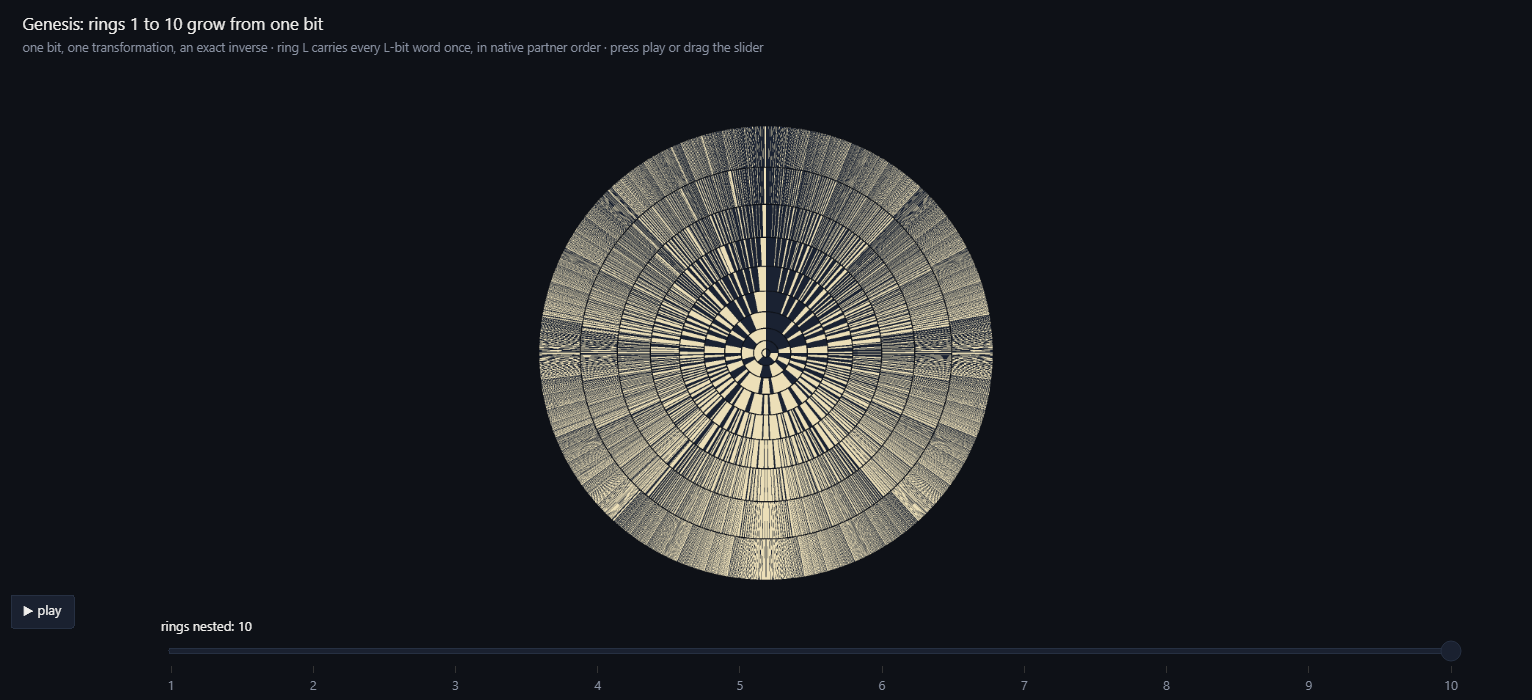

In [7]:
ui.show_checks("G-01")
rv.show(rv.fig_genesis(10))

## 2 · The native partner

With $W_n=\mathbb F_2^n$, $N=2^n$, $M=2^{n-1}$ and $u=N-1$: the $2^n$ words fall into $2^{n-1}$ partner pairs, and $2^{\lceil n/2\rceil}$ of the words are palindromes, partnered by complement. No word holds its place without a partner to move to; that is the constraint chain's second law in its smallest form.

In [8]:
rows = []
for n in range(1, 17):
    P = rc.partner_table(n); w = np.arange(1 << n)
    rows.append((n, "{:,}".format(1 << n), "{:,}".format(1 << (n - 1)), int(rc.pal_table(n).sum()), 2 ** ((n + 1) // 2),
                 int((P == w).sum()), bool((P[P] == w).all())))
display(HTML(rv.card("The partner at every width, n = 1-16",
                     rv.table(["n", "words", "pairs", "palindromes", "2^⌈n/2⌉", "fixed points", "P∘P = I"], rows, mono_cols=(0, 1, 2, 3, 4, 5)),
                     kicker="exact census", accent=rv.BLUE)))
ui.show_checks("R-01")

n,words,pairs,palindromes,2^⌈n/2⌉,fixed points,P∘P = I
1,2,1,2,2,0,True
2,4,2,2,2,0,True
3,8,4,4,4,0,True
4,16,8,4,4,0,True
5,32,16,8,8,0,True
6,64,32,8,8,0,True
7,128,64,16,16,0,True
8,256,128,16,16,0,True
9,512,256,32,32,0,True
10,"1,024",512,32,32,0,True


id,status,statement,scope,expected,actual,source,time
R-01,▶ RUNS,P is an involution without fixed points; palindromes number 2^ceil(n/2); pairs 2^(n-1),"every word, n = 1-16","P(P(x)) = x, P(x) != x",holds,(1.1)-(1.2),0.00s


### ◆ Word inspector

Type any word: binary (`1011`), hexadecimal (`0x2f`), decimal (`47`), or the prefixes `0b` / `0d`. The width follows the input unless you set it. The inspector gives the reversal, complement, partner, the exact address on the ring of that width (no enumeration, any width), face and distance from the seam, latitude, continuation depth, the mirror lift, and the word read as a carry of the machine. The default is the first 64 bits of π after the binary point.

In [9]:
ui.word_inspector("0x243F6A8885A308D3")

## 3 · The ring

Representatives $x<P(x)$ ascend in slots $0,\dots,M-1$; each partner faces its word; the two words at the seam exchange places:

$$R_n[N-1-i]=P\bigl(R_n[i]\bigr),\qquad R_n[M-1]=u\oplus e_R,\quad R_n[M]=u\oplus e_L\quad(n=2r,\ e_R=2^{r-1},\ e_L=2^r),$$

$$K_n=\operatorname{span}_{\mathbb F_2}\{e_R,e_L,u\},\qquad |K_n|=8 .$$

The first ring sits at the start, the end and the seam of every ring. The seam word is $1^{\lfloor n/2\rfloor-1}\,0\,1^{\lceil n/2\rceil}$ and nests outward as $1\cdot S\cdot 1$. Read as a tape, the ring is a palindrome everywhere except on palindromic words, where it is anti-palindromic; every ring is exactly half light, and the partner half carries $2^{\lceil L/2\rceil}$ more ones than the representative half for $L\ge2$. At $L=1$ the halves differ by one: that line lands **ELSEWHERE → the 1-bit ring**, whose only palindrome is its own middle bit.

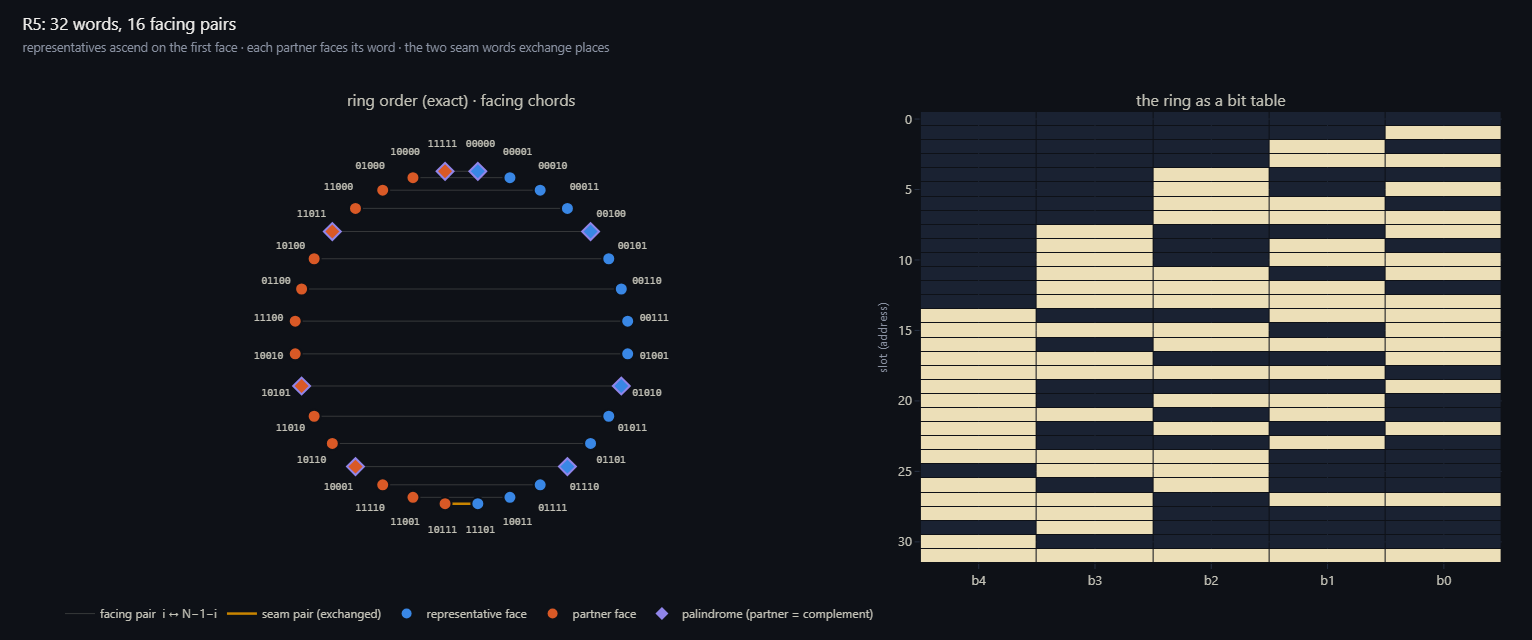

id,status,statement,scope,expected,actual,source,time
R-02,▶ RUNS,"Facing law R[N-1-i] = P(R[i]); seam R[M-1] = u xor eR, R[M] = u xor eL at even n","every slot, n = 2-16",facing law and seam,holds,(1.3)-(1.4); Retained Continuation,0.00s
R-03,▶ RUNS,The seam word is 1^(floor(n/2)-1) 0 1^(ceil(n/2)) and nests: S(n+2) = 1 S(n) 1,n = 2-16,R_n[M] = seam word; 1·S·1,holds,Mapping the Nested Partner Ring §5; Two Laps §135,0.00s
R-05,▶ RUNS,Tape twist: T[L N - 1 - p] = T[p] xor pal(word holding p),"every slice, n = 1-13",palindrome on the tape except on palindromic words,holds,"Where Yes and No Become Maybe, Route 2",0.00s
R-06,▶ RUNS,Every ring is half light (L 2^(L-1) ones); the partner half carries 2^ceil(L/2) more ones than the representative half for L >= 2,n = 1-14 (n = 1 differs by 1: owner the 1-bit ring),L·2^(L-1); 2^ceil(L/2),holds; L=1 imbalance 1,"Where Yes and No Become Maybe, Route 8",0.00s
R-07,▶ RUNS,Merge accounting: sum over words of wt(x xor P(x)) = floor(L/2) 2^L + L 2^ceil(L/2),n = 1-14,closed form,holds,"Where Yes and No Become Maybe, Route 8",0.00s


In [10]:
rv.show(rv.fig_ring_order(5))
ui.show_checks("R-02", "R-03", "R-05", "R-06", "R-07")

### ◆ Ring explorer

Slide the width to see the exact order of any ring from 2 to 9 bits: facing chords, the seam pair, the palindromes (diamonds) and the ring as a bit table.

In [11]:
ui.ring_explorer()

### The nested rings

Rings 1 to 9 in the published geometry. Left: light and gap. Right: every word merged with its facing partner, slice by slice, grey wherever the pair disagrees. The grey pattern of a pair is its residual $x\oplus P(x)$, and the mask is always a palindrome; summed over all words the grey count is $\lfloor L/2\rfloor\,2^L+L\,2^{\lceil L/2\rceil}$.

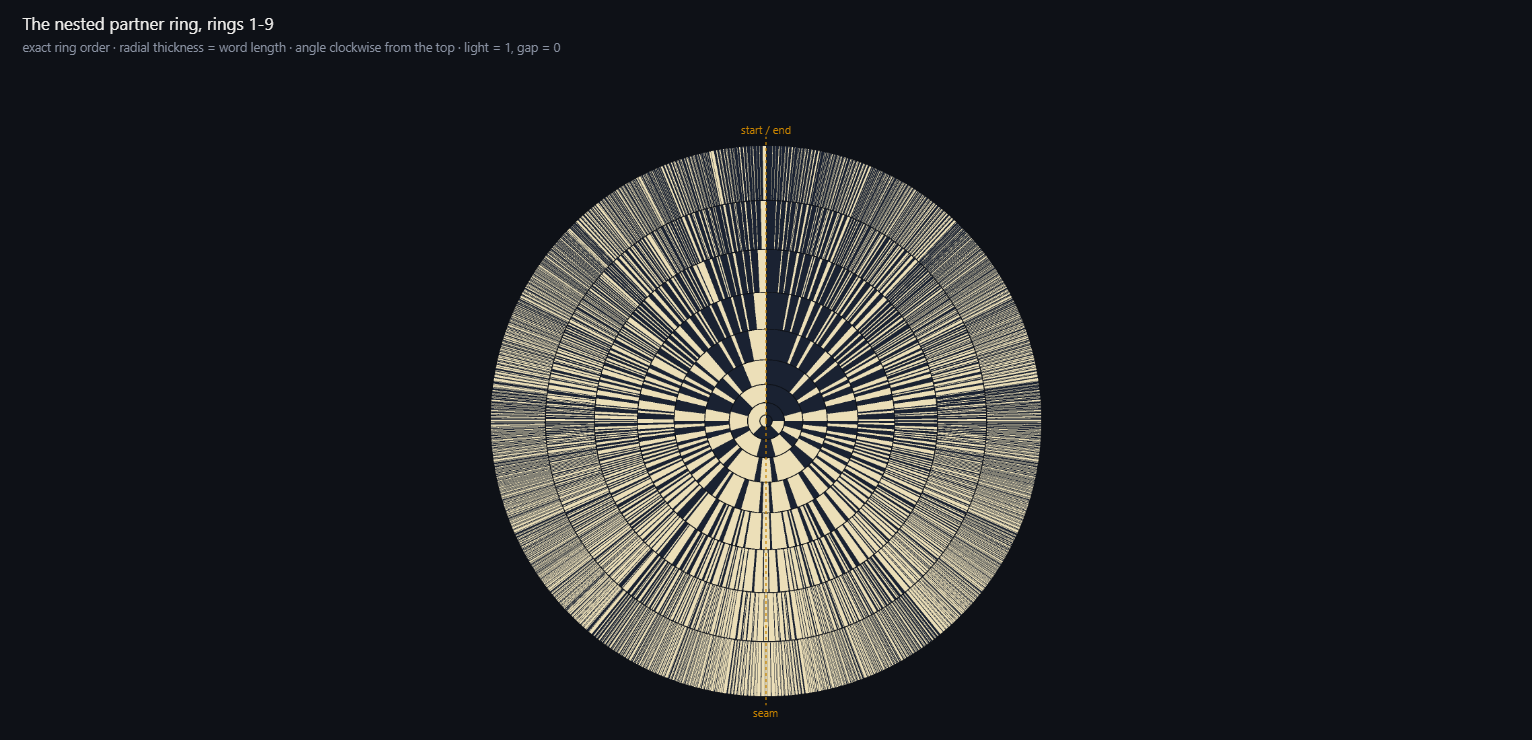

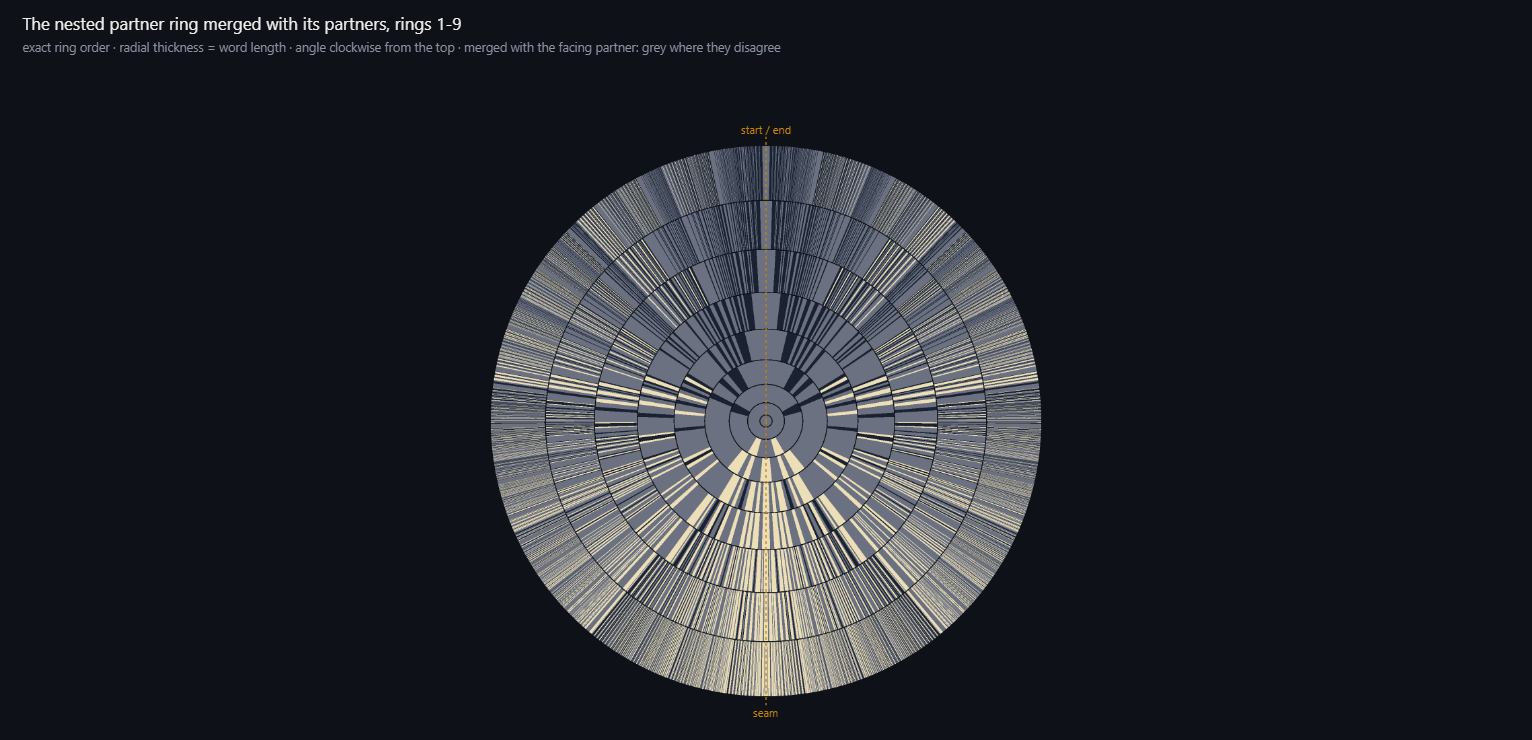

In [12]:
rv.show(rv.fig_disk(9, "bits", px=820, height=740))
rv.show(rv.fig_disk(9, "merge", px=820, height=740, title="The nested partner ring merged with its partners, rings 1-9"))

## 4 · The address machine

The ring asks one thing of a word: how it compares with its reverse.

$$c(x)=\operatorname{sgn}\bigl(J(x)-x\bigr),\qquad \Delta(p)=\sum_{x<p}c(x)=\bigl|\{x:\ x<p\le J(x)\}\bigr|,$$

$$\operatorname{rank}(p)=\tfrac12\bigl(p-\pi(p)+\Delta(p)\bigr)+\pi_c(p),\qquad \pi_c(p)=\min\bigl(\pi(p),2^{\lceil n/2\rceil-1}\bigr),$$

with $\pi(p)$ the palindromes below $p$. The engine counts $\Delta(p)$ and $\pi(p)$ with a digit program over mirror pairs read from the outside in, the native reading order of reflection, so the address is exact at any width without enumeration. The comparison is a borrow chain whose cell is the full adder's carry with one input complemented, $\beta'=\operatorname{Maj}(\neg a,b,\beta)$. On ring addresses it collapses to one address bit:

$$c_R(i)=\chi_{\mathrm{top}}(i)\bigl(1-\operatorname{pal}(i)-2[i\in\{M-1,M\}]\bigr),$$

which carries $(N-2^{\lceil n/2\rceil}-4)^2/\bigl(N(N-2^{\lceil n/2\rceil})\bigr)$ of its energy: 99.9% at $n=20$.

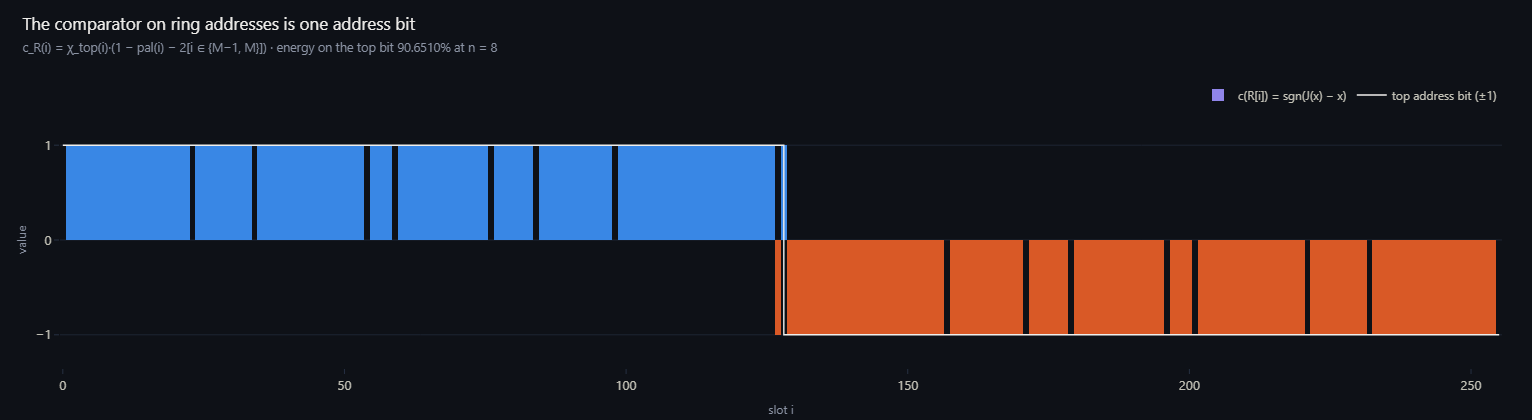

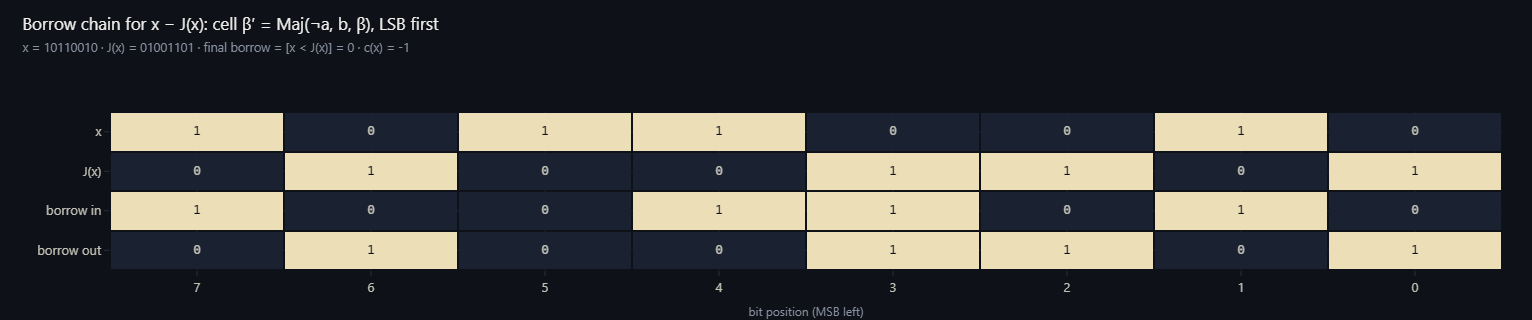

id,status,statement,scope,expected,actual,source,time
A-01,▶ RUNS,Exact address without enumeration equals the ring table; unrank inverts it,"rank: every word n = 1-9, 200 words at n = 10-12; 30 unranks per width; round trips at 64, 128, 256 bits",rank = table; unrank∘rank = id,holds,(1.6)-(1.7); Only Addressable,0.45s
A-02,▶ RUNS,"The first 64 bits of pi after the binary point sit at address 2,427,008,858,123,944,441 of the 64-bit ring",one 64-bit word,"2,427,008,858,123,944,441","2,427,008,858,123,944,441 (word 0x243F6A8885A308D3)",Against Its Own Reverse (sealed); (1.7),0.00s
A-03,▶ RUNS,On ring addresses the comparator is one address bit with palindromic zeros and a seam flip; its energy on the top bit is (N - 2^ceil(n/2) - 4)^2 / (N (N - 2^ceil(n/2))),law: every slot n = 2-12; energy at n = 20,0.9990,0.999016,(1.9),0.30s
A-04,▶ RUNS,"Borrow chain: the final borrow of x - J(x) with cell Maj(not a, b, beta) is [x < J(x)]","every word, n = 1-11",[x < J(x)],holds,(1.8),0.01s


In [13]:
import time
x = rc.pi_fraction_bits(64)
t0 = time.time(); a = rc.address(x, 64); t1 = time.time(); back = rc.word_at(a, 64); t2 = time.time()
display(HTML(rv.card("The first 64 bits of π after the binary point, on the 64-bit ring",
    rv.kv([("word", rv.bitspan(rc.bits(x, 64))), ("hex", "0x%016X" % x),
           ("address (published, sealed)", "2,427,008,858,123,944,441"), ("address (computed here)", "{:,}".format(a)),
           ("rank time", "%.1f ms" % (1000 * (t1 - t0))), ("unrank returns the word", "%s · %.1f ms" % (back == x, 1000 * (t2 - t1)))], cols=2),
    kicker="exact location without enumeration", status="RUNS" if a == 2427008858123944441 and back == x else "FAIL")))
rv.show(rv.fig_comparator(8))
rv.show(rv.fig_borrow(0b10110010, 8))
ui.show_checks("A-01", "A-02", "A-03", "A-04")

## 5 · Sphere, latitude and the Pi-Ray

Latitude reads the agreeing mirror pairs; the partner is a reflection off the palindromes and a half-turn on them:

$$z(x)=\operatorname{wt}(x)-\tfrac n2,\qquad P:(\varphi,z)\mapsto\begin{cases}(-\varphi,z), & \text{non-palindrome},\\(-\varphi,-z), & \text{palindrome},\end{cases}\qquad \cos\theta(x)=1-\frac{2\operatorname{wt}(x)}{n}.$$

The Pi-Ray is the complement drawn as a triangle: the half-turn from $0$ to $u$ split into a word and its complement. In the Hamming reading it is straight, $\operatorname{wt}(x)+\operatorname{wt}(u\oplus x)=n$; in the Euclidean reading it is a right angle at the word (Thales), $\lVert x\rVert^2+\lVert u-x\rVert^2=n$. At $n=4$ the weights sit at $0^\circ,60^\circ,90^\circ,120^\circ,180^\circ$ and the one-bit Pi-Ray has sides $1,\sqrt3,2$.

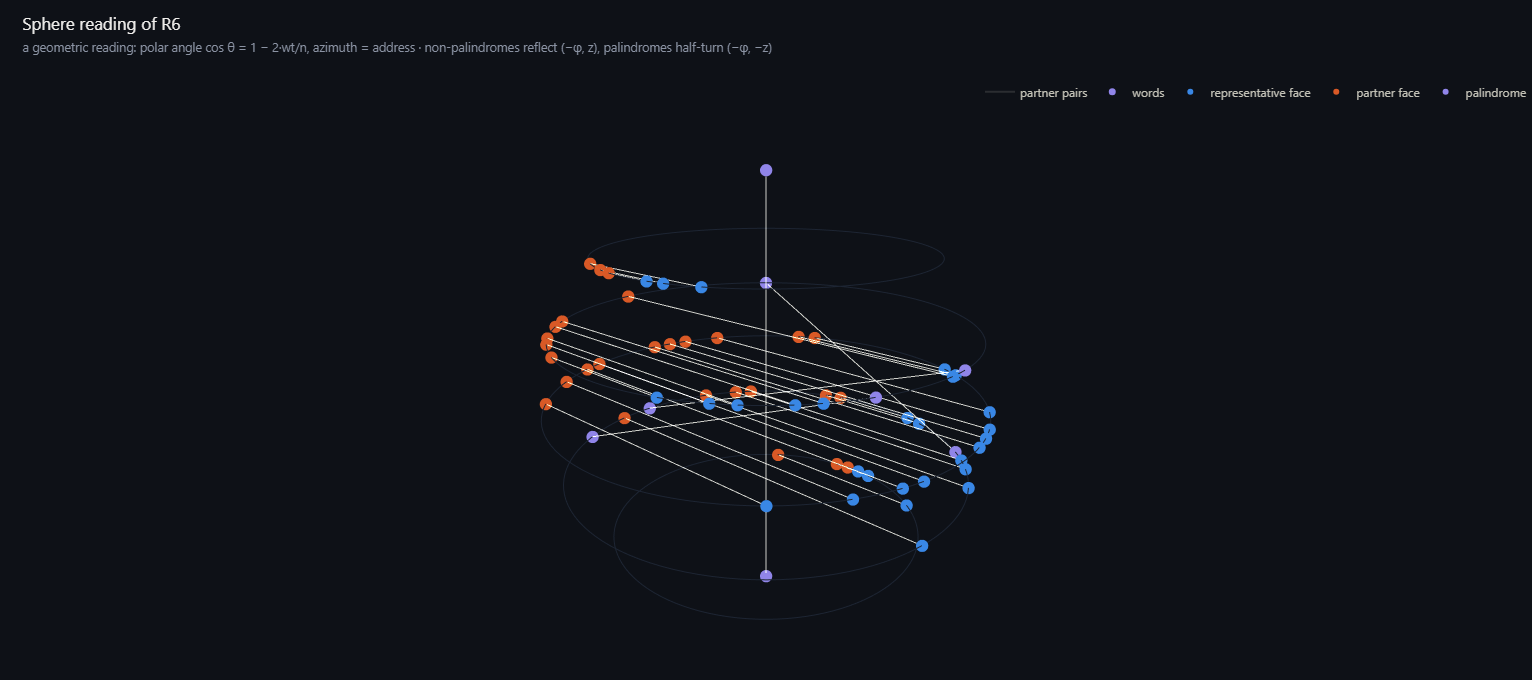

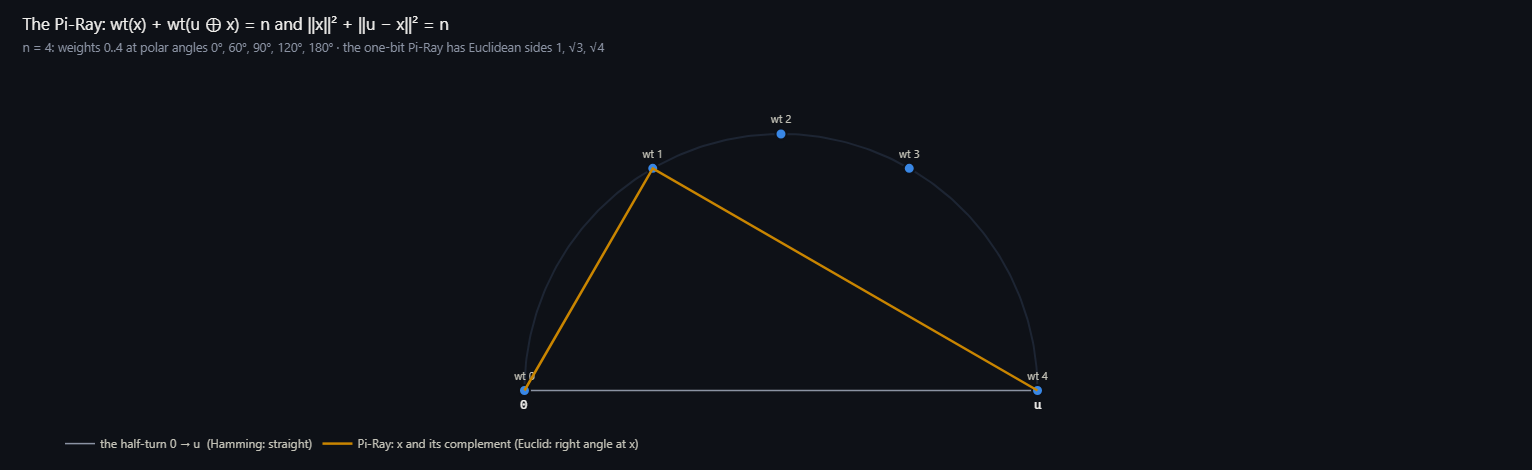

id,status,statement,scope,expected,actual,source,time
S-01,▶ RUNS,"Pi-Ray: wt(x) + wt(u xor x) = n, and |x|^2 + |u - x|^2 = n (right angle at x)","every word, n = 1-14",n,holds,(7.1),0.00s
S-02,▶ RUNS,"Partner acts on the sphere as a reflection (-phi, z) off the palindromes and a half-turn (-phi, -z) on them","every slot, n = 2-12","(−φ, ±z)",holds,(1.10),0.01s


In [14]:
rv.show(rv.fig_sphere(6))
rv.show(rv.fig_thales(4))
ui.show_checks("S-01", "S-02")

## 6 · The folded square

Cut a word of even width $2h$ into its front half $f$ and back half $g$ and place it at $(f/2^h,\ J(g)/2^h)$. Representatives fill the triangle above the diagonal, partners its mirror, palindromes the diagonal, itself folded at its midpoint. The frame of a word is its quadrant: $01$ decides *yes*, $10$ decides *no*, and $00$ and $11$ hold the whole square again at half scale, *maybe*.

The representative density at value $t$ is the straight line $1-t$; location is its integral, and what the parabola leaves is a tent, half the palindromes:

$$\rho(t)=1-t,\qquad u(t)=t-\tfrac{t^2}{2}+\text{tent},\qquad \tfrac12-u=\tfrac12(1-t)^2 .$$

Constraint 3 read in the mold: equal change per step of value makes location quadratic, and the apex, where the density reaches zero, is the seam where the last pair exchanges places (the identification with the chain's third law is a PULL in the source; the mathematics RUNS).

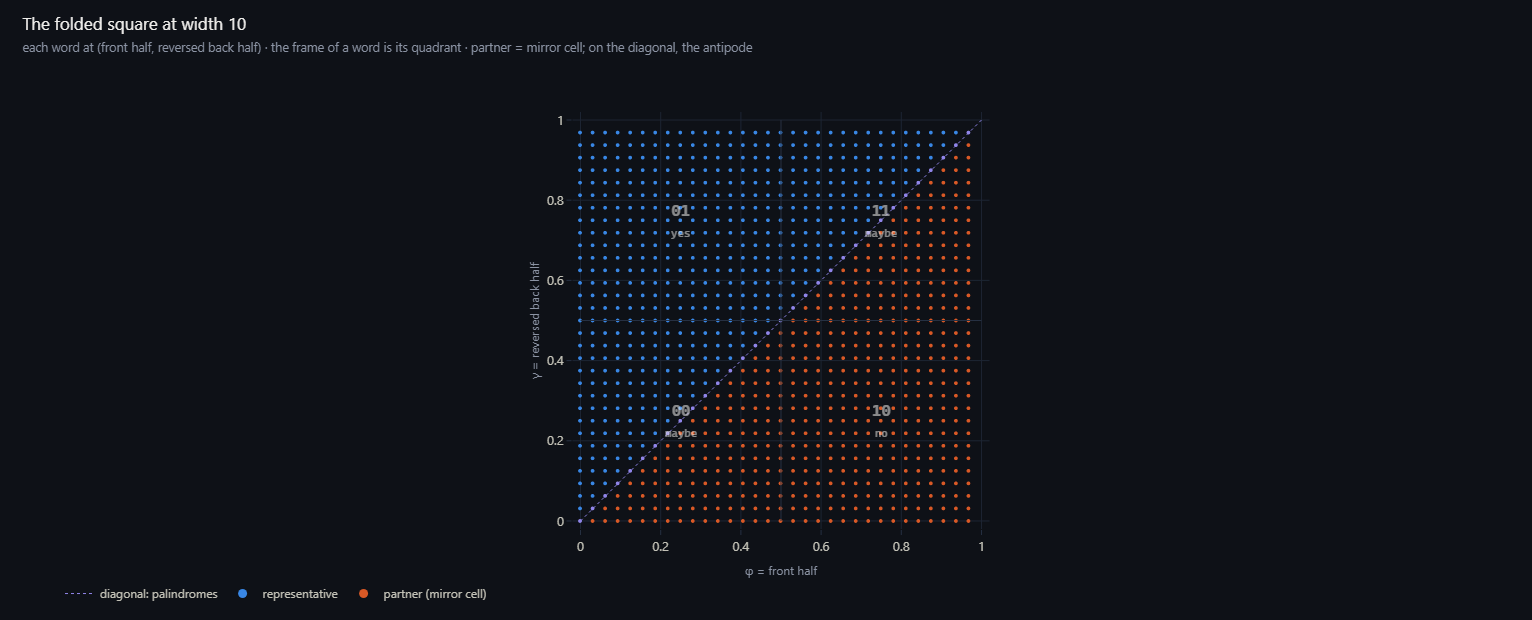

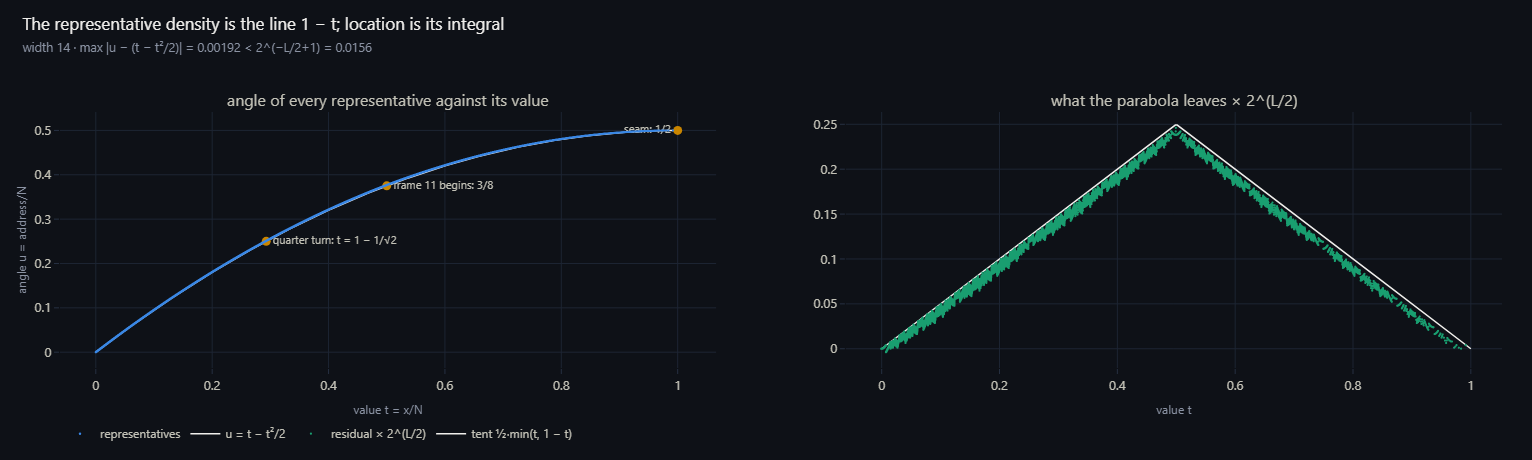

id,status,statement,scope,expected,actual,source,time
F-01,▶ RUNS,"Representatives lie on u = t - t^2/2 within 2^(-L/2+1); what the parabola leaves is the tent: the column count is Q(f) = f 2^h - f^2/2 + min(f, 2^h - f)/2",parabola n = 10-20; tent identity h = 2-8,max |res|·2^(L/2-1) < 1,max 0.176,(1.11); Routes 5 and 7,0.14s
F-02,▶ RUNS,"Centre of mass: representatives 1/3, partners 2/3 (width 20: 0.333091, 0.666908)",width 20,0.333091 / 0.666908,0.333091 / 0.666908,"Where Yes and No Become Maybe, Route 5",0.01s


In [15]:
rv.show(rv.fig_folded_square(10))
rv.show(rv.fig_parabola(14))
ui.show_checks("F-01", "F-02")

## 7 · Recursive growth: four providers and continuation

Every ring is the 2-bit ring used as a frame alphabet around the ring two widths below. A word $x=b\,m\,c$ is a representative exactly when $(b,c)=(0,1)$, or $(0,0)$ with $m\le J(m)$, or $(1,1)$ with $m<J(m)$; the frame $10$ admits nothing. As providers,

$$\mathrm{reps}_L=0\cdot W_{L-2}\cdot1\ \sqcup\ 0\cdot\mathrm{reps}_{L-2}\cdot0\ \sqcup\ F(\mathrm{reps}_{L-2}),\qquad F(a)=\min\bigl(1a1,\ P(1a1)\bigr).$$

One provider in four is continuation, so

$$\Pr(\text{depth}\ge t)=4^{-t},\qquad \text{roots}=3\cdot2^{L-3},\qquad \mathbb E[\text{depth}]=\frac{1-4^{-\lfloor (L-1)/2\rfloor}}{3}\to\frac13 .$$

On the complement branch a palindrome stays on the diagonal and moves by $\varphi\mapsto(1-\varphi)/2$, whose fixed point is $1/3$: the ray of the root $00$ runs $00,\ 0110,\ 010010,\ 01011010,\dots$ to value $1/3$ at angle $5/18$. The $01$ ray is the seam word at every even width. Both branches have closed forms, so the codec never iterates.

id,status,statement,scope,expected,actual,source,time
R-04,▶ RUNS,"Four providers: x = b m c is a representative iff (b,c) = (0,1), or (0,0) with m <= J(m), or (1,1) with m < J(m); the frame 10 admits nothing","every word, n = 3-14",frame law,holds,"Where Yes and No Become Maybe, Route 3",0.00s


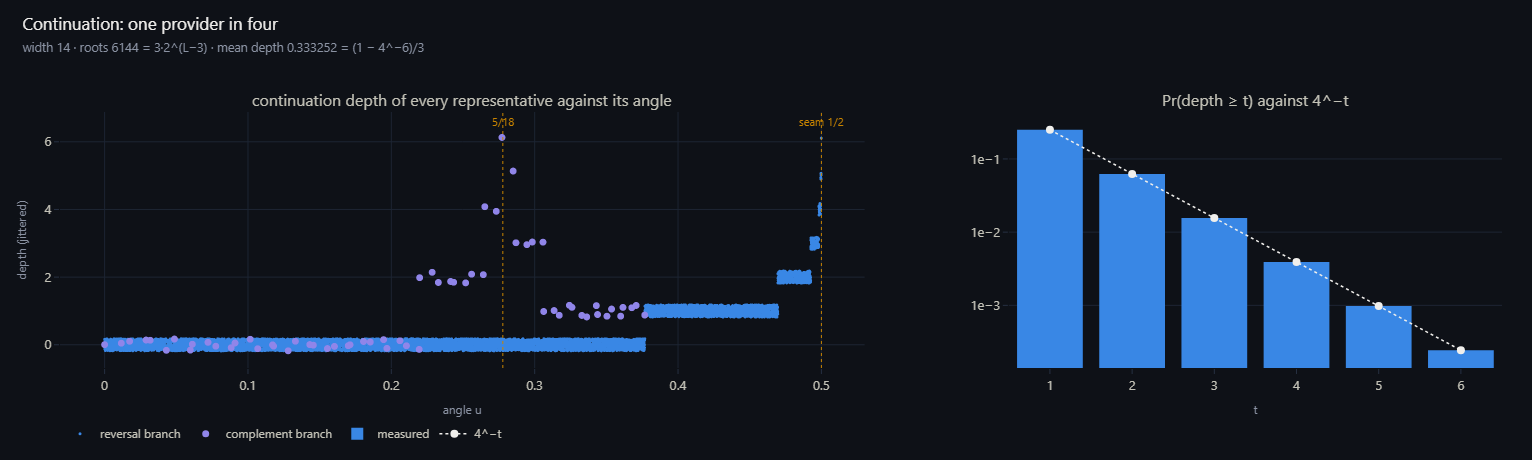

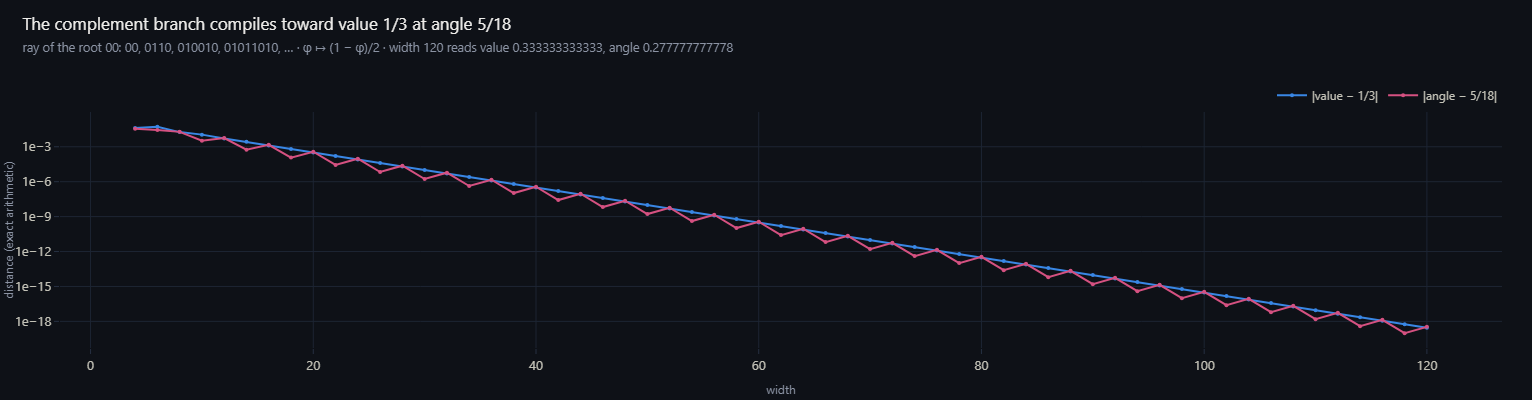

id,status,statement,scope,expected,actual,source,time
C-01,▶ RUNS,"Continuation depth: Pr(depth >= t) = 4^-t, roots 3·2^(L-3), mean (1 - 4^-floor((L-1)/2))/3; width 16 mean 5461/16384","every representative, n = 3-16",5461/16384,5461/16384,(1.12); Route 6,0.05s
C-02,▶ RUNS,"Closed-form codec: every representative is F^k(root); the record (root, k) round-trips","every representative, n = 1-12",round trip,holds,Route 6,0.01s
C-03,▶ RUNS,The complement ray of 00 compiles to value 1/3 at angle 5/18; the 01 ray is the seam word,width 120 (exact),"value 0.333333333333, angle 0.277777777778; 01 ray in slot M","value 0.333333333333, angle 0.277777777778; 01 ray slot M: True","Route 6, Route 9",0.00s


In [16]:
ui.show_checks("R-04")
rv.show(rv.fig_depth(14))
rv.show(rv.fig_rays(120))
ui.show_checks("C-01", "C-02", "C-03")

## 8 · The Ring Reader ◆

Choose how many rings to nest, pick a reader, and set its **width**, **direction** and **location**. The reader draws its path on the rings and dumps what it read: a table, a plain-text dump you can copy, and (for windows) a bit ribbon.

| Reader | width | direction | location | what it reads |
|---|---|---|---|---|
| **Radial** (published) | aperture: slices per ring (1 = the published reader) | outward (ring 1 → D) or inward | an angle $u\in[0,1)$: `5/18`, `0.3`, `100deg`, `1/2+1/1024` | on ring $L$, slice $\lfloor L\{2^Lu\}\rfloor$ of $R_L[\lfloor 2^Lu\rfloor]$ |
| **Tape** | window width in bits | clockwise or counterclockwise | `ring:slot:offset` | consecutive windows of the ring's bit stream; each window's own address |
| **Native** | ring width $n$ | the carry $w$ (the direction it moves) | the start word $p$ | the reader–field step from an empty field |
| **Clock** | ring width $n$ | forward $\tau$ or backward $\tau^{-1}$ | the start word | the one-inverter loop and its center reader |

The native reader is the domain's own reader: its state *is* width, direction and location, $(n, w, p)$, and each tick it reads $x=D[p]\oplus w$, moves to $p\oplus x$, carries $P(x)$, and writes that carry into the cell it leaves.

In [17]:
ui.ring_reader()

### 8.1 One angle for every depth

The profile $q_D=1\,00\,1^{D-5}\,00$ is read by a single angle at every depth $D\ge13$ (*Mapping the Nested Partner Ring*, Theorem 2):

$$u_D=\tfrac12+2^{-p}+\tau\,2^{-(D-1)},\qquad t=\Bigl\lfloor\tfrac{D-2}{3}\Bigr\rfloor,\quad p=2t+3,\quad \tau\in\Bigl[\tfrac23+\tfrac1{6D},\ \tfrac23+\tfrac1{3D}\Bigr).$$

Below ring $p$ the reader sits on the seam word; from ring $p$ on it sits on the two-zero words, and the last two slices land on the zeros $L-1-t$ and $t+1$. The control $\tau=2/3$ fails exactly at $D\equiv2\pmod 3$. Just right of the seam every ray reads $1,0,0,1,1,1,\dots$ and just left $0,0,0,1,1,1,\dots$: the two sides differ only at ring 1.

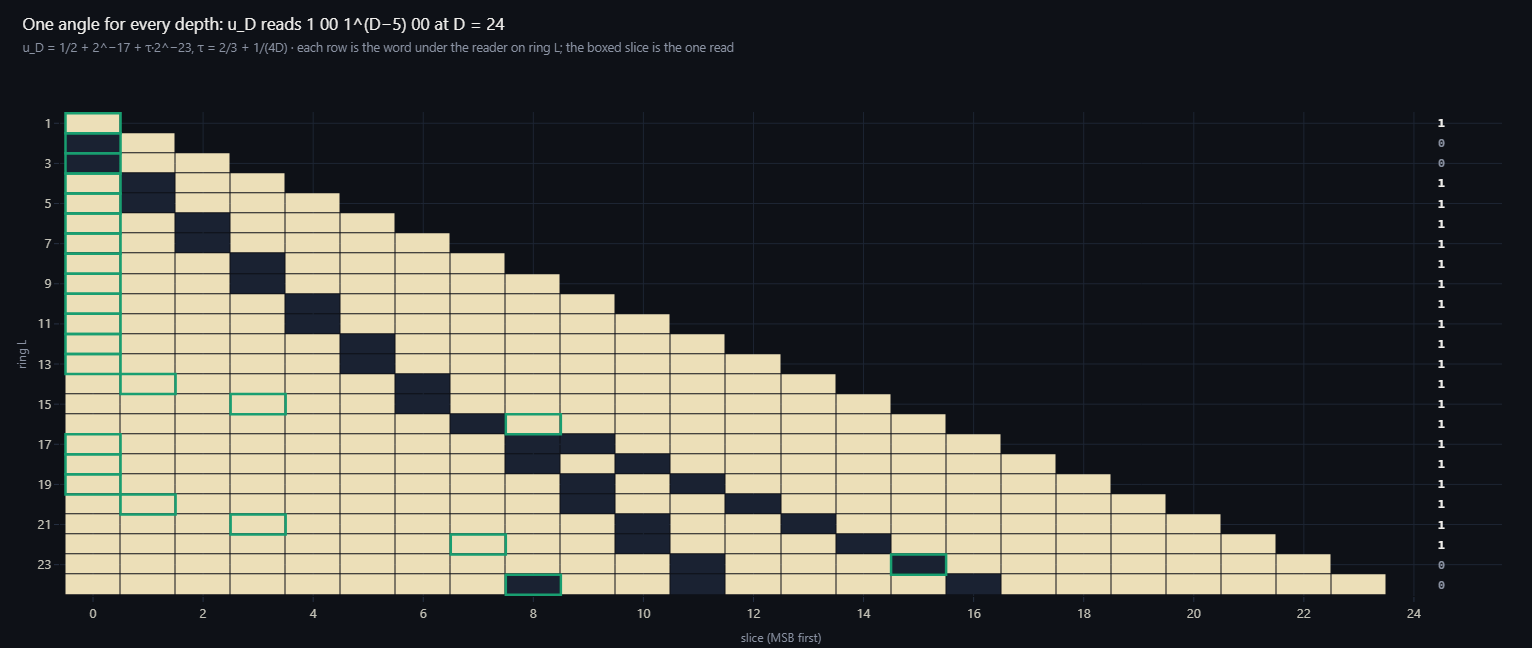

id,status,statement,scope,expected,actual,source,time
D-03,▶ RUNS,One angle for every depth: u_D reads 1 00 1^(D-5) 00; the control tau = 2/3 fails exactly at D = 2 (mod 3),"D = 13-40, exact arithmetic (the source runs to 400)",no failures,failures [],"Mapping the Nested Partner Ring, Theorem 2",1.89s
D-04,▶ RUNS,"Two-sided seam: just right reads 1,0,0,1,1,1,...; just left reads 0,0,0,1,1,1,...",rings 1-24,100111111111111111111111 / 000111111111111111111111,100111111111111111111111 / 000111111111111111111111,"Where Yes and No Become Maybe, Route 9",0.03s


In [18]:
rv.show(rv.fig_witness(24))
ui.show_checks("D-03", "D-04")

### 8.2 The tape at every offset

Read the tape in windows of $L$ bits that start $s$ bits into each word, $w_i(s)=(R_L[i]\bmod 2^{L-s})\,2^s+\lfloor R_L[i+1]/2^{L-s}\rfloor$. Frames 0 and 1 are complete at every width; with $h=\lfloor L/2\rfloor$ and $P=2^{\lceil L/2\rceil}$ the loss is $P(1-2^{2-s})$ for $2\le s\le h-1$, $P-2$ (even $L$) or $P-6$ (odd $L$) at $s=h$, $P-2-2^{s-h+1}$ above the middle, and $P-2$ at $s=L-1$. Every word a frame misses is owned by a palindrome: below the middle offset a palindrome pinches two windows into words already said.

### 8.3 The radial language and the square root

A ray reads one bit per ring. The number of distinct profiles at depth $D$ is computed exactly on the merged slice grid. In the front half of every word a ray reads the digits of $\tau(u)=1-\sqrt{1-2u}$; the back half carries the mirror's answer.

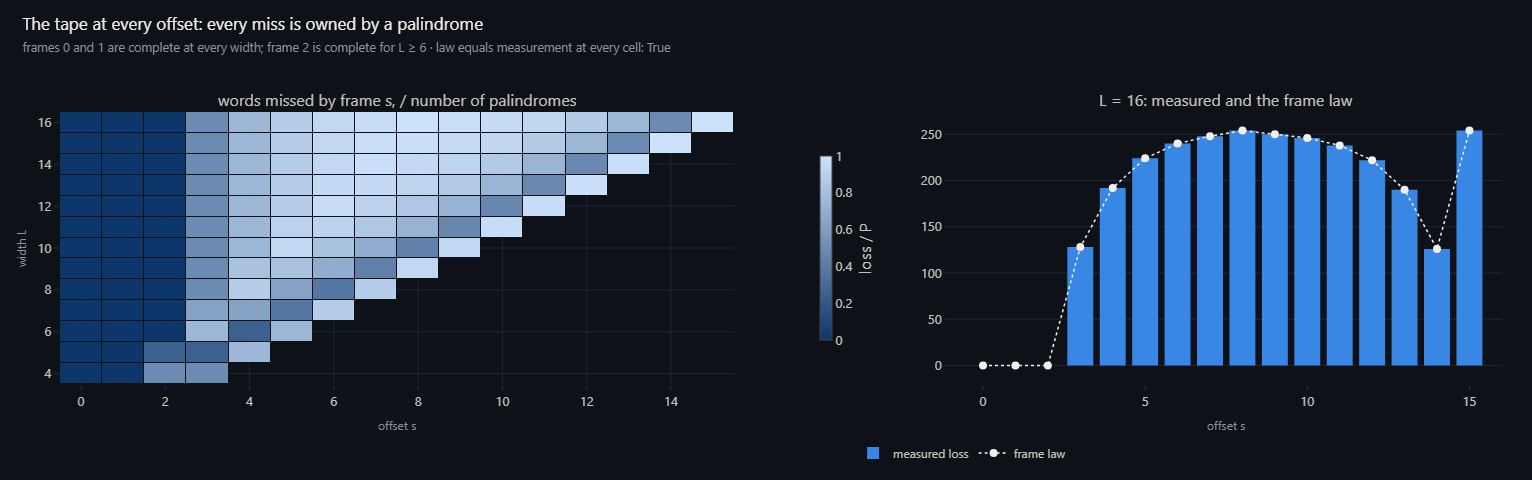

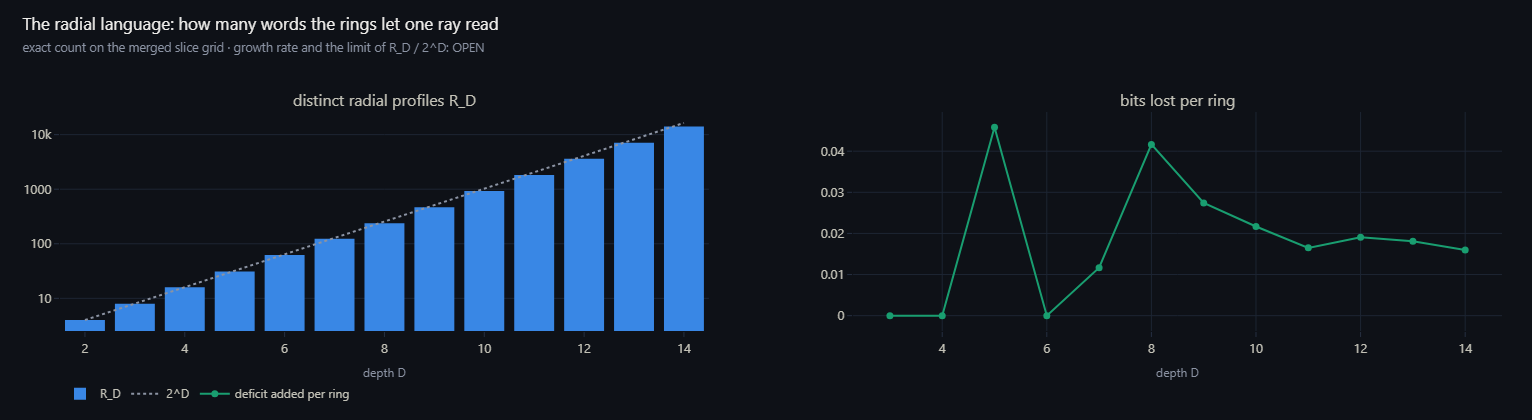

id,status,statement,scope,expected,actual,source,time
D-01,▶ RUNS,Frame law: the loss of every L-bit window frame at every offset,every cell L = 4-16,"[0, 0, 0, 128, 192, 224, 240, 248, 254, 250, 246, 238, 222, 190, 126, 254]","[0, 0, 0, 128, 192, 224, 240, 248, 254, 250, 246, 238, 222, 190, 126, 254]",Mapping the Nested Partner Ring §4,0.18s
D-02,▶ RUNS,Radial language: distinct profiles R_10..R_16 and the angular entropy at 16,"exact merged grid, D = 10-16","{'10': 924, '11': 1827, '12': 3606, '13': 7122, '14': 14087, '15': 27819, '16': 55122}; H16 = 14.951476","{'10': 924, '11': 1827, '12': 3606, '13': 7122, '14': 14087, '15': 27819, '16': 55122}; H16 = 14.951476","Where Yes and No Become Maybe, Route 10",1.61s
D-05,▶ RUNS,The front half of the word under the radial reader reads the digits of tau(u) = 1 - sqrt(1 - 2u),"240 sampled front-half readings, L = 24-64",>= 95%,"230 / 240 agree; every miss sits within 4 slices of the word centre (the tent term, order 2^(-L/2))","Where Yes and No Become Maybe, Route 7 (sealed threshold 95%)",1.60s


In [19]:
rv.show(rv.fig_frames(4, 16))
rv.show(rv.fig_radial_language(14))
ui.show_checks("D-01", "D-02", "D-05")

## 9 · Difference and reconstruction

Write the ring as its $N\times n$ bit table $X$ and its step-to-step XOR stream $D=(I\oplus T)X$, $D_k=R[k]\oplus R[k+1]$. The Boolean Möbius matrix $M_{u,v}=[v\subseteq u]$ is self-inverse and conjugates cyclic differencing into the nilpotent shift:

$$M(I\oplus T)M=S,\qquad MD=SA\quad(A=MX),\qquad X=M\,S^{\top}M\,D .$$

Because the ring starts at $0$, the top row of $A$ vanishes and the whole ring is carried, losslessly, by its own instruction stream.

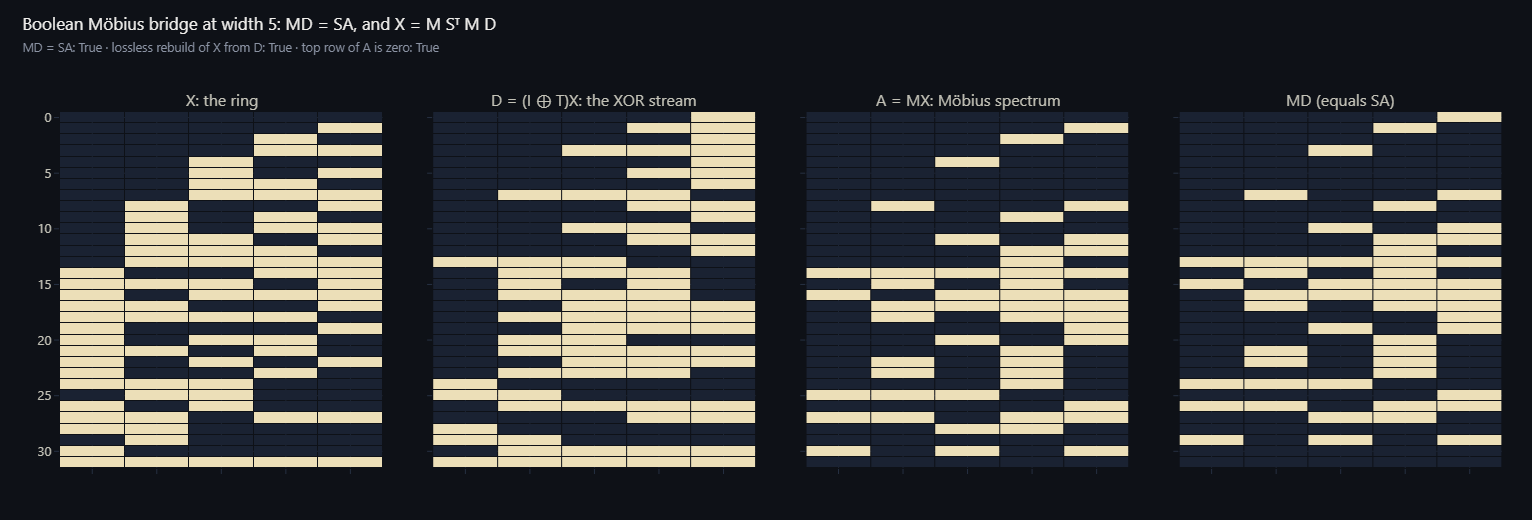

id,status,statement,scope,expected,actual,source,time
M-01,▶ RUNS,Boolean Moebius bridge MD = SA and lossless rebuild X = M S^T M D,"full state matrix, n = 1-14",MD = SA; X rebuilt,holds,"(1.13); Bicomplex Difference Calculus, Thm 3.4",0.01s


In [20]:
rv.show(rv.fig_mobius(5))
ui.show_checks("M-01")

## 10 · The one-inverter clock and the nine-cell rung

The complete ring must run. What runs it is fixed by its shape: a bijection, no fixed word, built from one bit, no preferred position.

$$\tau(x)=\operatorname{rotl}_1(x)\oplus 1,\qquad \tau^n=C,\qquad \tau^{2n}=I,\qquad |\text{orbit}|=\frac{2n}{d}\ \ (d\mid n,\ d\ \text{odd}).$$

A loop with inverter mask $w$ is a latch (two fixed words) when $\operatorname{wt}(w)$ is even and a clock (none) when it is odd. $\tau^s(x)=C(x)$ has solutions exactly when $n/s$ is odd: the locks. At even $n$ the center reader $r(x)=x_{h-1}\oplus x_{n-h}$ reads every adjacent difference once, with one known inversion, and its $n$ readings XOR to $1$.

**Spin form.** With $s_i=(-1)^{x_i}$, $\tau$ is the negacyclic shift: $s'_{i+1}=s_i$, $s'_0=-s_{n-1}$. Its eigenvalues are the $n$ roots of $\lambda^n=-1$, the angles $(2k+1)\pi/n$, so **one tick turns the fundamental mode by exactly $\pi/n$**, and $n$ ticks make the full flip.

**The nine-cell rung.** The bare sign, a six-tick lap of three cells, lives inside a larger clock exactly when $n$ is three times an odd number: $3, 9, 15,\dots$ Nine is the first, and its clock holds nothing else: 28 laps of 18 ticks, one bare sign, one flip pair, $28\cdot18+6+2=512$. Its tick angle is $\pi/9=20^\circ$; the zero point runs the full lap, reaches the complement $1^9$ at tick 9 and comes home at tick 18; and the weight parity flips on every tick, a one-cell flip clock riding inside the nine.

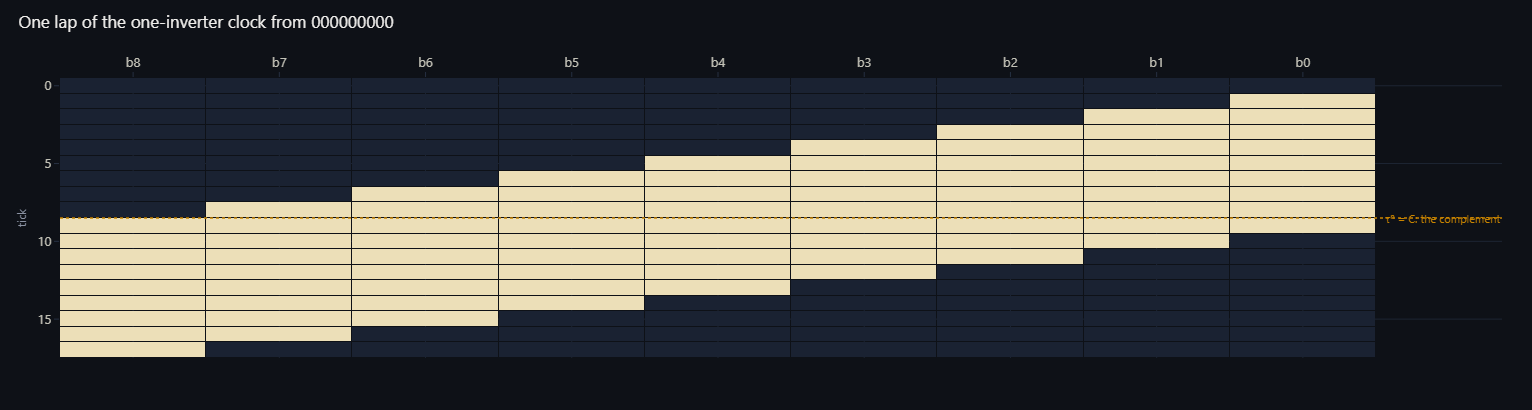

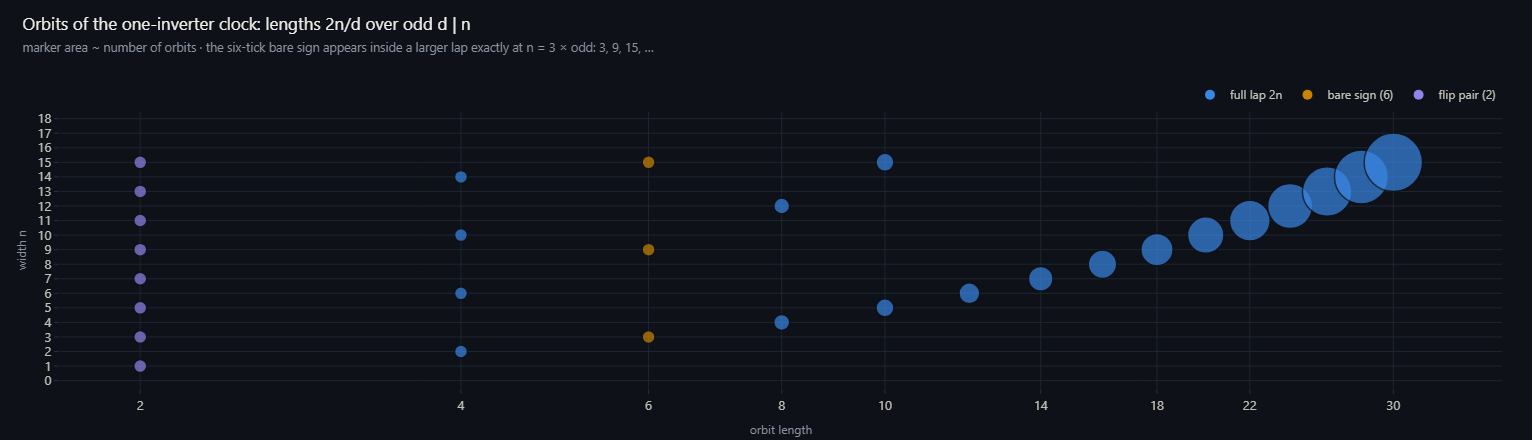

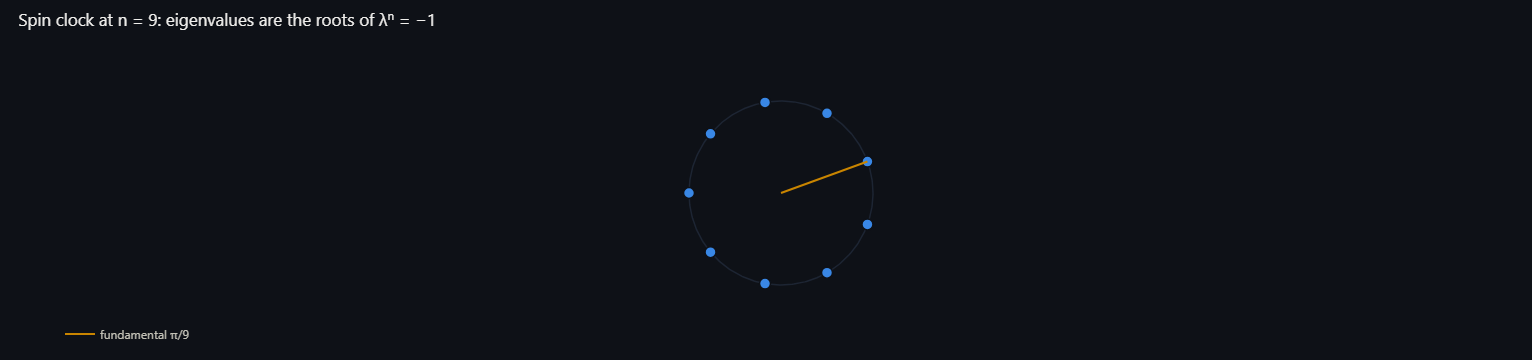

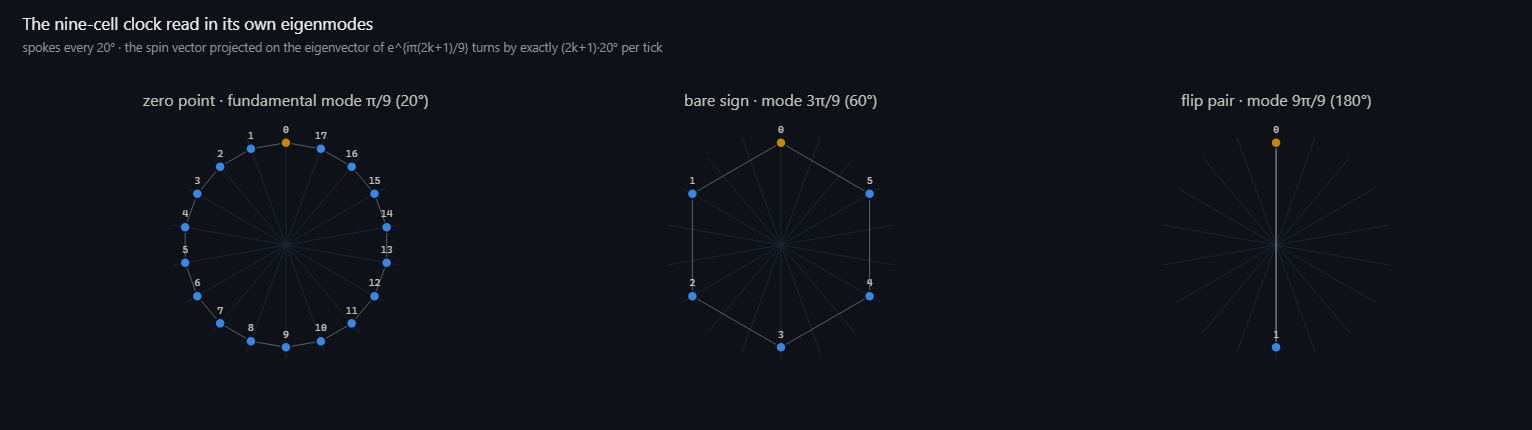

id,status,statement,scope,expected,actual,source,time
K-01,▶ RUNS,"tau^n = C, tau^2n = I, and orbit lengths are exactly {2n/d : d odd, d | n}","every word, n = 1-14",laws,hold,"(2.1), (2.3)",0.08s
K-02,▶ RUNS,Inverter parity: rotl1 xor w is conjugate to rotation (a latch) when wt(w) is even and to tau (a clock) when odd,"every mask, n = 2-8",cycle type of rotl1 or of tau,holds,(2.2),0.01s
K-03,▶ RUNS,Locks: tau^s(x) = C(x) has 2^s solutions when n/s is odd and none when it is even,"n = 1-12, every divisor s",2^s or 0,holds,(2.3),0.03s
K-04,▶ RUNS,Center reader at even n: y_t = d_(h-1-t) xor [t = h] and the n readings XOR to 1,"every word, even n = 2-14 (odd widths: the innermost pair is not adjacent)",identity; XOR = 1,holds,(2.4),0.11s
K-05,▶ RUNS,"In spin coordinates tau is the negacyclic shift; its eigenvalues are the n roots of lambda^n = -1, so one tick turns the fundamental mode by pi/n",n = 1-16; the zero point's lap at n = 9,angles (2k+1)π/n; 20° per tick at n = 9,20.000000° per tick,One Inverter; this notebook (spin form),0.00s
K-06,▶ RUNS,"The nine-cell clock: 28 laps of 18 ticks, one bare sign (6), one flip pair (2); the bare sign sits inside a larger lap exactly at n = 3 x odd",n = 9 census; n = 1-15 search,"{'18': 28, '6': 1, '2': 1}; [3, 9, 15]","{'18': 28, '6': 1, '2': 1}; [3, 9, 15]",this notebook; One Inverter (orbit law),0.01s
K-07,▶ RUNS,"The clock flips exactly one bit per tick: |delta wt| = 1 on every tick, weight parity alternates, and the net change of latitude over a lap is zero","every word, n = 1-12, one full lap",|Δwt| = 1; net 0,holds,(2.1); this notebook,0.10s
H-01,▶ RUNS,Legacy sighting: H = pi/9 is the tick angle of the nine-cell clock and its lap is 18 ticks (period-18 bridge); the 260/729 anchor is the k = 9 value of a wheel fraction that crosses pi/9 and tends to 1/2,"lap at n = 9; wheel k = 8, 9, 60",18; 260/729; crossing between k = 8 and 9; → 1/2,18; 260/729 = 0.3567; k=8 0.3418; k=60 0.4756,this notebook; ZPHC gap map A3; Funnel Paper Vol. I §6.2,0.01s


In [21]:
rv.show(rv.fig_clock_strip(0, 9))
rv.show(rv.fig_clock_census(15))
rv.show(rv.fig_eigencircle(9))
rv.show(rv.fig_nine_modes())
ui.show_checks("K-01", "K-02", "K-03", "K-04", "K-05", "K-06", "K-07", "H-01")

> **Legacy sighting, routed.** The earlier framework carried $H=\pi/9$ as a constant and listed "period-18 folding … why a 20° gate induces those integers" as a missing bridge (ZPHC gap map, item A3). The bridge is the clock: $\pi/9$ is the tick angle of the nine-cell one-inverter loop, a constant shown as an invariant of an update law, and 18 is its lap. **STANDS.** The value $0.35$ used as the setpoint of $dH/dt=-k(H-0.35)$ lands **ELSEWHERE → the adapter layer** (a controller steering a reader); the domain ticks at $\pi/9$ and steers nothing. The anchor $260/729$ lands **ELSEWHERE → the $k=9$ value of the wheel triangle fraction**, which crosses $\pi/9$ between $k=8$ and $9$ and tends to $1/2$. What places a system on the nine-cell rung, rather than three or twenty-seven, stays **OPEN**.

### ◆ Clock explorer

In [22]:
ui.clock_explorer()

## 11 · The reader–field machine

The clock runs a register with no memory. A reader that writes what it reads is the next shape, and it must keep its way home. With WHERE $p_t$, carry $w_t$, the retained field $D_t$ and $d_t=D_t[p_t]$:

$$x_t=d_t\oplus w_t,\quad p_{t+1}=p_t\oplus x_t,\quad w_{t+1}=P(x_t),\quad D_{t+1}[p_t]=d_t\oplus w_{t+1};\qquad x_t=P(w_{t+1}),\ \ p_t=p_{t+1}\oplus x_t .$$

Because $P^2=I$ both directions are exact: no bit is lost and no stack is needed. From an empty field the route never leaves $K(w_0)=\operatorname{span}\{u,w_0,J(w_0)\}$, of dimension 1, 2 or 3, and that is the three closure classes. On the carrier the partner is affine, $P=A\oplus u$ with $A(z)=z\oplus\ell_0(z)v$, so the step's only nonlinearity is the read $D[p]$: memory looked up by position. The cell a reader leaves holds the carry it arrived with, complemented, adjusted by one lamp,

$$D_{t+1}[p_t]=w_t\oplus u\oplus\sigma(x_t),\qquad w_{t+1}=w_t\oplus w_r\oplus\sigma(x_t)\oplus\sigma(x_r)\ \ \text{on a revisit},$$

so a reader's next carry is a collision with its own earlier pass. Acceleration is the two-step departure $\alpha_t=w_t\oplus w_{t+2}=d_t\oplus A(d_{t+1})$; the switch $q_t=w_t\oplus w_{t+1}\oplus w_{t+2}$ is the event log. The classes return from the empty field in **6**, **132** and **43,155,322** ticks at every width, and each holds exactly two of three properties.

id,status,statement,scope,expected,actual,source,time
X-01,▶ RUNS,The step and its inverse compose to the identity on populated fields,"5,000 random populated states, n = 4-8",identity,holds,(3.1)-(3.2),0.14s
X-02,▶ RUNS,"Class counts: R1 = 2, R2 = 2^(n/2+1) - 2 or 2^((n+1)/2) - 2, R3 = 2^n - 2^floor((n+2)/2); R1 u R2 = {w : P(w) = C(w)}","every carry, n = 2-16",formula; diagonal identity,holds,(4.1),0.19s
X-03,▶ RUNS,"From an empty field every R1 carry returns in 6 ticks and every R2 carry in 132, at every width","every R1 and R2 carry, n = 4-10",6; 132,holds,(4.2),0.01s
X-06,▶ RUNS,The bare sign walks the three-stage Johnson counter; every step is collapsed; tick 3 is the start moved by u,R1 from carry 0,"Johnson walk; collapsed; tick 3 = (u, 0, empty)","[(0, 0, 0), (0, 1, 0), (0, 1, 1), (1, 1, 1), (1, 0, 1), (1, 0, 0)]; collapsed True; tick 3 = (4, 0, 0)",(4.5)-(4.6),0.00s
X-07,▶ RUNS,"Memory is the reader's own past: overwrite (3.7) and revisit (3.8) on every tick of R1 and R2 runs; acceleration alpha = d_t xor A(d_t+1) on 200,000 ticks of R3","R1/R2 full periods at n = 4, 6, 8; 200,000 R3 ticks",0 errors,alpha errors 0,"(3.7), (3.8), (3.10)",0.07s
X-08,▶ RUNS,Event log: Q_T = I + S + S^2 is invertible iff 3 does not divide T; the tape rebuilds the carries (with one seed word when 3 | T); both light seeds emit the same blank tape,"T = 1-399; R1/R2 replay at n = 4, 6, 8; random tapes",laws,hold,(4.7)-(4.11),0.11s


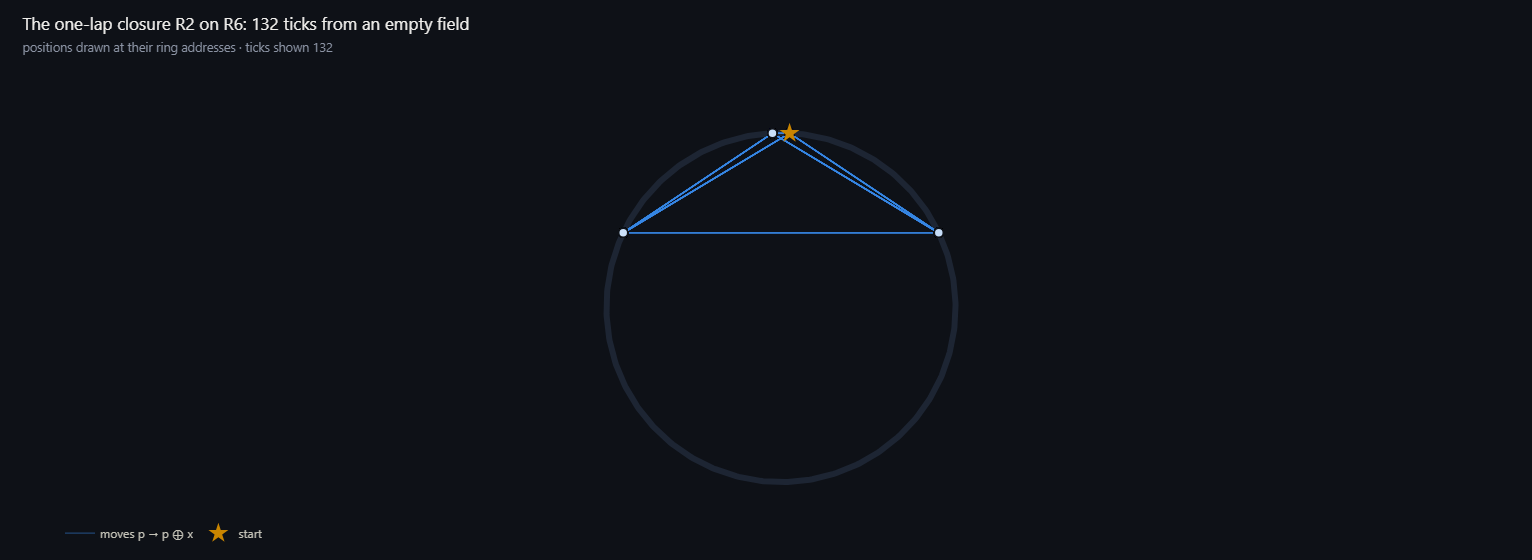

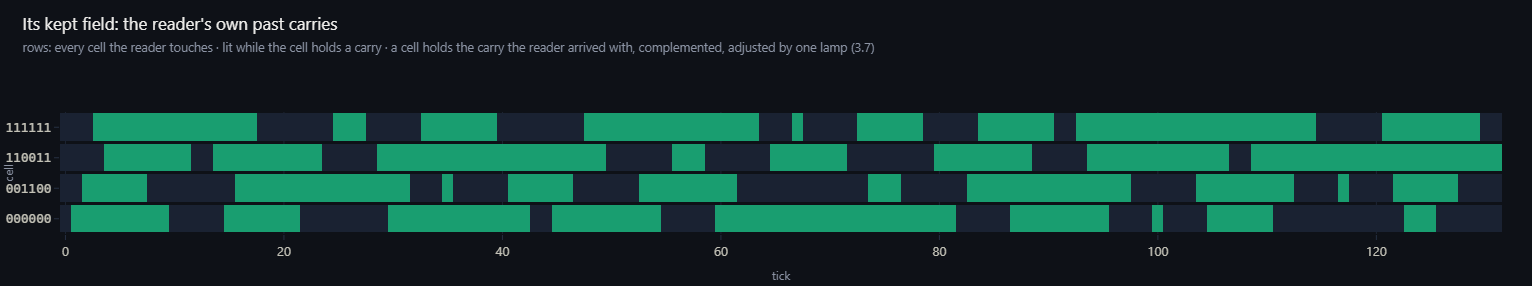

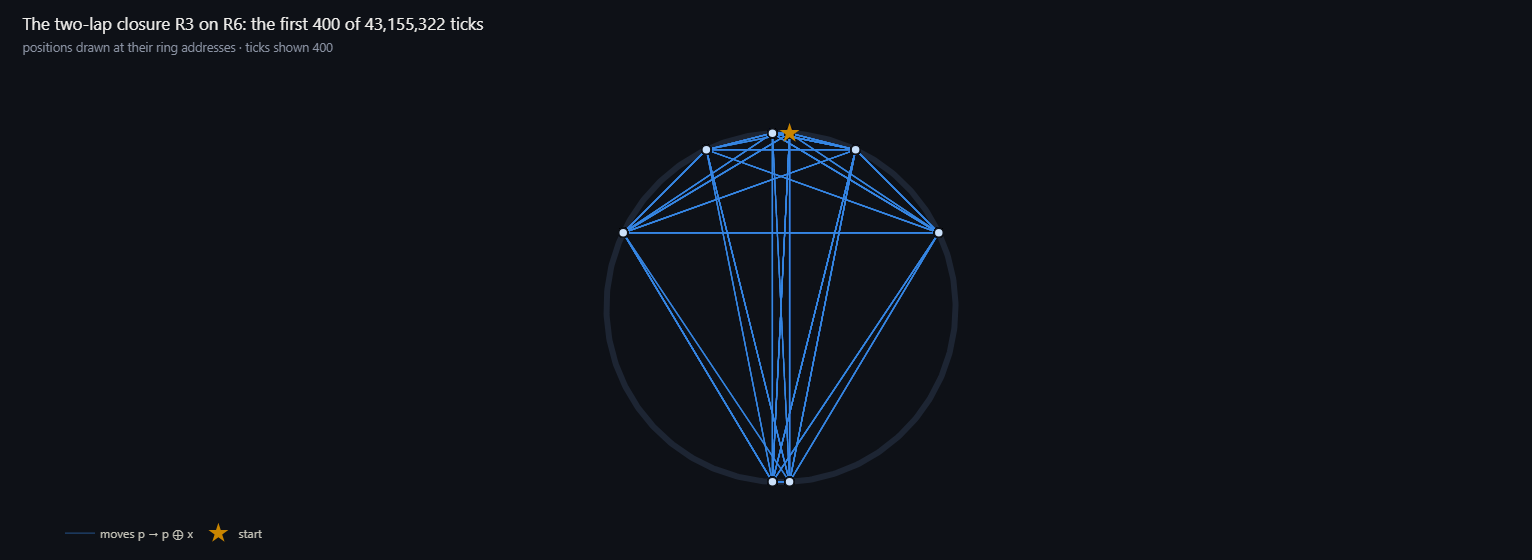

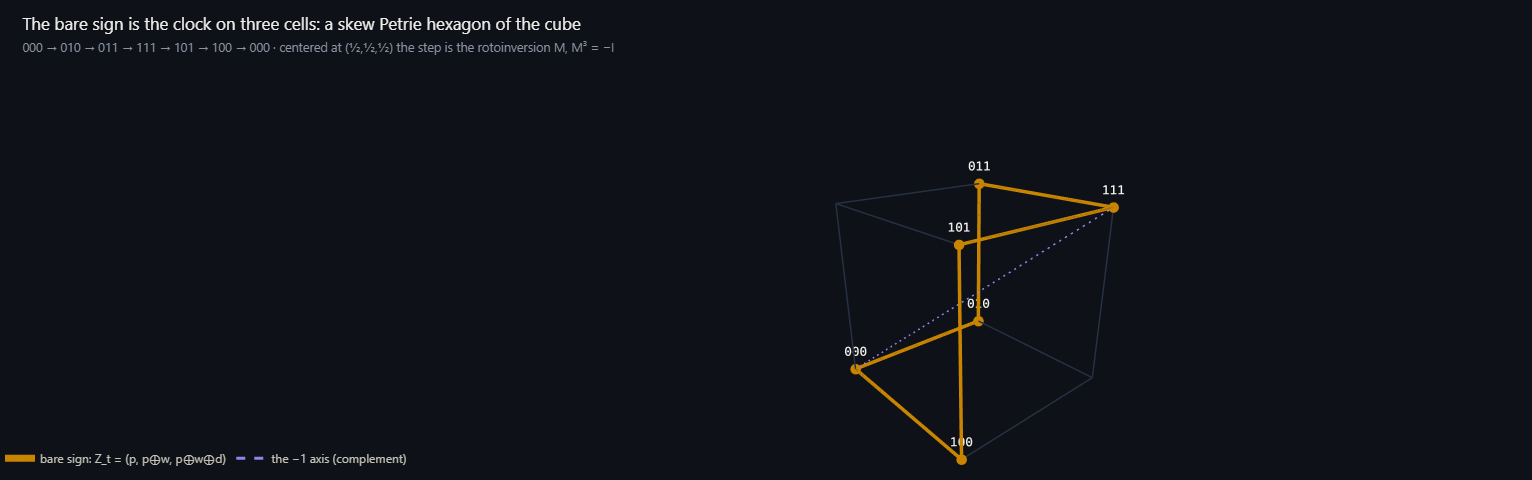

In [23]:
ui.show_checks("X-01", "X-02", "X-03", "X-06", "X-07", "X-08")
n, w0 = 6, 0b001100                                   # a palindromic carry: class R2, the one-lap closure
rows, _ = rc.run_reader(n, 0, w0, 132)
rv.show(rv.fig_route(n, rows, title="The one-lap closure R2 on R6: 132 ticks from an empty field"))
rv.show(rv.fig_field(n, {}, rows, title="Its kept field: the reader's own past carries"))
rows3, _ = rc.run_reader(6, 0, 0b000100, 400)          # carry eR at width 6: class R3, the two-lap closure
rv.show(rv.fig_route(6, rows3, title="The two-lap closure R3 on R6: the first 400 of 43,155,322 ticks"))
rv.show(rv.fig_johnson())

In [24]:
if RUN_LONG:
    ui.show_checks("X-04", "X-05", "X-09")   # the two-lap closure in full: about 50 seconds
else:
    display(HTML(rv.card("Long runs skipped", "Set RUN_LONG = True in the setup cell to run the two-lap closure in full.", status="SKIP")))

id,status,statement,scope,expected,actual,source,time
X-04,▶ RUNS,"The two-lap closure R3: period 43,155,322 with exactly two empty fields (21,577,661 and the return); mean kept field 6.919906","one full pass, eight-word carrier (seed eR)","43,155,322; [21577661, 43155322]; 6.919906","43,155,322; [21577661, 43155322]; 6.919906","(4.2), (4.4), §4.6",13.50s
X-05,▶ RUNS,"Half lap: the second lap is the first lap read through G (positions A0 then xor u, carries A0)","all 21,577,661 tick pairs",0 mismatches,0 mismatches,(4.3)-(4.4),7.41s
X-09,▶ RUNS,"The two-lap closure rebuilds from its switch tape alone (T = 1 mod 3): the closed-form inverse recovers w_0 and w_1 from the tape, and w_t+2 = q_t xor w_t xor w_t+1 carries the rest","all 43,155,322 carries (T mod 3 = 1)","w_0 = eR = 1, w_1 = P(eR) = 2","rebuilt w_0 = 1, w_1 = 2","(4.9)-(4.10), T08a",5.70s


class,period,diagonal P(w) = C(w),twist at the half period,memory bends the carry,missing
R1 · the bare sign,6,yes,"yes, tick 3",no: all 6 steps collapsed,memory
R2 · one-lap,132,yes,no: no empty field before home,yes: 48 real steps,twist
R3 · two-lap,"43,155,322",no,"yes, tick 21,577,661","yes: 28,829,490 real steps",diagonal


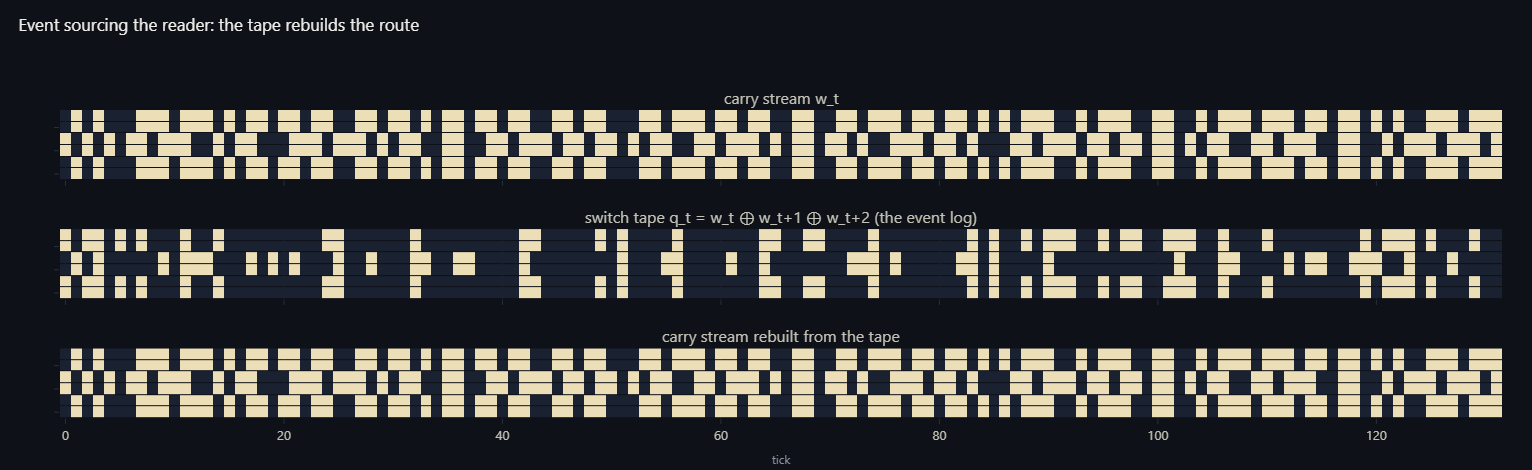

In [25]:
r3 = lab._R3.get("r")
rows = [("R1 · the bare sign", "6", "yes", "yes, tick 3", "no: all 6 steps collapsed", "memory"),
        ("R2 · one-lap", "132", "yes", "no: no empty field before home", "yes: 48 real steps", "twist"),
        ("R3 · two-lap", "{:,}".format(r3["period"]) if r3 else "43,155,322", "no",
         "yes, tick {:,}".format(r3["vacuum"][0]) if r3 else "yes, tick 21,577,661",
         "yes: {:,} real steps".format(rc.census_from_pairs(r3["pairs"], 4)["real"]) if r3 else "yes: 28,829,490 real steps", "diagonal")]
display(HTML(rv.card("The property triangle: each class holds exactly two of three",
                     rv.table(["class", "period", "diagonal P(w) = C(w)", "twist at the half period", "memory bends the carry", "missing"], rows),
                     kicker="closures", accent=rv.YELLOW)))
run_r2, _ = rc.run_reader(6, 0, 0b001100, 132)
W = [r["w"] for r in run_r2]
q = rc.switch_tape(W)
Wr = rc.rebuild_from_tape(q, seed=W[0], n=6)
rv.show(rv.fig_event_log(W, q, Wr, 6))
display(HTML(rv.card("Event sourcing", "T = 132 is divisible by 3, so the tape needs one seed word: w₁ = P(w₀) binds the kernel. "
                     "Rebuilt stream equals the run: <b>%s</b>. The two light seeds 0 and u emit the same blank tape; the two-lap "
                     "closure (T ≡ 1 mod 3) rebuilds from its tape alone." % (Wr == W), status="RUNS" if Wr == W else "FAIL")))

## 12 · Collision, Law 3 and ports

A second reader on the same field. All change is equal, so no reader goes first: every reader reads the old field, then every write lands,

$$x_i=D[p_i]\oplus w_i,\quad p_i'=p_i\oplus x_i,\quad w_i'=P(x_i),\quad D'[q]=D[q]\oplus\bigoplus_{i:\,p_i=q}w_i' .$$

On the two-shell carrier the partner gains one quadratic term, $P_5=A_5\oplus(1\oplus\ell_0\ell_1)u$, and the collision law follows for any number of readers:

$$\mathcal Q=B_D\oplus A_5\Bigl(\bigoplus_ip_i\Bigr),\qquad \mathcal Q'\oplus\mathcal Q=\Bigl((m\bmod2)\oplus\bigoplus_i\ell_0(x_i)\,\ell_1(x_i)\Bigr)u .$$

**Law 3.** *A collision is equal and opposite on the record: the field's record plus the readers' combined position is conserved in every collision except along the complement $u$. That one bit is a clock for a lone reader, cancels between readers on one shell, and is flipped only where two shells meet.*

Each reader's position lamps and carry lamps stay parallel; the cell under a reader is the only thing that can turn it. A released pair stands at separation $r_0$ or $r_0\oplus u$. The Shared Start pair $A=(0,e_R)$, $B=(0,o_R)$ never stands on $\mathrm{Fix}_1=\{5,10,21,26\}$. One aimed write opens it: reverse the gap from the destination to the required read, to the required deposit, to the depositor's prior state, and a third reader $C_0=(4,7)$ lands $A$ on word 5 at tick 3. The read cannot be refused; the record is conserved, and the inverse brings all three readers home.

id,status,statement,scope,expected,actual,source,time
L-01,▶ RUNS,Joint step: exact inverse; Law 3 charge Q' xor Q = ((m mod 2) xor sum l0 l1(x_i)) u; collision cell law,"60,000 random ticks, 1-4 readers, shared starts and populated fields",inverse; charge law; cell law,inverse True · charge True · cell True,"(5.1), (5.2), (5.5)",0.84s
L-02,▶ RUNS,Lamp alignment: aligned readers and cells stay aligned,"80 aligned random states x 600 ticks, 1-4 readers",preserved,holds,(5.7)-(5.8),0.57s
L-03,▶ RUNS,Release separation: at every empty field a pair stands at separation r0 or r0 xor u,"120 random pairs x 12,000 ticks (4,723 empty-field ticks)",r0 or r0 ⊕ u,holds,(5.6),1.83s
L-04,▶ RUNS,"Directed port C = (4,7): A lands on 5 at tick 3 and the three steps invert exactly; the symmetric third reader C = (0,0) writes D[10] = 10 at tick 3","Shared Start A = (0, eR), B = (0, oR)","A at 5 on tick 3; inverse exact; D[10] = 10; derived seed (4, 7)","A at 5; inverse True; D[10] = 10; derived seed (4, 7)","(5.9), §5.6; GPT seal f5375705",0.00s


tick,"A (p, w)","B (p, w)","C (p, w)",D[3],D[10]
0,"(0, 1)","(0, 4)","(4, 7)",0,0
1,"(1, 2)","(4, 8)","(3, 11)",0,0
2,"(3, 1)","(7, 19)","(8, 7)",7,0
3,"(5, 9)","(20, 3)","(15, 11)",14,0


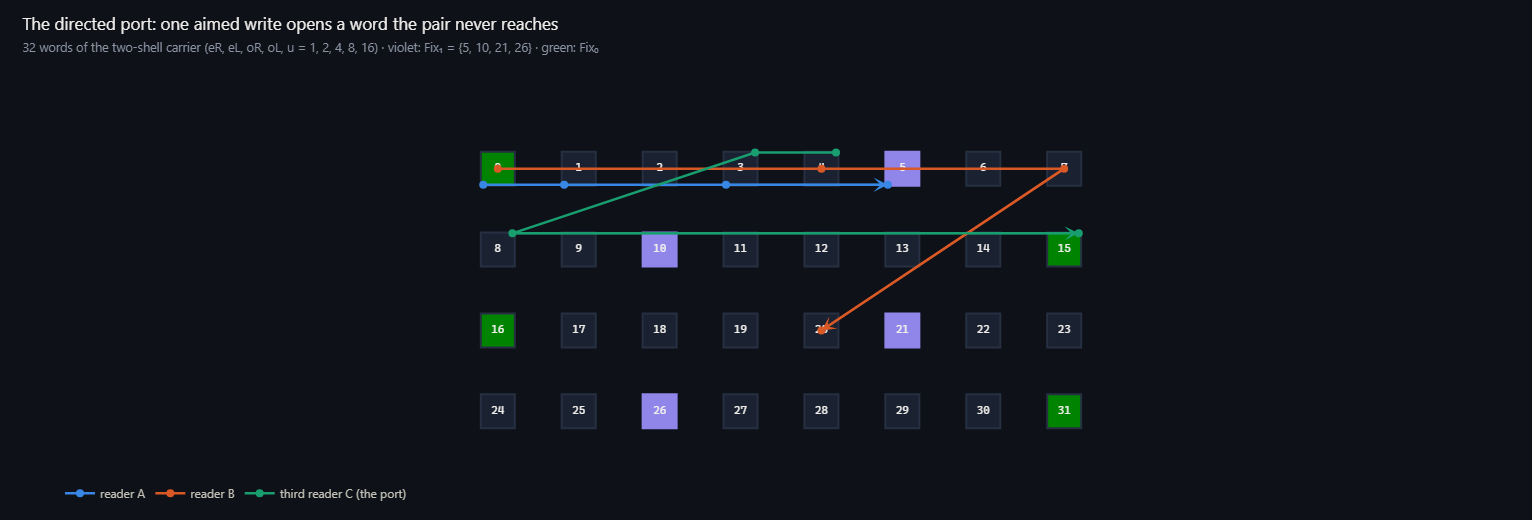

In [26]:
ui.show_checks("L-01", "L-02", "L-03", "L-04")
prow, inv = rc.port_trace((4, 7), 3)
nrow, _ = rc.port_trace((0, 0), 3)
tab = [(r["t"], "%s" % (r["A"],), "%s" % (r["B"],), "%s" % (r["C"],), r["D"][3], r["D"][10]) for r in prow]
display(HTML(rv.card("The sealed directed port C₀ = (4, 7)", rv.table(["tick", "A (p, w)", "B (p, w)", "C (p, w)", "D[3]", "D[10]"], tab, mono_cols=(0, 1, 2, 3, 4, 5))
                     + "<p>Three steps back recover the three readers and the empty field exactly: <b>%s</b>. The symmetric third reader "
                       "C = (0, 0) writes D[10] = %d at tick 3 and leaves A at %d: a write that misses the read address changes nothing for A.</p>"
                       % (inv, nrow[-1]["D"][10], nrow[-1]["A"][0]), kicker="(5.9)", status="RUNS" if prow[-1]["A"][0] == 5 and inv else "FAIL")))
rv.show(rv.fig_port(prow))

> **Legacy sighting, routed.** ZPHC named a forced re-evaluation: a change in one reader caused by another without contact. In the domain it is the directed port: a write into the shared field at the address the other reader must read next. The read cannot be refused, so the re-evaluation is forced; the potential it releases is the other reader's reachable set opening (word 5 lies outside the pair's confinement), and the record is conserved. **RUNS** (L-04). "More energy returned than injected" lands **ELSEWHERE → capacity**: what grows is the reachable set, not the total. How far a chain of aimed writes carries stays **OPEN**.

### ◆ Port lab

Pick a destination word for reader $A$ and a landing tick. The lab derives the third reader backwards, seals the derivation with SHA-256, then runs forward and reports where $A$ landed.

In [27]:
ui.port_lab()

## 13 · Read models: three measurements of one state

A step joins $V_0=p$, $V_1=p\oplus d$, $V_2=p\oplus x$ with sides $d$, $w$, $x$. Because $\operatorname{wt}(a\oplus b)=\operatorname{wt}(a)+\operatorname{wt}(b)-2\operatorname{wt}(a\wedge b)$, a step triangle is right-angled exactly where two sides are disjoint and is never obtuse; on the carrier there is exactly one acute class, $\{2,\,n-1,\,n-1\}$. Measured through both laps of the return,

$$d_*^2(x,y)=\tfrac12\bigl[\operatorname{wt}(x\oplus y)+\operatorname{wt}(A_0(x\oplus y))\bigr],$$

and at width 4 the eight carrier words are the vertices of the regular 16-cell, complement as antipode. The bare sign, read into the carrier by $\Psi_{\mathrm{oct}}$, walks a Petrie hexagon of its octahedral vertex figure.

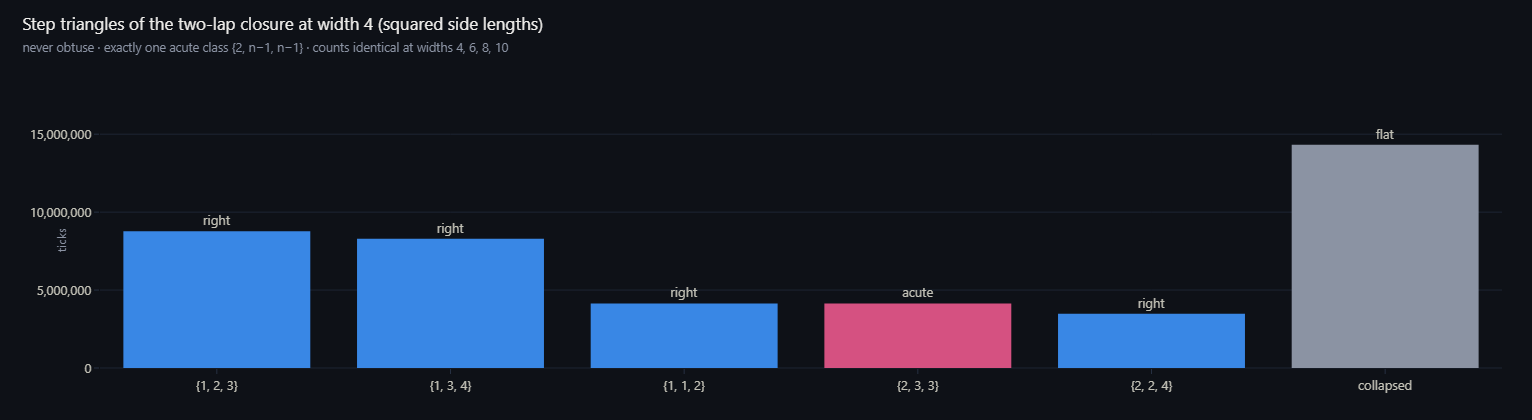

id,status,statement,scope,expected,actual,source,time
V-01,▶ RUNS,"Step triangles of the two-lap closure: never obtuse, one acute class {2, n-1, n-1}, counts identical at widths 4, 6, 8, 10","all 43,155,322 ticks","flat 14,325,832 · real 28,829,490 · right 24,685,355 · acute 4,144,135 · Pi-Ray 8,287,912","flat 14,325,832 · real 28,829,490 · right 24,685,355 · acute 4,144,135 · Pi-Ray 8,287,912","(7.3)-(7.4), T06",0.00s


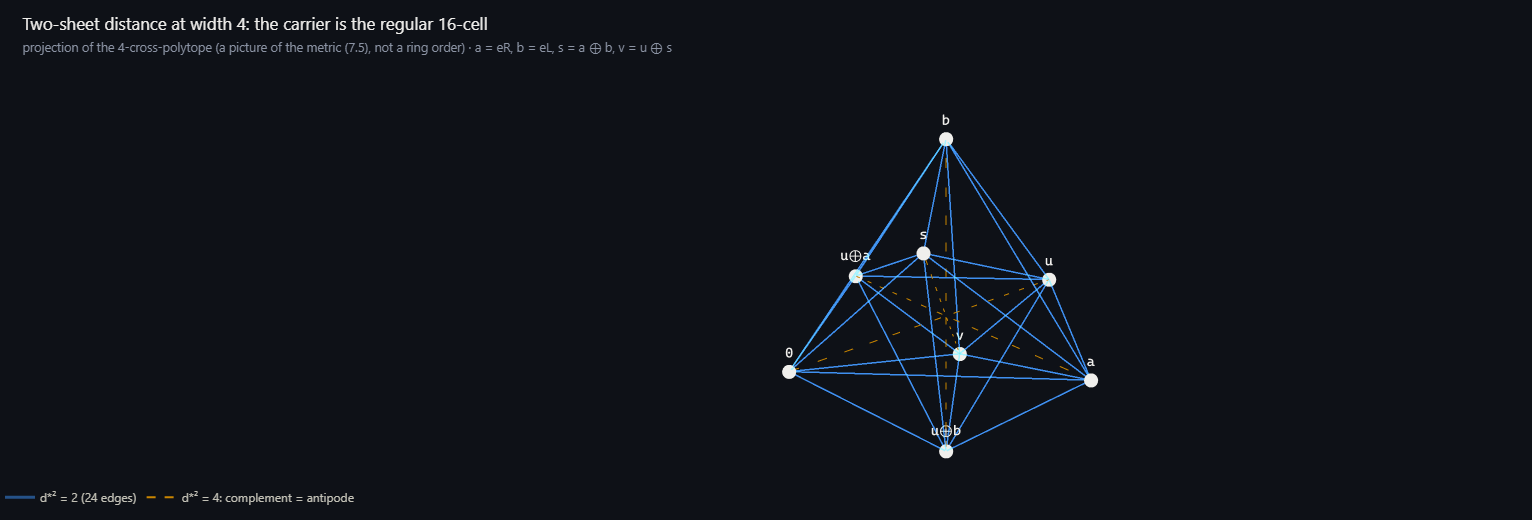

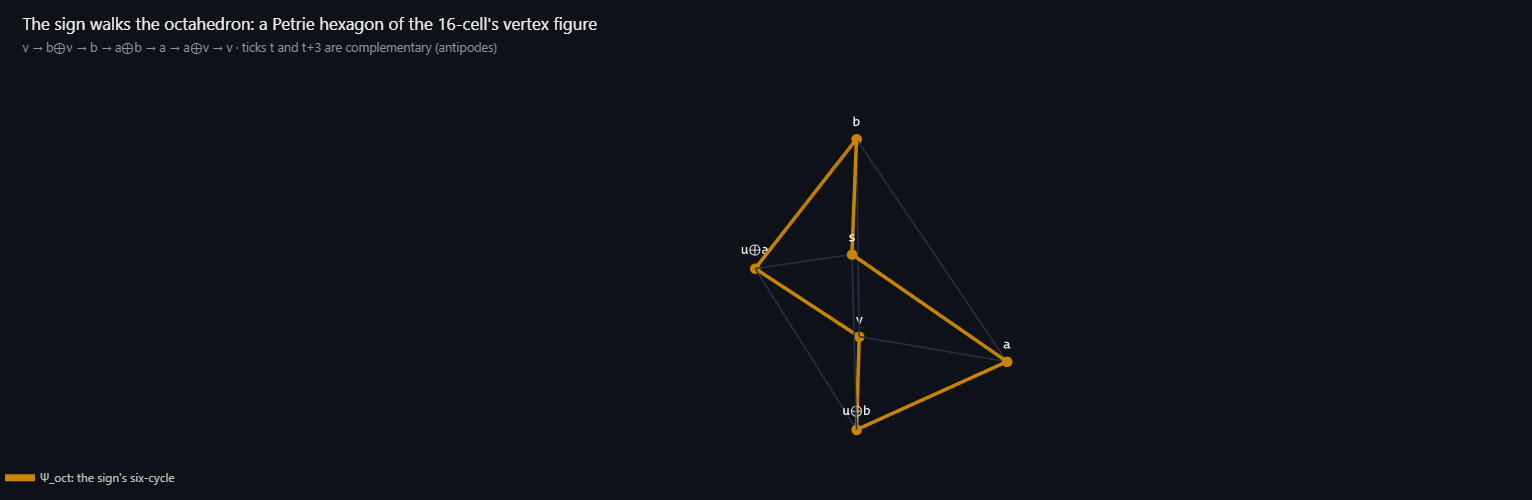

id,status,statement,scope,expected,actual,source,time
V-02,▶ RUNS,"Two-sheet distance at width 4: non-antipodal d*^2 = 2, antipodal 4 (the regular 16-cell)",all 56 ordered pairs,2 / 4,holds,(7.5)-(7.6),0.00s
V-03,▶ RUNS,Psi_oct sends the sign's six-cycle onto the six words other than 0 and u; t and t+3 are complementary; consecutive and two-step pairs are non-antipodal (a Petrie hexagon),the bare sign,"v, b⊕v, b, a⊕b, a, a⊕v","[4, 6, 2, 3, 1, 5]",(7.7)-(7.8),0.00s


In [28]:
r3 = lab._R3.get("r")
if r3:
    rv.show(rv.fig_triangle_census(rc.census_from_pairs(r3["pairs"], 4), 4))
    ui.show_checks("V-01")
else:
    display(HTML(rv.card("Census from the sealed record", "flat 14,325,832 · real 28,829,490 · right 24,685,355 · acute 4,144,135 · Pi-Ray 8,287,912 "
                         "(run with RUN_LONG = True to compute it here)", status="SKIP")))
rv.show(rv.fig_16cell())
rv.show(rv.fig_octahedron())
ui.show_checks("V-02", "V-03")

## 14 · Proof laboratory

The expectation table (published values and derived predictions) is sealed with SHA-256 before any check runs. Then every check runs, or reuses its result from the chapter above, and the report is written beside the notebook as `nexus_ring_atlas_report.json`. A check is **RUNS** only when it executed and landed inside its stated scope.

In [29]:
import json, platform, datetime
seal = lab.seal()
display(HTML(rv.card("Prediction seal", rv.kv([("SHA-256 of the expectation table", seal), ("checks registered", len(lab.REGISTRY))], cols=1),
                     kicker="sealed before the run", accent=rv.YELLOW)))
results = lab.run(include_long=RUN_LONG)
counts = {}
for r in results:
    counts[lab.status_of(r)] = counts.get(lab.status_of(r), 0) + 1
display(HTML(rv.card("Laboratory summary", " ".join(rv.chip(k, "%s %d" % (k, v)) for k, v in sorted(counts.items())),
                     status="RUNS" if counts.get("FAIL", 0) == 0 else "FAIL")))
rows = [(r["id"], lab.status_of(r), r["chapter"], r["statement"], r["scope"], r["expected"], r["actual"], "%.2fs" % r["seconds"]) for r in results]
display(HTML(rv.table(["id", "status", "ch", "statement", "scope", "expected", "actual", "time"], rows, mono_cols=(0, 2), status_col=1, max_height=620)))
report = dict(title="The NEXUS Ring Atlas: proof laboratory", author="Dean A. Kulik, QuHarmonics Research Group, ORCID 0009-0003-3128-8828",
              engine=rc.__version__, seal=seal, expectations=lab.EXPECT, run_long=RUN_LONG,
              generated=datetime.datetime.now(datetime.timezone.utc).isoformat(), python=platform.python_version(),
              results=[{k: (v if isinstance(v, (str, int, float, bool, type(None))) else str(v)) for k, v in r.items()} for r in results])
with open("nexus_ring_atlas_report.json", "w", encoding="utf-8") as fh:
    json.dump(report, fh, indent=1)
print("report written: nexus_ring_atlas_report.json")

id,status,ch,statement,scope,expected,actual,time
G-01,▶ RUNS,1,"On one bit the only fixed-point-free bijection is NOT; on two bits 24 of 256 maps are bijective, 9 have no fixed symbol, and exactly one commutes with exchanging the two bits: the complement",all maps on 1 and 2 bits,"[(1, 0)]; 24; 9; [(3, 2, 1, 0)]","1-bit: [(1, 0)]; 2-bit: 24 bijective, 9 no fixed symbol, symmetric [(3, 2, 1, 0)]",0.00s
R-01,▶ RUNS,2,P is an involution without fixed points; palindromes number 2^ceil(n/2); pairs 2^(n-1),"every word, n = 1-16","P(P(x)) = x, P(x) != x",holds,0.00s
R-02,▶ RUNS,3,"Facing law R[N-1-i] = P(R[i]); seam R[M-1] = u xor eR, R[M] = u xor eL at even n","every slot, n = 2-16",facing law and seam,holds,0.00s
R-03,▶ RUNS,3,The seam word is 1^(floor(n/2)-1) 0 1^(ceil(n/2)) and nests: S(n+2) = 1 S(n) 1,n = 2-16,R_n[M] = seam word; 1·S·1,holds,0.00s
R-04,▶ RUNS,7,"Four providers: x = b m c is a representative iff (b,c) = (0,1), or (0,0) with m <= J(m), or (1,1) with m < J(m); the frame 10 admits nothing","every word, n = 3-14",frame law,holds,0.00s
R-05,▶ RUNS,3,Tape twist: T[L N - 1 - p] = T[p] xor pal(word holding p),"every slice, n = 1-13",palindrome on the tape except on palindromic words,holds,0.00s
R-06,▶ RUNS,3,Every ring is half light (L 2^(L-1) ones); the partner half carries 2^ceil(L/2) more ones than the representative half for L >= 2,n = 1-14 (n = 1 differs by 1: owner the 1-bit ring),L·2^(L-1); 2^ceil(L/2),holds; L=1 imbalance 1,0.00s
R-07,▶ RUNS,3,Merge accounting: sum over words of wt(x xor P(x)) = floor(L/2) 2^L + L 2^ceil(L/2),n = 1-14,closed form,holds,0.00s
A-01,▶ RUNS,4,Exact address without enumeration equals the ring table; unrank inverts it,"rank: every word n = 1-9, 200 words at n = 10-12; 30 unranks per width; round trips at 64, 128, 256 bits",rank = table; unrank∘rank = id,holds,0.45s
A-02,▶ RUNS,4,"The first 64 bits of pi after the binary point sit at address 2,427,008,858,123,944,441 of the 64-bit ring",one 64-bit word,"2,427,008,858,123,944,441","2,427,008,858,123,944,441 (word 0x243F6A8885A308D3)",0.00s


report written: nexus_ring_atlas_report.json


## 15 · Ledger, manifest and what stays OPEN

Every feature of this atlas, its formula, its source paper, its status and the checks that execute it.

In [30]:
rows = [(f, eq, src, " ".join(rv.chip(s.strip()) for s in st.split("·")), ids, where) for f, eq, src, st, ids, where in lab.MANIFEST]
display(HTML(rv.card("Source manifest", rv.table(["feature", "formula", "source", "status", "checks", "where"], rows, mono_cols=(4,)),
                     kicker="dependency chain from each view back to its formula", accent=rv.BLUE)))
display(HTML(rv.card("OPEN, each with its shape", rv.table(["link", "shape of the missing piece"], lab.OPEN_LINKS), status="OPEN")))
rows = [(s, r, rv.chip(st), ids) for s, r, st, ids in lab.LEGACY]
display(HTML(rv.card("Legacy sightings, read through the ring", rv.table(["earlier sighting", "route in the domain", "status", "checks"], rows),
                     kicker="earlier work routed, never rewritten", accent=rv.MAGENTA)))
display(HTML(rv.card("Adapter readings (PULL)", rv.table(["physical reading", "domain element"], lab.ADAPTER_READINGS)
                     + "<p>The domain is complete without these readings; each is held as a comparator and names the domain element it reads.</p>",
                     status="PULL")))

feature,formula,source,status,checks,where
Partner: fixed-point-free involution,(1.1)-(1.2),Only Addressable; Retained Continuation,✔ STANDS ▶ RUNS,R-01,Ch 2 · word inspector
"Ring order, facing law, seam, center carrier",(1.3)-(1.5),Only Addressable; Retained Continuation,✔ STANDS ▶ RUNS,R-02 R-03,Ch 3 · ring explorer
"Tape twist, light balance, merge accounting","Routes 2, 8",Where Yes and No Become Maybe,▶ RUNS,R-05 R-06 R-07,Ch 3 · disks
Address as a comparison; exact rank and unrank at any width,(1.6)-(1.7),Against Its Own Reverse; Only Addressable,✔ STANDS ▶ RUNS,A-01 A-02,Ch 4
Borrow cell; the comparator is one address bit,(1.8)-(1.9),Against Its Own Reverse,✔ STANDS ▶ RUNS,A-03 A-04,Ch 4
Sphere reading; Pi-Ray,"(1.10), (7.1)-(7.2)",Against Its Own Reverse; The Retained Continuation Domain,✔ STANDS ▶ RUNS,S-01 S-02,Ch 5
Folded square; density line; parabola; tent; centres of mass,(1.11),Where Yes and No Become Maybe,▶ RUNS,F-01 F-02,Ch 6
Four providers; continuation depth; codec; attractors,(1.12),Where Yes and No Become Maybe,▶ RUNS,R-04 C-01 C-02 C-03,Ch 7
Radial reader; frame law; one angle for every depth; seam profiles; square-root front half; radial language,"§2, §4, §5",Mapping the Nested Partner Ring; Where Yes and No Become Maybe,▶ RUNS,D-01 D-02 D-03 D-04 D-05,Ch 8 · the Ring Reader
Boolean Möbius bridge MD = SA; lossless rebuild,(1.13),Bicomplex Difference Calculus,✔ STANDS ▶ RUNS,M-01,Ch 9


link,shape of the missing piece
Route-change accounting,the map from field writes and the acceleration they produce (3.9)-(3.10) to the edit count (3.13)
Return depth from the boundary,"the first empty-field tick and its monodromy for Shared Start, read from the initial relative state without executing"
Chained deposits,"how far one directed write carries: the reachable set of a reader after several aimed writes, as a measured law"
The nine-cell rung,what places a system on the clock of nine cells rather than three or twenty-seven
The frame law above the middle offset,the mechanism for h + 1 ≤ s ≤ L − 2 and the seam cells
The radial language,the growth rate of R_D and the limit of R_D / 2^D
The lap selector,which of the 15 short same-carrier pairings close on which lap
Physical adapters,the angular reading of the half-lap sign; the parity break on the weak-side reading
Lock families,entry into and switching between lock families of the clock


earlier sighting,route in the domain,status,checks
H = π/9 (Mark1),the tick angle of the nine-cell one-inverter clock: its fundamental eigenmode turns 20° per tick,✔ STANDS,K-05 H-01
“Period-18 folding” (ZPHC gap map A3),"the nine-cell lap: τ⁹ = C, τ¹⁸ = I; the 18 spokes of the 20° lattice are the 18 states of one lap",✔ STANDS,K-06 H-01
260/729 (Mark1 empirical anchor),"→ the k = 9 value of the wheel triangle fraction, which crosses π/9 between k = 8 and 9 and tends to 1/2",↪ ELSEWHERE,H-01
H ≈ 0.35 as the setpoint of dH/dt = −k(H − 0.35),→ the adapter layer (a controller steering a reader); the domain ticks at π/9 and steers nothing,↪ ELSEWHERE,
ZPHC: a forced re-evaluation,the directed port: a write at the address another reader must read next; the read cannot be refused,▶ RUNS,L-04
ZPHCR: “more returned than injected”,"→ capacity: the reachable set opens (A reaches word 5, outside the pair's confinement); the record is conserved by the exact inverse",↪ ELSEWHERE,L-04
SILR: drift ≈ 0,"the step is a bijection, so drift is exactly zero; the clock moves latitude by one per tick and nets zero per lap",✔ STANDS,X-01 K-07
GENLOCK: every clock leaks at one rate,the one-inverter clock flips exactly one bit per tick at every width,✔ STANDS,K-07


physical reading,domain element
Light,R1: the twist with nothing kept; blank switch tape; collapsed steps
Matter,"R3: the twist with memory, off the diagonal"
Mass,the kept field k
Inertia,the move price 2k: the cost of moving while keeping one's record
Acceleration,α_t = w_t ⊕ w_t+2 (accounting map OPEN)
Spin,the half-lap sign; two laps to come home (angular adapter OPEN)
Charge,the lamp parities and the charge Q
Action and reaction,"Law 3 (5.5), with the complement as the one exchanged bit"
Confinement,the cross-shell term ℓ0ℓ1u; the 28-word confinement of the Shared Start pair


### Sources

Kulik, D. A. (2026). *Only Addressable: The ring of all binary words: exact location without enumeration, a triangular top, and a law in thirds for what one ray reads.* QuHarmonics Research Group.
Kulik, D. A. (2026). *Decompiling Addressable Binary Rings: Forced involutions, the Möbius difference bridge, and radial witness topologies.*
Kulik, D. A. (2026). *Against Its Own Reverse: One comparison of each binary word with its reverse builds the ring's address, its sphere and its waveform.*
Kulik, D. A. (2026). *Where Yes and No Become Maybe: The nested partner ring read as a folded square.*
Kulik, D. A. (2026). *Mapping the Nested Partner Ring: Reading orders, tape frames and a uniform profile witness.*
Kulik, D. A. (2026). *Bicomplex Difference Calculus on Native Binary Rings.*
Kulik, D. A. (2026). *One Inverter: The loop that continuation forces, what its center reads, and compilers locked inside compilers.*
Kulik, D. A. (2026). *Retained Continuation: Three closures of the native binary ring, the two-lap return, and the price of moving a kept field.*
Kulik, D. A. (2026). *Exact Algebra of Retained Continuation.*
Kulik, D. A. (2026). *The Retained Continuation Domain: A Center-Out Specification of the NEXUS Ring Machine.*

*Acknowledgment.* Computation, engine and layout were built with Claude (Anthropic) as a working partner. Results first reached in GPT and Gemini runs are credited in the source papers, and each check here reruns them in one program.

### Export the engine

The four engine modules live inside this notebook. Set `EXPORT_ENGINE = True` to write them beside it as `ring_core.py`, `ring_lab.py`, `ring_viz.py` and `ring_ui.py`, so the mathematics and the laboratory can run without a notebook: `python -c "import ring_lab as l; print(l.run())"`.

In [31]:
EXPORT_ENGINE = False
if EXPORT_ENGINE:
    for _name, _src in (("ring_core", _rc), ("ring_lab", _lab), ("ring_viz", _rv), ("ring_ui", _ui)):
        with open(_name + ".py", "w", encoding="utf-8") as fh:
            fh.write(_src)
    print("written: ring_core.py, ring_lab.py, ring_viz.py, ring_ui.py")